# B2 · Tokenisation et embeddings — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/chapitres/b2_tokenisation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wb.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | B2.Q1 à B2.Q12, B2.R1 à B2.R3, B2.1 à B2.6, B2.9 | vérifier tes réponses courtes | 🧠 🔁 ✏️ 🧮 | ★ à ★★ | |
| A | B2.13 | Tokenizers réels : GPT-2, BERT et un tokenizer multilingue sur Holmes et Verne | 📦 | ★★ | 20 |
|  | B2.14 | Prédire : quel texte coûte le plus de tokens, Holmes, Verne, des nombres ou des emoji ? | 🔮 | ★ | 10 |
| B | B2.15 | get_pair_counts et merge_pair | 🔨 | ★★ | 20 |
|  | B2.16 | BPETokenizer.fit : apprendre les fusions, au niveau caractère puis octet | 🔨 | ★★★ | 50 |
|  | B2.17 | encode et decode : fusions appliquées par rang, aller-retour sans perte | 🔨 | ★★★ | 40 |
|  | B2.18 | Le tokenizer qui abîme les accents : trois bugs d'Unicode et de fusions | 🐛 | ★★ | 25 |
|  | B2.19 | Ton BPE contre la bibliothèque tokenizers : mêmes fusions, autre vitesse | 📦 | ★★ | 25 |
| C | B2.20 | Taille du vocabulaire : compression et entropie par token, de 300 à 8 000 tokens | 🔬 | ★★★ | 40 |
|  | B2.21 | Tokenizer entraîné sur Holmes, appliqué à Verne (et l'inverse) : le coût de la langue | 🔬 | ★★ | 25 |
| D | B2.22 | cooccurrence_matrix et ppmi | 🔨 | ★★ | 30 |
|  | B2.23 | cosine_similarity_matrix et most_similar | 🔨 | ★★ | 20 |
|  | B2.24 | Embeddings PPMI + SVD sur Holmes : les voisins de « Holmes », « Watson » et « letter » | 📦 | ★★ | 30 |
|  | B2.25 | word2vec (skip-gram, échantillonnage négatif) en PyTorch sur Verne | 📦 | ★★★ | 60 |
|  | B2.26 | Prédire les voisins de « Fogg » et de « Passepartout » avant de les calculer | 🔮 | ★ | 10 |
|  | B2.27 | Lire une carte PCA/UMAP d'embeddings : groupes, axes et effet de la fréquence | 📈 | ★★ | 20 |
| E | B2.28 | Embeddings de phrases (MiniLM, mean pooling) et recherche sémantique dans Holmes | 📦 | ★★ | 30 |
|  | B2.29 | Statique contre contextuel : le même mot dans deux phrases | 🔬 | ★★ | 25 |
|  | B2.30 | Sauvegarder un tokenizer en JSON et écrire son test de non-régression | 🛠️ | ★★ | 20 |
|  | B2.31 | Défi : la meilleure compression sans perte de Verne avec 2 000 tokens, en moins de 2 min de CPU | 🏆 | ★★★★ | 90 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Manipuler Unicode, UTF-8 et la normalisation d'un texte, et compter ses octets et ses points de code.
- Écrire un tokenizer BPE (entraînement, encodage par rang, décodage) et le comparer à la bibliothèque `tokenizers`.
- Comparer des tokenizers réels et mesurer leur coût (fertilité, compression) selon la langue.
- Relier `nn.Embedding` à un produit one-hot × table, et entraîner des embeddings word2vec.
- Construire des embeddings par co-occurrences (PPMI et SVD), les interroger par le cosinus, et chercher des passages par des embeddings de phrases.

**Rappel express.** Fertilité $= \frac{\text{tokens}}{\text{mots}}$, compression $= \frac{\text{octets}}{\text{tokens}}$. Fusion BPE : la paire voisine la plus fréquente (à égalité, la plus petite paire d'identifiants) devient un token ; on encode en appliquant les fusions par rang. $\mathbf{x}_{\text{one-hot}}^\top \mathbf{E} = \mathbf{E}[i, :]$. $\operatorname{PPMI}(w, c) = \max\big(0, \log \frac{p(w, c)}{p(w)\,p(c)}\big)$. Skip-gram : $L = -\log \sigma(\mathbf{u}_c^\top \mathbf{v}_w) - \sum_k \log \sigma(-\mathbf{u}_{n_k}^\top \mathbf{v}_w)$. Mean pooling : $\mathbf{s} = \frac{\sum_t m_t \mathbf{h}_t}{\sum_t m_t}$.

## Partie 0 · Vérifier tes réponses courtes (quiz, rappels, ✏️ B2.1 à B2.6, 🧮 B2.9)

Fais d'abord les quiz, les rappels et les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse courte ici : **la valeur** que tu as trouvée, pas l'expression Python, sinon tu ne vérifies rien. Un nombre : `42` ou `0.3` (en Python, le séparateur décimal est un **point** ; `0,3` sans guillemets serait un couple de deux nombres) ; un vrai ou faux : `True` ou `False` ; un choix : la lettre seule, entre guillemets (`"B"`) ; une forme de tenseur : entre guillemets (`"(2, 3)"`) ; un mot : entre guillemets (`"mot"`) ; des octets : une liste, en hexadécimal ou en décimal (`[0x4E, 0x6F]` ou `[78, 111]`) ; des identifiants, une paire d'identifiants ou un vecteur : une liste (`[4, 0, 7]`). Arrondis comme l'énoncé le demande, et seulement à la fin du calcul. Les réponses pas encore remplies affichent ⏳. Les questions « dans ta copie », la dérivation ∂ B2.7, l'estimation 🧮 B2.8, la réflexion (🗣️ B2.10, ⚖️ B2.11, 📄 B2.12) et l'entretien se corrigent avec `05_solutions.md`.

In [2]:
# The short answers only use the numbers of their statements (02_exercices.md)
import math
import unicodedata

import numpy as np

# 🧠 Q2: « é » in NFC (one code point) and in NFD (« e » + U+0301)
E_ACUTE_NFC = "\u00e9"
E_ACUTE_NFD = unicodedata.normalize("NFD", E_ACUTE_NFC)

# ✏️ B2.1: « Noël à Paris », typed in NFC
S_B21 = "No\u00ebl \u00e0 Paris"
B_B21 = S_B21.encode("utf-8")
NFD_B21 = unicodedata.normalize("NFD", S_B21)


def utf8_two_bytes(code_point):
    """110xxxxx 10xxxxxx: the 5 high bits, then the 6 low bits of an 11-bit code point (U+0080 to U+07FF)."""
    return [0b11000000 | (code_point >> 6), 0b10000000 | (code_point & 0b111111)]


# ✏️ B2.2: toy vectors (axes: royalty, masculine (+) or feminine (-), adult), « homme est à roi ce que femme est à ? »
WORDS_B22 = ["roi", "reine", "homme", "femme", "prince", "princesse", "trône"]
E_B22 = np.array([[0.6, 1.0, 0.9], [0.8, -0.5, 0.9], [0.1, 1.0, 0.9], [0.1, -1.0, 0.9],
                  [0.7, 0.8, 0.2], [0.7, -0.6, 0.2], [3.0, 0.0, 0.5]])
Q_B22 = E_B22[0] - E_B22[2] + E_B22[3]
COS_B22 = E_B22 @ Q_B22 / (np.linalg.norm(E_B22, axis=1) * np.linalg.norm(Q_B22))
E_UNIT_B22 = E_B22 / np.linalg.norm(E_B22, axis=1, keepdims=True)


def analogy_b22(E, a, b, c, exclude=True, cosine=True):
    """The word x of largest cos(x, b - a + c) (or dot product), without a, b and c when exclude is True."""
    k = {w: i for i, w in enumerate(WORDS_B22)}
    q = E[k[b]] - E[k[a]] + E[k[c]]
    scores = E @ q / (np.linalg.norm(E, axis=1) * np.linalg.norm(q)) if cosine else E @ q
    order = [i for i in np.argsort(-scores, kind="stable") if not (exclude and WORDS_B22[i] in (a, b, c))]
    return WORDS_B22[order[0]]


# ✏️ B2.3: three BPE merges by hand; ties go to the smallest pair of ids (BpeTrainer of tokenizers)
CORPUS_B23 = {"été": 4, "étés": 3, "pré": 2, "prés": 1}


def merge_ids(ids, pair, new_id):
    """Replace each occurrence of pair, left to right and without overlap, by new_id."""
    out, i = [], 0
    while i < len(ids):
        if i + 1 < len(ids) and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def learn_bpe(corpus, n_merges):
    """The fiche's pseudo-code: alphabet sorted by code point, then n_merges merges (pair of ids) with their counts."""
    alphabet = sorted({ch for word in corpus for ch in word})
    words = {tuple(alphabet.index(ch) for ch in word): f for word, f in corpus.items()}
    merges, counts = [], []
    for _ in range(n_merges):
        pairs = {}
        for word, f in words.items():
            for pair in zip(word, word[1:]):
                pairs[pair] = pairs.get(pair, 0) + f
        best = min(pairs, key=lambda p: (-pairs[p], p))           # most frequent, then the smallest pair of ids
        merges.append(best)
        counts.append(pairs[best])
        words = {tuple(merge_ids(list(w), best, len(alphabet) + len(merges) - 1)): f for w, f in words.items()}
    return alphabet, merges, counts, words


ALPHABET_B23, MERGES_B23, COUNTS_B23, WORDS_AFTER_B23 = learn_bpe(CORPUS_B23, 3)
TOKENS_AFTER_B23 = sum(len(word) * f for word, f in WORDS_AFTER_B23.items())

# ✏️ B2.4: a BPE already learned (char level), applied by rank; an unseen character becomes <unk>
ALPHABET_B24 = list("acehnorst")
MERGES_B24 = [("n", "t"), ("c", "h"), ("a", "nt"), ("o", "n"), ("ch", "ant"), ("e", "r"), ("on", "s"),
              ("chant", "er")]
VOCAB_B24 = {ch: i for i, ch in enumerate(ALPHABET_B24)}
for _a, _b in MERGES_B24:
    VOCAB_B24[_a + _b] = len(VOCAB_B24)
UNK_B24 = len(VOCAB_B24)                                             # the special token comes after the merges
RANK_B24 = {(VOCAB_B24[a], VOCAB_B24[b]): (r, VOCAB_B24[a + b]) for r, (a, b) in enumerate(MERGES_B24)}


def encode_b24(word, by_rank=True):
    """Merge the adjacent pair of lowest rank (by_rank) or, the classic mistake, the leftmost known pair."""
    ids = [VOCAB_B24.get(ch, UNK_B24) for ch in word]
    while True:
        present = [(RANK_B24[p][0], i) for i, p in enumerate(zip(ids, ids[1:])) if p in RANK_B24]
        if not present:
            return ids
        _, i = min(present) if by_rank else min(present, key=lambda t: t[1])
        ids[i:i + 2] = [RANK_B24[(ids[i], ids[i + 1])][1]]


# ✏️ B2.5: one-hot times a table, and the gradient of L = sum over the positions t of w . e_t
E_B25 = np.array([[1, 0, 2], [0, 1, -1], [2, -1, 0], [-1, 3, 1], [0, 2, 2]], dtype=float)
IDS_B25 = [3, 0, 3, 1]
W_B25 = np.array([1.0, -2.0, 0.5])
X_B25 = np.eye(5)[IDS_B25]                                           # one one-hot row per position: (4, 5)
OUT_B25 = X_B25 @ E_B25                                              # (4, 3)
L_B25 = float((OUT_B25 @ W_B25).sum())
GRAD_B25 = X_B25.T @ np.tile(W_B25, (len(IDS_B25), 1))               # dL/dE = X^T dL/dOUT, shape (5, 3)
LR_B25 = 0.1

# ✏️ B2.6: co-occurrences in a window of 1, ids in alphabetical order (chat 0, court 1, le 2, rat 3)
WORDS_B26 = ["chat", "court", "le", "rat"]
IDS_B26 = [WORDS_B26.index(w) for w in "le chat court le chat le rat court".split()]
C_B26 = np.zeros((4, 4))
for _i in range(len(IDS_B26) - 1):
    C_B26[IDS_B26[_i], IDS_B26[_i + 1]] += 1                         # right context
    C_B26[IDS_B26[_i + 1], IDS_B26[_i]] += 1                         # left context
N_B26 = C_B26.sum()


def pmi_b26(w, c, alpha=1.0, alpha_rows=False):
    """log p(w, c) / (p(w) p_alpha(c)); alpha_rows smooths the rows too (a classic mistake)."""
    i, j = WORDS_B26.index(w), WORDS_B26.index(c)
    rows = C_B26.sum(axis=1) ** (alpha if alpha_rows else 1.0)
    cols = C_B26.sum(axis=0) ** alpha
    return math.log((C_B26[i, j] / N_B26) / ((rows[i] / rows.sum()) * (cols[j] / cols.sum())))


P_ALPHA_B26 = C_B26.sum(axis=0) ** 0.75 / (C_B26.sum(axis=0) ** 0.75).sum()

# 🧮 B2.9: embedding tables (config.json and safetensors headers of the Hugging Face Hub, read on 2026-11-01)
GPT2_TABLE_B29 = 50257 * 768
GPT2_TOTAL_B29 = 124_439_808                                         # GPT-2 small, its tied head counted once
L31_TABLE_B29 = 128256 * 4096                                        # Llama 3.1 8B, untied: two tables
L31_TOTAL_B29 = 8_030_261_248
L32_TABLE_B29 = 128256 * 2048                                        # Llama 3.2 1B, tied: one table
L32_TOTAL_B29 = 1_235_814_400

# quizzes and recalls with a computation
WP_AB_Q7 = 20 / (40 * 100)                                          # WordPiece score count(a, b) / (count(a) count(b))
WP_CD_Q7 = 30 / (300 * 200)
PMI_Q10 = math.log(6 * 1000 / (30 * 200))                           # p(w, c) / (p(w) p(c)), N simplified
H_Q11 = np.array([[1.0, 2.0], [3.0, 0.0], [2.0, 4.0], [0.0, 0.0]])   # the last position is a [PAD]
M_Q11 = np.array([1.0, 1.0, 1.0, 0.0])
S_Q11 = (M_Q11[:, None] * H_Q11).sum(axis=0) / M_Q11.sum()
P_R3 = np.array([0.5, 0.25, 0.125, 0.125])
H_R3 = float(-(P_R3 * np.log2(P_R3)).sum())

# The same answers from the libraries (no download): mylearn (reference), tokenizers, PyTorch
import warnings

warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)
import torch
from tokenizers import Tokenizer, models, pre_tokenizers, trainers
from torch import nn

assert len(E_ACUTE_NFC.encode()) == 2 and len(E_ACUTE_NFD) == 2 and len(E_ACUTE_NFD.encode()) == 3
assert len("\u2019".encode()) == 3 and len("\u4e2d".encode()) == 3
assert utf8_two_bytes(0xEB) == list("\u00eb".encode()) and utf8_two_bytes(0x153) == list("\u0153".encode())

T = mylearn.tokenizer
# ✏️ B2.3: the merges of BpeTrainer and of BPETokenizer, char level, Whitespace pre-tokenizer
text_b23 = " ".join(w for w, f in CORPUS_B23.items() for _ in range(f))
ref_b23 = T.BPETokenizer(vocab_size=len(ALPHABET_B23) + 3, level="char", min_frequency=1).fit(text_b23)
assert ref_b23.merges_ == MERGES_B23 and ref_b23.n_base_ == len(ALPHABET_B23)
hf_b23 = Tokenizer(models.BPE())
hf_b23.pre_tokenizer = pre_tokenizers.Whitespace()
hf_b23.train_from_iterator([text_b23], trainers.BpeTrainer(vocab_size=len(ALPHABET_B23) + 3, min_frequency=1,
                                                           show_progress=False))
assert [hf_b23.token_to_id(ch) for ch in ALPHABET_B23] == list(range(len(ALPHABET_B23)))
assert [hf_b23.token_to_id(ref_b23.vocab_[a].decode() + ref_b23.vocab_[b].decode()) for a, b in MERGES_B23] == [5, 6, 7]
for min_frequency, n in ((3, 3), (4, 2)):                             # 🧠 B2.3 h): the stopping rule
    assert len(T.BPETokenizer(vocab_size=8, level="char", min_frequency=min_frequency).fit(text_b23).merges_) == n

# ✏️ B2.4: the same merges in models.BPE and in BPETokenizer (attributes set by hand)
hf_b24 = Tokenizer(models.BPE(vocab=dict(VOCAB_B24, **{"<unk>": UNK_B24}), merges=MERGES_B24, unk_token="<unk>"))
ref_b24 = T.BPETokenizer(level="char", unk_token="<unk>")
ref_b24.n_base_, ref_b24.special_ids_ = len(ALPHABET_B24), {"<unk>": UNK_B24}
ref_b24.merges_ = [(VOCAB_B24[a], VOCAB_B24[b]) for a, b in MERGES_B24]
ref_b24.vocab_ = {i: s.encode() for s, i in VOCAB_B24.items()} | {UNK_B24: b"<unk>"}
for word in ("chantons", "ont", "chanteront", "chantez", "enchanter", "chantonner"):
    assert encode_b24(word) == hf_b24.encode(word).ids == ref_b24.encode(word), word
assert encode_b24("ont", by_rank=False) != encode_b24("ont")
byte_b24 = T.BPETokenizer(vocab_size=256, pre_tokenizer="gpt2").fit("x")       # 256 bytes, no merge
assert len(byte_b24.encode("été")) == 5 and ref_b24.decode(ref_b24.encode("chantez")) != "chantez"

# ✏️ B2.5: nn.Embedding, its gradient, padding_idx and the weight decay of SGD
emb = nn.Embedding(5, 3)
with torch.no_grad():
    emb.weight.copy_(torch.tensor(E_B25))
ids = torch.tensor(IDS_B25)
x = nn.functional.one_hot(ids, num_classes=5).double()
assert torch.allclose(x @ emb.weight.double(), emb(ids).double()) and np.allclose(emb(ids).detach(), OUT_B25)
loss = (emb(ids) @ torch.tensor(W_B25, dtype=torch.float32)).sum()
loss.backward()
assert np.isclose(loss.item(), L_B25) and np.allclose(emb.weight.grad, GRAD_B25)
torch.optim.SGD(emb.parameters(), lr=LR_B25).step()
assert np.allclose(emb.weight.detach()[3], E_B25[3] - LR_B25 * GRAD_B25[3])
pad = nn.Embedding(5, 3, padding_idx=0)
(pad(ids) @ torch.tensor(W_B25, dtype=torch.float32)).sum().backward()
assert torch.all(pad.weight.grad[0] == 0)
decay = nn.Embedding(5, 3)
before = decay.weight.detach().clone()
(decay(ids) @ torch.tensor(W_B25, dtype=torch.float32)).sum().backward()
torch.optim.SGD(decay.parameters(), lr=LR_B25, weight_decay=0.01).step()
assert not torch.equal(decay.weight.detach()[4], before[4])

# ✏️ B2.6: cooccurrence_matrix and ppmi of the reference
Em = mylearn.embeddings
assert np.array_equal(Em.cooccurrence_matrix(IDS_B26, 4, window=1), C_B26)
P1, P75 = Em.ppmi(C_B26), Em.ppmi(C_B26, alpha=0.75)
assert np.isclose(P1[0, 2], pmi_b26("chat", "le")) and P1[1, 2] == 0 and pmi_b26("court", "le") < 0
assert np.isclose(P75[0, 2], pmi_b26("chat", "le", 0.75)) and P75[1, 2] > 0 and not np.allclose(P75, P75.T)

# ✏️ B2.2: most_similar of the reference, with and without the exclusion
i22 = {w: i for i, w in enumerate(WORDS_B22)}
assert WORDS_B22[Em.most_similar(E_B22, Q_B22, k=1)[0][0]] == analogy_b22(E_B22, "homme", "roi", "femme", exclude=False)
assert WORDS_B22[Em.most_similar(E_B22, Q_B22, k=1, exclude=(i22["homme"], i22["roi"], i22["femme"]))[0][0]] == "reine"

# 🧮 B2.9: GPT-2 small built without its weights (meta device)
from transformers import GPT2Config, GPT2LMHeadModel
with torch.device("meta"):
    gpt2 = GPT2LMHeadModel(GPT2Config())
assert sum(p.numel() for p in gpt2.parameters()) == GPT2_TOTAL_B29
assert gpt2.transformer.wte.weight.numel() == GPT2_TABLE_B29 and gpt2.lm_head.weight is gpt2.transformer.wte.weight

# 🔁 R2 and R3: build_vocab, encode (ch. 22), entropy and Huffman (ch. 6)
S = mylearn.sequences
stoi, itos = S.build_vocab("banana")
assert stoi["b"] == 2
stoi_u, _ = S.build_vocab("banana", unk_token="<unk>")
assert S.encode("bandana", stoi_u, unk_token="<unk>").tolist() == [3, 1, 2, 0, 1, 2, 1]
stoi_w, itos_w = S.build_vocab(["le", "chat", "le", "rat"], max_size=2, unk_token="<unk>")
assert S.encode(["chat"], stoi_w, unk_token="<unk>").tolist() == [0]
assert np.isclose(mylearn.info.entropy(P_R3), H_R3)
assert min(len(c) for c in mylearn.info.huffman_code(list("abcd"), P_R3).values()) == 1
print("✅ the paper answers agree with mylearn (reference), tokenizers and PyTorch")

✅ the paper answers agree with mylearn (reference), tokenizers and PyTorch


**B2.Q1 — Caractères, mots ou sous-mots : taille du vocabulaire contre longueur des séquences**

In [3]:
wb.record("B2.Q1a", "A", mistakes={"un mot entier est un seul token : relis la colonne « longueur des séquences »": "B", "les sous-mots sont entre les deux : relis le tableau des trois granularités": "C"})
wb.record("B2.Q1b", True, mistakes={"relis ce que devient un mot qui n'est pas parmi les V plus fréquents (§202.1)": False})
wb.record("B2.Q1c", 3 ** 2, mistakes={"le coût croît comme le carré de la longueur, pas comme la longueur": 3,
          "tu as doublé au lieu d'élever au carré": 6,
          "le carré de la longueur, pas son cube": 27})
wb.record("B2.Q1d", "B", mistakes={"personne ne choisit les morceaux à la main : relis d'où vient le découpage": "A", "les morceaux n'ont pas de longueur fixe : relis l'exemple de « paisiblement »": "C"})
wb.record("B2.Q1e", False, mistakes={"relis le tableau des trois granularités : combien de symboles distincts à chaque niveau ?": True})

WB_ANSWER {"hash": "e409042f12dbb0a0c98cc8712cac692ca9359e061d70b21ec5017d3fc60d7a53", "id": "B2.Q1a", "kind": "str", "mistakes": {"34484e9283426b8754ddd4418545f93684e57b11a84243e68226a415260b7f55": "un mot entier est un seul token : relis la colonne « longueur des séquences »", "4e1c8a7750c65060cfaf8677b0a93ce23f42ab629ccf25d840e8d0d109ac45a0": "les sous-mots sont entre les deux : relis le tableau des trois granularités"}}
📝 Ex B2.Q1a : réponse enregistrée (str).
WB_ANSWER {"hash": "3bfa7f40abe1dd42f341d809889c22795d2c342ce705490a2b2bcb071a61398b", "id": "B2.Q1b", "kind": "bool", "mistakes": {"d118f5223c7b349d78b5ecf8315c0e177211d9638861b630ad1536efca2f286c": "relis ce que devient un mot qui n'est pas parmi les V plus fréquents (§202.1)"}}
📝 Ex B2.Q1b : réponse enregistrée (bool).
WB_ANSWER {"hash": "2231eb484c560f65199aa2062fc3e6b27cd664709be63d4cbb56f5c04afb3369", "id": "B2.Q1c", "kind": "int", "magnitude": 0, "mistakes": {"36201ba999407ce8330ad80f2c00d65f8c6d090887ffe83b28bc01edbc2

**B2.Q2 — Octets, points de code, caractères affichés : combien « é » compte-t-il ?**

In [4]:
wb.record("B2.Q2a", len(E_ACUTE_NFC.encode('utf-8')), mistakes={"« é » n'est pas un caractère ASCII : relis le tableau d'UTF-8": 1,
          "relis les plages du tableau d'UTF-8 : dans laquelle tombe U+00E9 ?": 3})
wb.record("B2.Q2b", len(E_ACUTE_NFD), mistakes={"relis ce que fait NFD d'une lettre accentuée": 1,
          "on compte ici des points de code, pas des octets": 3})
wb.record("B2.Q2c", len(E_ACUTE_NFD.encode('utf-8')), mistakes={"compte les octets de chacun des deux points de code": 2,
          "recompte les octets de « e » : dans quelle plage du tableau tombe-t-il ?": 4})
wb.record("B2.Q2d", len(E_ACUTE_NFC), mistakes={"len d'un str compte les points de code, pas les octets": 2})
wb.record("B2.Q2e", False, mistakes={"U+2019 est au-delà de U+07FF : relis les plages du tableau d'UTF-8": True})

WB_ANSWER {"hash": "4f2a13b560d701a209d6a607436f81cd4b9d0c853fdba462da8a2f56994e5dd9", "id": "B2.Q2a", "kind": "int", "magnitude": 0, "mistakes": {"65cee967f07554e15555e0f5b2d61394c2074e8201ee52b988a3022f0d91fb2d": "relis les plages du tableau d'UTF-8 : dans laquelle tombe U+00E9 ?", "8c8b41dab8264873dde739499bb8caf01ff632c65df98c5e38b5e0ca7dac8e88": "« é » n'est pas un caractère ASCII : relis le tableau d'UTF-8"}, "sign": 1}
📝 Ex B2.Q2a : réponse enregistrée (int).
WB_ANSWER {"hash": "3158f540764dd89dd181880744bdd33e47d777a3bf4556ae1fbf1ad7fdae8000", "id": "B2.Q2b", "kind": "int", "magnitude": 0, "mistakes": {"40ff222536af8327c2254d469de8321ede7bb2f6a6f6bccaf113c1fead75986b": "on compte ici des points de code, pas des octets", "9fe338556ad1cb2f47064cf61b1381fba594c6fa3578423edde489d5e754e018": "relis ce que fait NFD d'une lettre accentuée"}, "sign": 1}
📝 Ex B2.Q2b : réponse enregistrée (int).
WB_ANSWER {"hash": "089d0efa934344fc2ed148abd60d9208fbffcfc4acbfcf197002e5be5e17ceea", "id": 

**B2.Q3 — NFC ou NFD : deux chaînes identiques à l'écran, différentes en mémoire**

In [5]:
wb.record("B2.Q3a", False, mistakes={"une chaîne en NFC et sa forme NFD n'ont pas les mêmes points de code : que compare == ?": True})
wb.record("B2.Q3b", "C", mistakes={"casefold() change la casse, pas les accents": "A", "en NFC, « é » est un seul point de code au-delà de 127 : tu supprimerais la lettre entière": "B"})
wb.record("B2.Q3c", False, mistakes={"relis ce que NFKC fait de « ﬁ » et de « ² » : peut-on revenir en arrière ?": True})
wb.record("B2.Q3d", "A", mistakes={"BPE compare des points de code, pas ce qui s'affiche : relis le piège classique du §202.2": "B", "un tokenizer ne vérifie pas la normalisation : il découpe sans rien dire": "C"})
wb.record("B2.Q3e", True, mistakes={"NFC recompose tout ce que NFD a décomposé : une chaîne déjà composée revient-elle à l'identique ?": False})

WB_ANSWER {"hash": "9f6b2c748ff94d72c89d2a4ea55efbd9931c30d3217bbcb005ef3dbbfe25b258", "id": "B2.Q3a", "kind": "bool", "mistakes": {"c32e9ba74032272c0f8f9d7ecd9e70c5a06c74089f4138c76542aa0c1ca2b822": "une chaîne en NFC et sa forme NFD n'ont pas les mêmes points de code : que compare == ?"}}
📝 Ex B2.Q3a : réponse enregistrée (bool).
WB_ANSWER {"hash": "d124bca03870d543890a05d9f4c2e3b6e71269e72e5635d04e26783e2266322b", "id": "B2.Q3b", "kind": "str", "mistakes": {"81beb6258e133afa53aae221f3165471183e311e8283a2aa526d505f87ee1096": "en NFC, « é » est un seul point de code au-delà de 127 : tu supprimerais la lettre entière", "e87fb0d55f84e82f2eb4bdd96e0724f1cf9cbf75bc6932aa040fef4c3879d092": "casefold() change la casse, pas les accents"}}
📝 Ex B2.Q3b : réponse enregistrée (str).
WB_ANSWER {"hash": "0266554fbca9e2e057e06ac7a7509aded4aa016e2dacca6eda594a2a6d67f187", "id": "B2.Q3c", "kind": "bool", "mistakes": {"cc4ecf1d2c2d38e1e4c5864fc7be37274606c6ba47af85f0460054eac664eb58": "relis ce que NF

**B2.Q4 — Fusions BPE : pourquoi la liste ordonnée des fusions est le modèle**

In [6]:
wb.record("B2.Q4a", "B", mistakes={"deux tokenizers aux mêmes tokens peuvent découper autrement : relis « Encoder un mot nouveau »": "A", "le corpus sert à apprendre les fusions, pas à encoder": "C"})
wb.record("B2.Q4b", False, mistakes={"relis l'entraînement (§202.3) : une fusion franchit-elle la frontière d'un mot ?": True})
wb.record("B2.Q4c", 3 * 2, mistakes={"compte toutes les occurrences de la paire dans le mot": 3,
          "multiplie par la fréquence du mot": 2,
          "« n a » est une autre paire : on ne compte que « a » suivi de « n »": 9})
wb.record("B2.Q4d", "A", mistakes={"une fusion crée un seul token nouveau": "B", "les deux tokens fusionnés restent dans le vocabulaire : d'autres mots s'en servent": "C"})
wb.record("B2.Q4e", True, mistakes={"relis l'encadré 🕰️ sur le départage des fusions dans tokenizers": False})

WB_ANSWER {"hash": "db39c04a9c29b5e97678da5ec6f707985afc45ec58b51b3baef171666161bfd9", "id": "B2.Q4a", "kind": "str", "mistakes": {"c5cc3765c28781ca4795232d249cf1ce74ea55317915b7baa57281dfd92b12e3": "deux tokenizers aux mêmes tokens peuvent découper autrement : relis « Encoder un mot nouveau »", "d570b490974afb131450f2c7e802529433c5672cf04ee2fed942a97987041d75": "le corpus sert à apprendre les fusions, pas à encoder"}}
📝 Ex B2.Q4a : réponse enregistrée (str).
WB_ANSWER {"hash": "f64de4336ca9887ab5c5a239d6b697c8a7a9ec8d4313066d9c87bdf5640e139e", "id": "B2.Q4b", "kind": "bool", "mistakes": {"0fbcb5eea642ecdf3a19e5afecd53c056e5d6ed7ebae704db6512fa70ae27807": "relis l'entraînement (§202.3) : une fusion franchit-elle la frontière d'un mot ?"}}
📝 Ex B2.Q4b : réponse enregistrée (bool).
WB_ANSWER {"hash": "e3b1d424e87fef7d7c4d59114242ec71bd96d4690e4db8669fd3310097f1f250", "id": "B2.Q4c", "kind": "int", "magnitude": 0, "mistakes": {"46a72737076c608bfbe18136fe3966392c22dcc7464f2904131f6d95a7cb4

**B2.Q5 — BPE au niveau octet : jamais de token inconnu, vrai ou faux ?**

In [7]:
wb.record("B2.Q5a", True, mistakes={"au niveau octet, quel alphabet couvre tout texte UTF-8 ?": False})
wb.record("B2.Q5b", len('\u4e2d'.encode('utf-8')), mistakes={"sans fusion, chaque octet est un token : compte les octets du caractère": 1,
          "relis dans quelle plage du tableau d'UTF-8 tombent les caractères chinois": 4})
wb.record("B2.Q5c", False, mistakes={"relis l'encadré ⚠️ « un BPE qui jette des caractères » (§202.5)": True})
wb.record("B2.Q5d", "C", mistakes={"relis la taille du vocabulaire de GPT-2 (§202.4)": "A", "décoder la liste entière des identifiants redonne le texte exact": "B"})
wb.record("B2.Q5e", True, mistakes={"relis ce que donne le décodage d'un seul des deux octets de « Ç » (§202.4)": False})

WB_ANSWER {"hash": "352d563e8eeeb4d28f570e31db14867bb46b9067644b4e2bf6f5fa1859c4cc49", "id": "B2.Q5a", "kind": "bool", "mistakes": {"9f6d38ae4ddb0770d14fb900326c51f0633c5025c2fc58e3948c5dea678f373c": "au niveau octet, quel alphabet couvre tout texte UTF-8 ?"}}
📝 Ex B2.Q5a : réponse enregistrée (bool).
WB_ANSWER {"hash": "0e2273c60b7e041d867911c50cad33fd3c08686c21c2f3077b4993499a0c1549", "id": "B2.Q5b", "kind": "int", "magnitude": 0, "mistakes": {"341b24d882922c0809cfa0d171db5313480207e9303914566bc9cb2facd433fd": "sans fusion, chaque octet est un token : compte les octets du caractère", "a74a987e25384088d2e4655698de47dfa585881274d615f5972e343252466d67": "relis dans quelle plage du tableau d'UTF-8 tombent les caractères chinois"}, "sign": 1}
📝 Ex B2.Q5b : réponse enregistrée (int).
WB_ANSWER {"hash": "f9a0109413f7781c2b24fb7e9a651f1da9227dbc2ecccd5044e6a6b0d451f6fe", "id": "B2.Q5c", "kind": "bool", "mistakes": {"cbad562bfdc75c134786798338ced2bfce622744d86eba0b3e51687056fb855c": "relis l'

**B2.Q6 — Tokens spéciaux et espace initial : « Ġthe » n'est pas « the »**

In [8]:
wb.record("B2.Q6a", False, mistakes={"relis la table octet → caractère : l'espace fait-elle partie du token ?": True})
wb.record("B2.Q6b", "B", mistakes={"« Ġ » fait partie de tokens ordinaires comme « Ġthe » : relis la table octet → caractère": "A", "relis la table octet → caractère de GPT-2": "C"})
wb.record("B2.Q6c", "C", mistakes={"un token spécial n'est jamais découpé": "A", "le modèle a besoin de ce signal : on ne le supprime pas": "B"})
wb.record("B2.Q6d", True, mistakes={"relis le motif de GPT-2 : chaque caractère du texte appartient-il à un morceau ?": False})
wb.record("B2.Q6e", 1, mistakes={"relis la ligne EOS du tableau des tokens spéciaux": 0,
          "relis le paragraphe sous le tableau des tokens spéciaux": 2},
          fractional="on demande un nombre de tokens")

WB_ANSWER {"hash": "d381eb5c812d79a9bbe41cf9696aa64536146dcb270f0f19b0358f01069d4703", "id": "B2.Q6a", "kind": "bool", "mistakes": {"034d422dff21c2322ee72972543a0d021fa5ba67c41b47bfe6dafdb16ba03fbd": "relis la table octet → caractère : l'espace fait-elle partie du token ?"}}
📝 Ex B2.Q6a : réponse enregistrée (bool).
WB_ANSWER {"hash": "cb040d9219c5cd055ea0ea58f45e4e4eb579e373d83e51c6c00acd20e7e8720b", "id": "B2.Q6b", "kind": "str", "mistakes": {"2a96b91c33d94388c7eae880fcb81e2d6e4e12de9cba98a4fabec18e082561dd": "relis la table octet → caractère de GPT-2", "4bdfe784ece13962f4e0b73ae7f8abf6e655e205546a9e3958377e8264cd4b33": "« Ġ » fait partie de tokens ordinaires comme « Ġthe » : relis la table octet → caractère"}}
📝 Ex B2.Q6b : réponse enregistrée (str).
WB_ANSWER {"hash": "40b0d8575877b143fe65c8ec0ef87e8ad7e535c0fe6f4a8bafd81ed26a1153e4", "id": "B2.Q6c", "kind": "str", "mistakes": {"09d4993a48bf8606cbf68a80147a7c12ea5c5509da94df63310a9ca384902a94": "un token spécial n'est jamais découp

**B2.Q7 — WordPiece, Unigram, SentencePiece : quel critère pour quelle méthode ?**

In [9]:
wb.record("B2.Q7a", "C", mistakes={"BPE part des caractères et ajoute des fusions": "A", "WordPiece part aussi des caractères et fusionne": "B"})
wb.record("B2.Q7b", "A", mistakes={"calcule le score de WordPiece des deux paires, pas leur compte": "B"})
wb.record("B2.Q7c", "B", mistakes={"BPE ne regarde que le compte de la paire": "A"})
wb.record("B2.Q7d", False, mistakes={"relis ce que SentencePiece fait des espaces (§202.5)": True})
wb.record("B2.Q7e", "A", mistakes={"les tokens spéciaux de BERT s'écrivent entre crochets": "B", "relis l'exemple de « unbelievably »": "C"})

WB_ANSWER {"hash": "1ef88f16c0796d413a95fbaf79c3c28b4c9f67b96a3887bb350ce08679fc1913", "id": "B2.Q7a", "kind": "str", "mistakes": {"3d67ced8f655b299b8aebfcfa78275058a22070c3f417ffe468df726f8d04bf3": "BPE part des caractères et ajoute des fusions", "d1de021b0f5c3ecd0ff97d4d8470ebea341f7585e4426b152b41c672f4832302": "WordPiece part aussi des caractères et fusionne"}}
📝 Ex B2.Q7a : réponse enregistrée (str).
WB_ANSWER {"hash": "bdd770b77f3ae0b75511992c5f87b2ba872d362b8817643605e04b903f1feedd", "id": "B2.Q7b", "kind": "str", "mistakes": {"e25b2fcda65d4e45ece7b8634c0c3d94b10062069643959def212595effeb7a9": "calcule le score de WordPiece des deux paires, pas leur compte"}}
📝 Ex B2.Q7b : réponse enregistrée (str).
WB_ANSWER {"hash": "860e9478a671c3a22ba9105b3605edb061f50ef9e4ff1d92b1d2347003e7e76c", "id": "B2.Q7c", "kind": "str", "mistakes": {"7d0b49e6763c1aa317130db2c4c4498a1e392fcd0042a71d46db8e091ab9df36": "BPE ne regarde que le compte de la paire"}}
📝 Ex B2.Q7c : réponse enregistrée (str).

**B2.Q8 — Pourquoi un LLM compte mal les lettres d'un mot et calcule mal avec les chiffres**

In [10]:
wb.record("B2.Q8a", "C", mistakes={"le modèle ne voit que des identifiants de tokens": "A", "même un BPE octet fusionne les octets des mots fréquents : relis « Les lettres »": "B"})
wb.record("B2.Q8b", False, mistakes={"compare les découpages de « 1234567 » et de « 1234656 » par GPT-2 (§202.6)": True})
wb.record("B2.Q8c", len('2026'), mistakes={"Qwen3 isole chaque chiffre": 1,
          "ce sont des groupes à la façon de Llama 3 : relis la règle de Qwen3": 2,
          "sans espace devant le nombre, pas de token d'espace": 5})
wb.record("B2.Q8d", math.ceil(len('12345678') / 3), mistakes={"le dernier groupe peut être plus court que les autres : il compte aussi": 2,
          "on compte des groupes, pas des chiffres": 8,
          "des groupes d'au plus 3 chiffres, pas de 2": 4})
wb.record("B2.Q8e", True, mistakes={"relis la fin du paragraphe « Les nombres » (§202.6)": False})

WB_ANSWER {"hash": "9078763cb06bfc83d8c0e5c3aaf615858a662e6ecd96c2e4450d9deb65928a00", "id": "B2.Q8a", "kind": "str", "mistakes": {"07f2364461e7d9633b22857edabf6a709e7e52c44d16abd77a96141705d20944": "même un BPE octet fusionne les octets des mots fréquents : relis « Les lettres »", "9bce975e19f4ee98c759880a515b4f1cf2e1c0bdbf8676cecafd227ae4dc2897": "le modèle ne voit que des identifiants de tokens"}}
📝 Ex B2.Q8a : réponse enregistrée (str).
WB_ANSWER {"hash": "acf359a6308581081e884a459dd9a0906899c40b8bd5493c43c86a16db647d58", "id": "B2.Q8b", "kind": "bool", "mistakes": {"b94175e25afd625f0b4e9797808e811962d6bdee5e6c645c401159c04032caff": "compare les découpages de « 1234567 » et de « 1234656 » par GPT-2 (§202.6)"}}
📝 Ex B2.Q8b : réponse enregistrée (bool).
WB_ANSWER {"hash": "f3f8fbe14f986137f089b2cc0f6a66e4af4c89e14d46de91a7d398b1f283f872", "id": "B2.Q8c", "kind": "int", "magnitude": 0, "mistakes": {"1ff8e934abeb650630684c4b54132d79ef24bcadfd27d7ec2b2934cece9b8cbe": "Qwen3 isole chaque

**B2.Q9 — nn.Embedding : une table de consultation entraînable, pas une couche magique**

In [11]:
wb.record("B2.Q9a", "(8, 20, 64)", mistakes={"n'oublie pas la dimension de l'embedding": "(8, 20)",
          "la table a 1 000 lignes, mais chaque id n'en lit qu'une": "(8, 20, 1000)",
          "les axes des ids restent dans le même ordre": "(20, 8, 64)"})
wb.record("B2.Q9b", 5000 * 32, mistakes={"une table de V lignes et de d colonnes : multiplie": 5032,
          "nn.Embedding n'a pas de biais": 160032})
wb.record("B2.Q9c", True, mistakes={"relis le calcul du one-hot fois la table (§202.7) : quelle ligne lit-il ?": False})
wb.record("B2.Q9d", "A", mistakes={"règle de la chaîne : les contributions des occurrences s'additionnent": "B", "chaque occurrence contribue au gradient de la ligne": "C"})
wb.record("B2.Q9e", True, mistakes={"relis le paragraphe sous l'exemple de nn.Embedding : une ligne jamais lue reçoit-elle un gradient ?": False})

WB_ANSWER {"hash": "a9e4b2674327bf25261bd67ca5ab7d0c3030e6cf5f3596becda4e2a7870c6e4e", "id": "B2.Q9a", "kind": "str", "mistakes": {"1b893e90b4591f7cbd49c90d3ff9fe5fbdf344a24d5d98c8c0cdb2d5d6f29d9c": "n'oublie pas la dimension de l'embedding", "32b0a5bebb6ffb1a292da976d3898c1c4f8756d4a33205aff5c9f11019d7c076": "la table a 1 000 lignes, mais chaque id n'en lit qu'une", "503388846d526d77f4c20c088ab70cdd1e95d5bb735bf9520dabf45c8638f01a": "les axes des ids restent dans le même ordre"}}
📝 Ex B2.Q9a : réponse enregistrée (str).
WB_ANSWER {"hash": "e8a4f2b8544c05c50fb0b90ed52601db6788129e52314974e405f1316eae930a", "id": "B2.Q9b", "kind": "int", "magnitude": 5, "mistakes": {"12f2e99573bedddc4ff703ffcb8d31529ebda51fda6aaac4a246466803dc400f": "nn.Embedding n'a pas de biais", "c1ee7826ca7cf62e0a98010ffa45fc73d84747aafc5ca8e4ba4016d8fcbafc7a": "une table de V lignes et de d colonnes : multiplie"}, "sign": 1}
📝 Ex B2.Q9b : réponse enregistrée (int).
WB_ANSWER {"hash": "686e6a7d0ceb66ca86ad86f5d2c5b9

**B2.Q10 — L'hypothèse distributionnelle : un mot se définit par ses voisins**

In [12]:
wb.record("B2.Q10a", "B", mistakes={"l'hypothèse distributionnelle ne regarde pas l'orthographe": "A", "se suivre n'est pas partager des contextes : « boire » et « café » se suivent, « thé » et « café » ont les mêmes voisins": "C"})
wb.record("B2.Q10b", True, mistakes={"relis le sens du signe de la PMI dans l'encadré 🧮 du §202.8": False})
wb.record("B2.Q10c", PMI_Q10, decimals=2, mistakes={"c'est le rapport des probabilités : la PMI est son logarithme": 1.0,
          "divise chaque compte par N avant de faire le rapport": math.log(6 / (30 * 200))})
wb.record("B2.Q10d", "C", mistakes={"prédire les contextes à partir du mot central, c'est le skip-gram": "A", "les mots tirés au hasard sont les négatifs de l'échantillonnage négatif": "B"})
wb.record("B2.Q10e", False, mistakes={"relis la règle du sous-échantillonnage : quels mots sont jetés le plus souvent ?": True})

WB_ANSWER {"hash": "35bbe50127ed5fddddb0ca8f68b45f401c5a478aca6196c04fc8c6cdf55a1a8d", "id": "B2.Q10a", "kind": "str", "mistakes": {"6f6648f9b7db168c2eaedb5fea1b7a0e3b47ffd1287aa00282bebe4d374cdbea": "se suivre n'est pas partager des contextes : « boire » et « café » se suivent, « thé » et « café » ont les mêmes voisins", "d7f9a77ac221a018095977944d9a7d64076960e99e7c8ae47d190aa96b5f9239": "l'hypothèse distributionnelle ne regarde pas l'orthographe"}}
📝 Ex B2.Q10a : réponse enregistrée (str).
WB_ANSWER {"hash": "82a9aca89395f4e953a609ee8b87198cdd714542fc03533a10b832cef8f0f4cb", "id": "B2.Q10b", "kind": "bool", "mistakes": {"6195730aee5e8dfdd343c0273f30995abe8fa7a972c62ff1ea727579ded21500": "relis le sens du signe de la PMI dans l'encadré 🧮 du §202.8"}}
📝 Ex B2.Q10b : réponse enregistrée (bool).
WB_ANSWER {"decimals": 2, "hash": "0fc00556874db3aed5f72ddb2cbe70c532f1228a03b1257a44ae86c09dab0a9e", "hash_coarse": "7396f8f3a752cfc31f5e45a97f84a0fccf61bcc7c0b4a9aecbfb002283c7cd58", "id": "B2.

**B2.Q11 — Statique ou contextuel : l'« avocat » du tribunal et celui du marché**

In [13]:
wb.record("B2.Q11a", "A", mistakes={"un embedding statique ne regarde pas la phrase": "B", "le vecteur d'un mot du vocabulaire n'est pas nul": "C"})
wb.record("B2.Q11b", "B", mistakes={"la ligne de la table est le point de départ ; la sortie du dernier bloc dépend de la phrase": "A", "un encodeur rend un vecteur par token": "C"})
wb.record("B2.Q11c", True, mistakes={"relis le paragraphe « Un mot, plusieurs sens » (§202.10)": False})
wb.record("B2.Q11d", "C", mistakes={"prendre un seul token, c'est un autre pooling : relis la formule du mean pooling": "A", "on moyenne les sorties du réseau, pas les lignes de la table": "B"})
wb.record("B2.Q11e", S_Q11[0], decimals=1, mistakes={"le masque retire le [PAD] de la moyenne : divise par le nombre de vrais tokens": 1.5,
          "on fait la moyenne des vecteurs, pas leur somme": 6.0})

WB_ANSWER {"hash": "971a6f6872b4344584be505ad60feb24b2ce409ccb8f4771b076ab1e081ca5b1", "id": "B2.Q11a", "kind": "str", "mistakes": {"17049f475de8ec98c2e53258fede56da872d7d5029bde66aa69bad70a74d0078": "le vecteur d'un mot du vocabulaire n'est pas nul", "7aec80aa04c382069dfd119373091a02199705324c2a4986d2e9fc7c8a48daf5": "un embedding statique ne regarde pas la phrase"}}
📝 Ex B2.Q11a : réponse enregistrée (str).
WB_ANSWER {"hash": "e592ad4391a9bb6796e860446b662a48e00449dd62c2d54b052cf3336828bc39", "id": "B2.Q11b", "kind": "str", "mistakes": {"57d7add3136887829b9b0d8c662abf2475d4ecbce7ed1293874bad7649eb93f1": "la ligne de la table est le point de départ ; la sortie du dernier bloc dépend de la phrase", "ded8cfd41d56d07db4b082af62602cad89d53faace52967ecc1957f4bf52d13e": "un encodeur rend un vecteur par token"}}
📝 Ex B2.Q11b : réponse enregistrée (str).
WB_ANSWER {"hash": "477c22b8398e8b1283cf6753c3b181b673210a1c825dd45bdec5a1a6cb73902f", "id": "B2.Q11c", "kind": "bool", "mistakes": {"94e7d1

**B2.Q12 — Cosinus ou distance euclidienne pour des embeddings normalisés ?**

In [14]:
wb.record("B2.Q12a", 2 - 2 * 0.8, decimals=1, mistakes={"on demande la distance au carré, pas la distance": math.sqrt(0.4),
          "relis la relation de la fiche : un facteur 2 manque": 1 - 0.8,
          "le cosinus est multiplié par 2 dans la relation": 2 - 0.8})
wb.record("B2.Q12b", True, mistakes={"développe ‖a − b‖² pour deux vecteurs de norme 1": False})
wb.record("B2.Q12c", math.sqrt(2 - 2 * 0), decimals=3, mistakes={"on demande la distance, pas son carré": 2.0,
          "deux vecteurs orthogonaux ne sont pas confondus : applique la relation avec leur cosinus": 0.0})
wb.record("B2.Q12d", False, mistakes={"un vecteur de grande norme gagne au produit scalaire sans changer de direction": True})
wb.record("B2.Q12e", -1.0, decimals=1, mistakes={"vérifie le signe du produit scalaire": 1.0,
          "le cosinus divise le produit scalaire par les deux normes": -50.0})

WB_ANSWER {"decimals": 1, "hash": "08db6819ca540d403e2d42f349d0d8f6076b88437f6eadb4e0343c91896eb3d4", "hash_coarse": "093e5c58013e4387225afc4b02d26e03034d456d3e4c644fb7e883ffebe13332", "id": "B2.Q12a", "kind": "float", "magnitude": -1, "mistakes": {"095ba918fdf450cca33b1a80600b3abc1da934b39c0926d2915943cd2107abc7": "on demande la distance au carré, pas la distance", "3b6affb4c57b2bfaf3ff507f61a98fc09fea628f6e8d9b91f56a906360f282d7": "relis la relation de la fiche : un facteur 2 manque", "62211705969d255b13c7a4059b1cbfe0ba1de40f677a8d67e6e5393e24bdba5f": "le cosinus est multiplié par 2 dans la relation"}, "sign": 1}
📝 Ex B2.Q12a : réponse enregistrée (float, 1 décimale(s)).
WB_ANSWER {"hash": "379b8b732127ca7360f1d2e0124d268335216848b5f654c3ac4e06c84fc944bd", "id": "B2.Q12b", "kind": "bool", "mistakes": {"5cdaf29ced510a0f75561cacd6a5767eda230d2116a4143101ea4acfa6763870": "développe ‖a − b‖² pour deux vecteurs de norme 1"}}
📝 Ex B2.Q12b : réponse enregistrée (bool).
WB_ANSWER {"decimals"

**B2.R1 — À quoi sert l'embedding d'image extrait d'un réseau pré-entraîné ?**

In [15]:
wb.record("B2.R1a", True, mistakes={"relis le §201.3 de B1 : combien de fois calcule-t-on un embedding figé ?": False})
wb.record("B2.R1b", 512, mistakes={"c'est le nombre de sorties de la tête ImageNet : on demande l'entrée de fc": 1000,
          "c'est la dimension de l'embedding de ResNet-50": 2048})
wb.record("B2.R1c", "A", mistakes={"un fine-tuning modifie le backbone : l'embedding n'est plus figé": "B", "un k plus proches voisins n'apprend aucun poids": "C"})
wb.record("B2.R1d", False, mistakes={"relis pourquoi B1 compare les embeddings par le cosinus (§201.3)": True})
wb.record("B2.R1e", "B", mistakes={"des pixels bruts ne sont pas un embedding": "A", "la tête produit des scores de classes, pas une représentation": "C"})

WB_ANSWER {"hash": "4484d2620f7a834ac9e439534569499f2e3086e2f148f6c3f94b676410eb974a", "id": "B2.R1a", "kind": "bool", "mistakes": {"43c84fb878065dcc29d64fb03d328877f0b87b0252e583cdbba0e081451cfe12": "relis le §201.3 de B1 : combien de fois calcule-t-on un embedding figé ?"}}
📝 Ex B2.R1a : réponse enregistrée (bool).
WB_ANSWER {"hash": "af2c9a9a953b3a7ef0d521ddc1626e83953c1bbe6ec563c465242fee17f6f96e", "id": "B2.R1b", "kind": "int", "magnitude": 2, "mistakes": {"2fbc35c007ea194bf0905d4ebe539d638b1fff97980217bd3ae812fd01367e2c": "c'est la dimension de l'embedding de ResNet-50", "4c3ed326dfda516348ca5ca52ad5e35fb28acaab1afba3f43125a309bbd26cec": "c'est le nombre de sorties de la tête ImageNet : on demande l'entrée de fc"}, "sign": 1}
📝 Ex B2.R1b : réponse enregistrée (int).
WB_ANSWER {"hash": "ef5361ebda0f49ec38d675390f586e7148b5f10133e124bbc0f2adbaf00fdde8", "id": "B2.R1c", "kind": "str", "mistakes": {"1d1b809cc97bf35ed2446ac1e3dcfc89dc9d0aa0c6dff67747935336f2c9be80": "un k plus proches

**B2.R2 — build_vocab, encode, decode et le token inconnu**

In [16]:
wb.record("B2.R2a", 2, mistakes={"les ids suivent la fréquence décroissante : quelle lettre est la plus fréquente ?": 0,
          "les ids commencent à 0": 3})
wb.record("B2.R2b", [3, 1, 2, 0, 1, 2, 1], mistakes={"avec unk_token, le token inconnu prend l'id 0 et décale tous les autres": [2, 0, 1, 0, 0, 1, 0],
          "un caractère absent du vocabulaire ne reçoit pas de nouvel id : il devient le token inconnu": [3, 1, 2, 4, 1, 2, 1]})
wb.record("B2.R2c", False, mistakes={"que devient « d » à l'aller, et que rend decode pour l'id du token inconnu ?": True})
wb.record("B2.R2d", "C", mistakes={"relis le rôle de unk_token dans encode": "A", "build_vocab ne découpe jamais un mot : c'est le travail d'un BPE": "B"})
wb.record("B2.R2e", 0, mistakes={"max_size compte aussi le token inconnu : combien de mots gardent leur propre identifiant ?": 2,
          "relis ce que compte max_size : « chat » a-t-il gardé un identifiant à lui ?": 1})

WB_ANSWER {"hash": "3804cb8a8ed4f1f9df75df116d8eacb95967e336798038a744d205bcb1cc1d8c", "id": "B2.R2a", "kind": "int", "magnitude": 0, "mistakes": {"6ee190147c852dffca2dc203f6694cb526c2f424dc7a877c8e94926d41c04af8": "les ids commencent à 0", "acc44e4e3b558e9a8325815d4a94f36f213009c4cb5cfd5dca9f628f8af4e450": "les ids suivent la fréquence décroissante : quelle lettre est la plus fréquente ?"}, "sign": 1}
📝 Ex B2.R2a : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["cfbe645c12642d4cb83d77bdca04ae53f8330750a91766f49ce19d8d93b4db4e", "d3bb14836b8e67d507aaea6f9c94fd8f1954104f63d751b30a47d7ae8cc3dafa", "e7510a873f9010dd640323a1f245cec3b7129ff9afc3497873c6545d73c869df", "62b4939dad7b349012e094cf3c5a04d2d4affc10d16443defda5efbd46726b49", "e39b098a1db62a60e720f88910a6601dd355a7b093b7c71f6d6289a6e1130301", "84ec0ca5882968e0fc064b6ca721fc1befea6ee8ddf9a0ac5effd4f530b07a87", "18669220f9d987abd8c98eb969f79b1f1f29d0cdf4e78fdc4498c575b3405a33"], "hash": "29a8497209797952ecaa6e

**B2.R3 — Entropie, Huffman et ce que l'on compresse vraiment**

In [17]:
wb.record("B2.R3a", H_R3, decimals=2, mistakes={"l'entropie se mesure ici en bits : logarithme de base 2": -(P_R3 * np.log(P_R3)).sum(),
          "n'oublie pas le signe moins de la formule": -H_R3})
wb.record("B2.R3b", 1, mistakes={"le symbole le plus probable reçoit le mot de code le plus court": 3,
          "un code de Huffman n'est pas de longueur fixe": 2})
wb.record("B2.R3c", True, mistakes={"relis le lien avec le ch. 6 au début du §202.3": False})
wb.record("B2.R3d", False, mistakes={"relis la borne du ch. 6 : l'entropie est-elle un plancher ou un plafond ?": True})
wb.record("B2.R3e", 4000 / (1000 * 8), decimals=1, mistakes={"le taux du ch. 6 met les bits envoyés au numérateur": 2.0,
          "un octet vaut 8 bits : compare des bits à des bits": 4.0})

WB_ANSWER {"decimals": 2, "hash": "e9328103b3c68969312fe96cae486b7c1d7446b3c5583b8c39ef892a5c085ea5", "hash_coarse": "9127d4b134519209b3386a694d299135b0d1149d88000bafc345eb78d8528722", "id": "B2.R3a", "kind": "float", "magnitude": 0, "mistakes": {"86ae6474a389e20c3884c600a81fece1e51e032ead986cfe67cfedc28736e509": "l'entropie se mesure ici en bits : logarithme de base 2", "e5dc06cefa2f3bbfd4498a2358cd4ee48fb3367147f78f8079f3ebf1ce44a502": "n'oublie pas le signe moins de la formule"}, "sign": 1}
📝 Ex B2.R3a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"hash": "f12730af284331acb6fc1edd68202effffba570c9147666551bef92d418e0708", "id": "B2.R3b", "kind": "int", "magnitude": 0, "mistakes": {"79b2ab3292ed6144c8bec6fa072a4de6005f2a0aa85c03938fd6e0cfa594a813": "le symbole le plus probable reçoit le mot de code le plus court", "a30a31157136a795ec579289bedc6b0de531e70f33a0984dc30636f9e8db6d25": "un code de Huffman n'est pas de longueur fixe"}, "sign": 1}
📝 Ex B2.R3b : réponse enregistré

**Ex B2.1 — « Noël à Paris » en UTF-8 : octets, points de code, longueur**

In [18]:
wb.record("B2.1a", len(S_B21), mistakes={"les espaces sont des points de code, eux aussi": 10,
          "relis la question : on compte des points de code, et en NFC une lettre accentuée n'en est qu'un": 14,
          "on compte des points de code, pas des mots": 3})
wb.record("B2.1b", len(B_B21), mistakes={"relis la question : on demande des octets, et une lettre accentuée en prend plus d'un": 12,
          "relis la question : on demande le texte tel qu'il est écrit, en NFC": 16,
          "relis les plages du tableau d'UTF-8 : dans laquelle tombent « ë » et « à » ?": 18})
wb.record("B2.1c", list(B_B21[2:4]), mistakes={"c'est le point de code U+00EB écrit sur deux octets, pas son écriture UTF-8": [0x00, 0xEB],
          "le second octet commence par les bits 10": [0xC3, 0x2B],
          "le premier octet commence par les bits 110": [0x03, 0xAB],
          "l'octet qui porte les bits de poids fort vient en premier": [0xAB, 0xC3]})
wb.record("B2.1d", B_B21[3], mistakes={"les indices d'un bytes comptent les octets, pas les caractères : combien de positions occupe « ë » ?": ord("l"),
          "les octets sont numérotés à partir de 0": B_B21[2],
          "c'est le point de code de « ë » : on demande un octet de son écriture UTF-8": 0xEB})
wb.record("B2.1e", len(NFD_B21.encode('utf-8')), mistakes={"relis la question : on demande les octets du texte décomposé (NFD)": 14,
          "relis les plages du tableau d'UTF-8 : dans laquelle tombent U+0300 et U+0308 ?": 18,
          "en NFD, chaque lettre accentuée devient deux points de code : compte les octets des deux": 12})
wb.record("B2.1f", utf8_two_bytes(0x153), mistakes={"c'est le point de code U+0153 écrit sur deux octets, pas son écriture UTF-8": [0x01, 0x53],
          "le premier octet porte les 5 bits de poids fort du point de code : il ne vaut pas toujours C3": [0xC3, 0x93],
          "le second octet commence par les bits 10": [0xC5, 0x13],
          "le premier octet commence par les bits 110": [0x05, 0x93]})
wb.record("B2.1g", False, mistakes={"sans errors=, que fait decode d'octets qui ne forment pas de l'UTF-8 valide ?": True})

WB_ANSWER {"hash": "b71525de4b98bc5d1e430b29fe88c001c4585f1d65594be750ec1b8a1316b725", "id": "B2.1a", "kind": "int", "magnitude": 1, "mistakes": {"153a2cc7db45dca39297f8d47baf2ec8c00109362dc1f7bf83f42b5fff6be871": "relis la question : on compte des points de code, et en NFC une lettre accentuée n'en est qu'un", "187810e80073dcba293c7ca3a5224fdb1fe33ea1b208ba2be0035c31f87194a9": "on compte des points de code, pas des mots", "b41c45d1847c1e4946e7e826fb9004ec27c961e6137ab9f55f389fb58ad607d1": "les espaces sont des points de code, eux aussi"}, "sign": 1}


📝 Ex B2.1a : réponse enregistrée (int).
WB_ANSWER {"hash": "dcd896f6cb77e56d5bffa805777869f2b2935700db2205ac50da83551a849322", "id": "B2.1b", "kind": "int", "magnitude": 1, "mistakes": {"304071f005487a7325d1c6f2e5c4e4d03b3f2d22cdece8430e63e95d5c189518": "relis les plages du tableau d'UTF-8 : dans laquelle tombent « ë » et « à » ?", "3c99fd46c7b76f59b2ed613e3b0cde239a69fa56131895f696dd6e39b0d78d5d": "relis la question : on demande des octets, et une lettre accentuée en prend plus d'un", "7412a83946d0eb5d0b166dc1bd60971074109703539c9b0c905c9d4af54e6ba2": "relis la question : on demande le texte tel qu'il est écrit, en NFC"}, "sign": 1}
📝 Ex B2.1b : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["f84388263d53e640455e665d8abaac15d081990ef5963aa0a185284753da8ca1", "3a621ffd889f8a6c812396f8042d05eac1af73a93e5d4a25ec24c21c3c1aa475"], "hash": "4852de5b6887f6489b604c24f11436d63b1513fea7cf79690470d7cc7d0909be", "id": "B2.1c", "integer": true, "kind": "array", "mistakes"

**Ex B2.2 — Analogie à la main : roi − homme + femme sur des vecteurs de dimension 3**

In [19]:
wb.record("B2.2a", float(Q_B22 @ E_B22[1]), decimals=2, mistakes={"calcule d'abord la requête roi − homme + femme, puis son produit scalaire avec reine": float(E_B22[0] @ E_B22[1]),
          "la requête est roi − homme + femme : n'oublie pas de retrancher homme": float((E_B22[0] + E_B22[3]) @ E_B22[1])})
wb.record("B2.2b", COS_B22[1], decimals=3, mistakes={"divise aussi par la norme de la requête": float(Q_B22 @ E_B22[1]) / np.linalg.norm(E_B22[1]),
          "divise aussi par la norme de reine": float(Q_B22 @ E_B22[1]) / np.linalg.norm(Q_B22),
          "le produit scalaire seul n'est pas le cosinus : divise par les deux normes": float(Q_B22 @ E_B22[1])})
wb.record("B2.2c", COS_B22[3], decimals=3, mistakes={"divise aussi par la norme de la requête": float(Q_B22 @ E_B22[3]) / np.linalg.norm(E_B22[3]),
          "divise aussi par la norme de femme": float(Q_B22 @ E_B22[3]) / np.linalg.norm(Q_B22),
          "le produit scalaire seul n'est pas le cosinus : divise par les deux normes": float(Q_B22 @ E_B22[3])})
wb.record("B2.2d", analogy_b22(E_B22, "homme", "roi", "femme", exclude=False), mistakes={"relis la question : ici, aucun mot n'est exclu": "reine",
          "compare les cosinus des sept mots, à 3 décimales": "princesse",
          "relis la question : on compare des cosinus, qui divisent par les normes": "trône"})
wb.record("B2.2e", analogy_b22(E_B22, "homme", "roi", "femme"), mistakes={"on exclut les trois mots de la question, femme comprise": "femme",
          "recalcule les cosinus des mots restants, à 3 décimales": "princesse",
          "relis la question : on compare des cosinus, qui divisent par les normes": "trône"})
wb.record("B2.2f", analogy_b22(E_B22, "homme", "roi", "femme", cosine=False), mistakes={"relis la question : on compare ici des produits scalaires bruts, sans diviser par les normes": "reine",
          "n'oublie pas l'exclusion des trois mots de la question": "femme"})
wb.record("B2.2g", analogy_b22(E_UNIT_B22, "homme", "roi", "femme") == "reine", mistakes={"recalcule les cosinus avec les vecteurs ramenés à la norme 1 : le premier mot non exclu change-t-il ?": False})

WB_ANSWER {"decimals": 2, "hash": "e2d21e745aa3c72e21211347b2c5129f0382e0a81908ac61fbebc568a2119f96", "hash_coarse": "f6bf8e6eba9735fb426cd6663bdff87f88b0b6b865610d743d09edf600311592", "id": "B2.2a", "kind": "float", "magnitude": 0, "mistakes": {"3e002340748d6ee234d68d2f55cd2be2408a2174757f2c6b4978e33794dbda2e": "calcule d'abord la requête roi − homme + femme, puis son produit scalaire avec reine", "833f36d64103e803c3b7429decfd99281bd6f025bc6bb38610255cdbc8906bc8": "la requête est roi − homme + femme : n'oublie pas de retrancher homme"}, "sign": 1}
📝 Ex B2.2a : réponse enregistrée (float, 2 décimale(s)).
WB_ANSWER {"decimals": 3, "hash": "307e544233b905ee05e745c52d73f4c76d315bcd68395dcf92aaacaeb3264ea8", "hash_coarse": "bf6a8c92bcf42ece3ba1cf4125413ac6232cadc7653f810a774f3c42b38fc774", "id": "B2.2b", "kind": "float", "magnitude": -1, "mistakes": {"c3c18951c79193b338edd2cc7c33d18054f416cce28ef90e89668171112f9d8c": "divise aussi par la norme de reine", "cd1e8413fbf15eab3f2b4c96d4a0069441

**Ex B2.3 — Trois fusions BPE à la main sur un mini-corpus**

In [20]:
wb.record("B2.3a", len(ALPHABET_B23), mistakes={"« é » est un caractère de l'alphabet comme les autres": 4})
wb.record("B2.3b", ALPHABET_B23.index('é'), mistakes={"l'alphabet est trié par point de code, pas dans l'ordre alphabétique du français : où vient U+00E9 ?": 0,
          "les identifiants commencent à 0": 5})
wb.record("B2.3c", list(MERGES_B23[0]), mistakes={"à égalité, la règle prend la plus petite paire d'identifiants, pas la première lue dans le mot": [4, 3],
          "relis les identifiants de l'alphabet : il est trié par point de code": [0, 4],
          "les identifiants viennent de l'alphabet trié par point de code, et la paire se lit dans l'ordre du mot": [4, 0],
          "recompte cette paire : est-elle la plus fréquente ?": [4, 2]})
wb.record("B2.3d", COUNTS_B23[0], mistakes={"multiplie par la fréquence de chaque mot": 2,
          "on demande le compte de la seule paire fusionnée": 14})
wb.record("B2.3e", list(MERGES_B23[1]), mistakes={"relis le départage de la première fusion": [5, 4],
          "après la première fusion, « t » et « é » ne sont plus voisins dans « été »": [4, 3],
          "recompte cette paire après la première fusion : est-elle la plus fréquente ?": [5, 2]})
wb.record("B2.3f", list(MERGES_B23[2]), mistakes={"à égalité, la plus petite paire d'identifiants passe d'abord : quel est l'identifiant du token fusionné ?": [6, 2],
          "à égalité, compare d'abord les premiers identifiants des paires": [1, 4]})
wb.record("B2.3g", TOKENS_AFTER_B23, mistakes={"c'est le nombre de mots du corpus : compte les tokens de chaque mot": 10,
          "multiplie le nombre de tokens de chaque mot par sa fréquence": 8,
          "c'est le nombre de caractères : applique les trois fusions": 34})
wb.record("B2.3h", True, mistakes={"relis la règle d'arrêt : on s'arrête quand la meilleure paire apparaît moins de min_frequency fois": False})

WB_ANSWER {"hash": "a55af7c8f0e820f2884e7d20466e4fa79d9b98de42732fffd1af9048fb0dc272", "id": "B2.3a", "kind": "int", "magnitude": 0, "mistakes": {"08c13dc84df687aeb7171ffe486897955f1d20dffdecdb54abc8559f3b956776": "« é » est un caractère de l'alphabet comme les autres"}, "sign": 1}
📝 Ex B2.3a : réponse enregistrée (int).
WB_ANSWER {"hash": "efa74a39d503962acb00e7d6f4b9f8c2f1ec505e2dbeddd44e107b012fb7925a", "id": "B2.3b", "kind": "int", "magnitude": 0, "mistakes": {"c1122f0ab7f204b5ad5b381bb6939267924867fb46b0d058a34740fc2baf43ca": "les identifiants commencent à 0", "c3f1ce61f2c4c499b12fb331053dbd8c87dd55d2f378b9fcdd688c6af8a67fc4": "l'alphabet est trié par point de code, pas dans l'ordre alphabétique du français : où vient U+00E9 ?"}, "sign": 1}
📝 Ex B2.3b : réponse enregistrée (int).
WB_ANSWER {"decimals": 0, "element_hashes": ["01498542bf59bbe2f296ed6f287cd5e9684530e5a60a8a2806bd60ec58251426", "128ed23636c22200704d8519d420e89736450806d10ccdcc450595e245cf3115"], "hash": "d84af2136d3e1

**Ex B2.4 — Encoder un mot jamais vu avec des fusions déjà apprises**

In [21]:
wb.record("B2.4a", encode_b24("chantons"), mistakes={"applique les fusions jusqu'au bout : aucune paire voisine ne doit rester dans la table": [13, 12, 7]})
wb.record("B2.4b", encode_b24("ont"), mistakes={"relis la question : on applique les fusions par rang": encode_b24("ont", by_rank=False)})
wb.record("B2.4c", encode_b24("ont", by_rank=False), mistakes={"relis la question : on suit ici l'erreur de lecture, la paire connue la plus à gauche": encode_b24("ont")})
wb.record("B2.4d", encode_b24("chanteront"), mistakes={"après la fusion « nt », « o » et « n » sont-ils encore voisins ?": encode_b24("chanteront", by_rank=False),
          "applique toutes les fusions de la table, jusqu'au rang 7": [13, 14, 5, 9]})
wb.record("B2.4e", encode_b24("chantez"), mistakes={"relis où les tokens spéciaux se placent dans la numérotation (§202.3)": [13, 2, 0],
          "un caractère inconnu devient un token, il ne disparaît pas": [13, 2]})
wb.record("B2.4f", len("été".encode("utf-8")), mistakes={"au niveau octet, on compte des octets : combien en prend « é » ?": 3,
          "recompte les octets de « t » : dans quelle plage du tableau d'UTF-8 tombe-t-il ?": 6})
wb.record("B2.4g", False, mistakes={"que rend decode pour l'identifiant de <unk> ?": True})

WB_ANSWER {"decimals": 0, "element_hashes": ["e073d02906bbc5c131c48637a0aa2fff9fcb4324e0e191dabfc9a19733f64c4e", "f243a819de227e3154c0e17a09ff58e65f560c31614bbbf139a55866bbfc7cae"], "hash": "ef9dbf0a419fe4244a9dc8098dfaf48e7713b8745fefd0993af4f22874ef505b", "id": "B2.4a", "integer": true, "kind": "array", "mistakes": {"39aa4753e82ed6f215ab95a563d731891398cfdee17e1ccd20b3ad6c8bb39253": "applique les fusions jusqu'au bout : aucune paire voisine ne doit rester dans la table"}, "shape": [2]}
📝 Ex B2.4a : réponse enregistrée (array, 0 décimale(s)).
WB_ANSWER {"decimals": 0, "element_hashes": ["c5c72dc946e7b72820fe3a3c9984af7b885000e78e46b088e6f4bc30468005a8", "08d8242809e7e6f536763d3f196c2da3ef02811ce7a374f39ccfcbcedf688e7f"], "hash": "76e51d884459f055436b641c661206f4d3a962ff0f06bdd79e00a63218fc9fb9", "id": "B2.4b", "integer": true, "kind": "array", "mistakes": {"aa91c76a0feaef7738fb3de82e7d845721c8eb2a7ad606635b2145cc3e111510": "relis la question : on applique les fusions par rang"}, "shap

**Ex B2.5 — One-hot fois matrice : nn.Embedding à la main, et quelles lignes reçoivent un gradient**

In [22]:
wb.record("B2.5a", "(4, 5)", mistakes={"une ligne par position, une colonne par token du vocabulaire": "(5, 4)",
          "le one-hot a V colonnes, pas d": "(4, 3)"})
wb.record("B2.5b", OUT_B25[1].tolist(), mistakes={"les positions sont numérotées à partir de 0 : t = 1 est la deuxième": OUT_B25[0].tolist(),
          "tu as pris la ligne 1 de la table : quel token est lu à la position t = 1 ?": E_B25[1].tolist()})
wb.record("B2.5c", L_B25, decimals=1, mistakes={"le token 3 apparaît deux fois : compte ses deux positions": -7.0})
wb.record("B2.5d", GRAD_B25[3].tolist(), decimals=1, mistakes={"le token 3 apparaît deux fois : sa ligne reçoit la somme des deux gradients": W_B25.tolist(),
          "le gradient de w · e par rapport à e est w, pas e": (2 * E_B25[3]).tolist()})
wb.record("B2.5e", int((np.abs(GRAD_B25).sum(axis=1) > 0).sum()), mistakes={"une ligne lue deux fois ne compte qu'une fois": 4,
          "les lignes jamais lues ne reçoivent rien": 5})
wb.record("B2.5f", (E_B25[3] - LR_B25 * GRAD_B25[3]).tolist(), decimals=2, mistakes={"un pas de SGD retranche η fois le gradient": (E_B25[3] + LR_B25 * GRAD_B25[3]).tolist(),
          "la ligne 3 reçoit la somme des gradients de ses deux positions": (E_B25[3] - LR_B25 * W_B25).tolist()})
wb.record("B2.5g", False, mistakes={"relis ce que fait padding_idx (§202.7)": True})
wb.record("B2.5h", True, mistakes={"relis ce que la fiche dit des lignes qui ne sont pas lues, et de l'optimiseur (§202.7)": False})

WB_ANSWER {"hash": "ae0ec679328119510feb0a2400c7afa275235d2ac4d78f24e8560a0af87ae2d1", "id": "B2.5a", "kind": "str", "mistakes": {"17fe530506e7eb0229f207f2713f3808accf587dfd5dd8c2c523b65fbc2fee13": "une ligne par position, une colonne par token du vocabulaire", "48b4871257af557b6ebba767ccacb65969af5df001b80bc288867cfb73f0943d": "le one-hot a V colonnes, pas d"}}
📝 Ex B2.5a : réponse enregistrée (str).
WB_ANSWER {"decimals": 0, "element_hashes": ["1b8a9ae27e43a3866fa82566e982b5d199c3ca67561584b265a580611cd256ee", "726df3bf38732ba3e4dbbd2ad3f48053d3100faeda715b1ba0ca0c8debc60d8b", "49c4bf777fc2f158ae5ba83a0e960fa78038c88505f26e7647b0939faa7b25a7"], "hash": "dd50fc7a740b9e96f142850e3a0dd26cbb345aac484e8e547c0ef7faf4203be2", "id": "B2.5b", "integer": true, "kind": "array", "mistakes": {"58b6830e41f7b0734b99c49649d24dd1127c1d2bbfd119f2be4c29f33103fb5a": "tu as pris la ligne 1 de la table : quel token est lu à la position t = 1 ?", "6106a694be33566fd0f1a29569760f79ae547d91022c7f1331241aaa46f

**Ex B2.6 — Co-occurrences et PPMI à la main (fenêtre de 1, quatre mots)**

In [23]:
wb.record("B2.6a", int(C_B26[0, 2]), mistakes={"la fenêtre est symétrique : compte aussi « le » à gauche de « chat »": 1,
          "la fenêtre est symétrique : compte aussi « le » à droite de « chat »": 2})
wb.record("B2.6b", int(N_B26), mistakes={"chaque paire voisine compte dans les deux sens": 7,
          "un texte de n tokens a n − 1 paires voisines": 16})
wb.record("B2.6c", pmi_b26("chat", "le"), decimals=3, mistakes={"la PMI est le logarithme du rapport": 2.1,
          "prends le logarithme naturel, pas en base 2": math.log2(2.1),
          "divise chaque somme par N, comme le compte de la paire": math.log(3 / 20)})
wb.record("B2.6d", pmi_b26("court", "le"), decimals=3, mistakes={"relis la question : on demande la PMI, avant le max à 0": 0.0,
          "la PMI est le logarithme du rapport": 14 / 15,
          "prends le logarithme naturel, pas en base 2": math.log2(14 / 15)})
wb.record("B2.6e", P_ALPHA_B26[WORDS_B26.index('le')], decimals=3, mistakes={"c'est p(le) sans lissage : élève les sommes des colonnes à la puissance α": 5 / 14})
wb.record("B2.6f", pmi_b26("chat", "le", alpha=0.75), decimals=3, mistakes={"relis la question : on demande la PPMI lissée, avec α = 0,75": pmi_b26("chat", "le"),
          "α ne porte que sur la loi des contextes, pas sur celle des mots": pmi_b26("chat", "le", 0.75, alpha_rows=True),
          "le mot est la ligne, le contexte la colonne : relis l'ordre": pmi_b26("le", "chat", 0.75)})
wb.record("B2.6g", False, mistakes={"compare PPMI(chat, le) et PPMI(le, chat) avec α = 0,75": True})
wb.record("B2.6h", True, mistakes={"recalcule PMI(court, le) avec p_α(le) au lieu de p(le)": False})

WB_ANSWER {"hash": "db69286d873e819295aa5ad42de762fc65af627767a2b9a15b017871d9ec8cc1", "id": "B2.6a", "kind": "int", "magnitude": 0, "mistakes": {"aa8429e62ff74e03f1e3508a1bc8b677531f90e25c8da773b5c224e52d22eaf7": "la fenêtre est symétrique : compte aussi « le » à droite de « chat »", "cbff766cf6a786c5617a9f005f0454b2c7ffdc9ad0856886334aa18fce5e6cca": "la fenêtre est symétrique : compte aussi « le » à gauche de « chat »"}, "sign": 1}
📝 Ex B2.6a : réponse enregistrée (int).
WB_ANSWER {"hash": "747a4471ce1bb29c5caa0ec0e4af19c94a671afe3838d1018769fc4615ada20f", "id": "B2.6b", "kind": "int", "magnitude": 1, "mistakes": {"0cd422500b2ae5847c64dc85054095461623d6fc5151d4ceaec56d3ecd5b6978": "chaque paire voisine compte dans les deux sens", "60188aa5ef66052de12bb889fdd0ce0f312ec7331ceb56afde19e0e7c0940ec9": "un texte de n tokens a n − 1 paires voisines"}, "sign": 1}
📝 Ex B2.6b : réponse enregistrée (int).
WB_ANSWER {"decimals": 3, "hash": "0eba98232fcff3bf1630a353ff7a896744ada8b7c0174cc59c2f80a

**Ex B2.9 — Fermi : poids de la table d'embedding de GPT-2 et d'un LLM à 128 000 tokens**

In [24]:
wb.record("B2.9a", GPT2_TABLE_B29, mistakes={"une table de V lignes et de d colonnes : multiplie": 50257 + 768,
          "GPT-2 lie ses poids : la tête de sortie est la même matrice que la table": 2 * GPT2_TABLE_B29})
wb.record("B2.9b", 100 * GPT2_TABLE_B29 / GPT2_TOTAL_B29, decimals=1, mistakes={"on demande un pourcentage, pas une proportion": GPT2_TABLE_B29 / GPT2_TOTAL_B29,
          "GPT-2 lie ses poids : la table n'est comptée qu'une fois": 200 * GPT2_TABLE_B29 / GPT2_TOTAL_B29})
wb.record("B2.9c", GPT2_TABLE_B29 * 4 / 1e6, decimals=1, mistakes={"tu as compté des nombres : combien d'octets occupe chacun en float32 ?": GPT2_TABLE_B29 / 1e6,
          "1 Mo vaut ici 10⁶ octets, pas 2²⁰": GPT2_TABLE_B29 * 4 / 2 ** 20,
          "tu as compté des bits : on demande des octets": GPT2_TABLE_B29 * 32 / 1e6})
wb.record("B2.9d", L31_TABLE_B29, mistakes={"une table de V lignes et de d colonnes : multiplie": 128256 + 4096,
          "relis la question : on demande la table d'entrée seule": 2 * L31_TABLE_B29})
wb.record("B2.9e", 200 * L31_TABLE_B29 / L31_TOTAL_B29, decimals=1, mistakes={"compte les deux tables : Llama 3.1 8B ne lie pas ses poids": 100 * L31_TABLE_B29 / L31_TOTAL_B29,
          "on demande un pourcentage, pas une proportion": 2 * L31_TABLE_B29 / L31_TOTAL_B29})
wb.record("B2.9f", round(100 * L32_TABLE_B29 / L32_TOTAL_B29), mistakes={"Llama 3.2 1B lie ses poids : une seule table": round(200 * L32_TABLE_B29 / L32_TOTAL_B29),
          "on demande un pourcentage, pas une proportion": 0},
          fractional="arrondis le pourcentage à l'entier le plus proche")
wb.record("B2.9g", L31_TABLE_B29 * 2 > 1e9, mistakes={"relis l'énoncé : combien d'octets par nombre en bfloat16, et combien de paramètres dans la table ?": False})

WB_ANSWER {"hash": "da2808822e8cd8553c3b108bfa88e52756c187499fd42ee2c7f1fac9808ecf15", "id": "B2.9a", "kind": "int", "magnitude": 7, "mistakes": {"b3d2c93bf22ec48dd3e6d4023847d1439611eed5be9a571d1efac7520765410a": "une table de V lignes et de d colonnes : multiplie", "dc1a4b674d0698322f020b43c46a331f2d861b7a7014745970a66d6bac28eb1f": "GPT-2 lie ses poids : la tête de sortie est la même matrice que la table"}, "sign": 1}
📝 Ex B2.9a : réponse enregistrée (int).
WB_ANSWER {"decimals": 1, "hash": "5371b0b2ec33d3b6d41ef1c3c69de7b57fc6636ed41f8a32df12f6fe15068748", "hash_coarse": "6b6ca42b373e834eec160e14846717666ba398e860621b59a6fda041cc5a37c7", "id": "B2.9b", "kind": "float", "magnitude": 1, "mistakes": {"9d5de9b4eeae9453fb2bd11540172da8ad47d0bc75ca79d3c945c31a97f0a8de": "on demande un pourcentage, pas une proportion", "a91178476eabf241c9461a76dda319c1146d0bfce9bbfe0a4d8a49de7d754c67": "GPT-2 lie ses poids : la table n'est comptée qu'une fois"}, "sign": 1}
📝 Ex B2.9b : réponse enregistrée 

## Partie A · Des tokenizers réels : ce que coûte un texte

Avant d'écrire ton propre BPE, tu prends en main trois tokenizers de modèles réels et tu mesures ce que leur coûtent Holmes et Verne : leur nombre de tokens, leur fertilité (tokens par mot) et leur compression (octets par token, fiche §202.6). La cellule suivante charge les outils de la phase « tokenisation » (parties A à C) :
- `EXCERPT_H` et `EXCERPT_V` : les 50 000 caractères `[100000:150000]` de chaque roman, figés ;
- `HOLMES_TRAIN`, `HOLMES_VAL`, `VERNE_TRAIN`, `VERNE_VAL` : chaque roman coupé à 90 % / 10 %, au début d'une ligne et sans mélange (un tokenizer appris sur l'entraînement ne voit jamais la validation) ;
- `TOKENIZER_REPOS` : le dépôt du Hugging Face Hub et la révision (un commit fixé) de six tokenizers (`data/cards/pretrained.md`) ; seuls leurs fichiers de tokenizer se téléchargent, quelques Mo ;
- `n_bytes`, `reference_char_bpe` (le BPE de la bibliothèque `tokenizers`, pour les vérifications), `truncated_bpe` (partie C).

**Données** : *The Adventures of Sherlock Holmes* (A. Conan Doyle, Project Gutenberg n° 1661, `data/cards/holmes.md`) et *Le Tour du monde en quatre-vingts jours* (J. Verne, n° 800, `data/cards/verne.md`), dans le domaine public ; tu les as déjà découpés en caractères et en mots au ch. 22. Sans connexion au Hub, les cellules qui ont besoin d'un tokenizer réel affichent ⏳ « à valider sur Colab » et le reste du notebook continue.

In [25]:
# Tools for the notebook exercises of the tokenization phase (parts A to C)
import json
import math
import os
import re
import time
import unicodedata
import warnings
from collections import Counter
from types import MappingProxyType

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from wb import text as wbtext
from wb.nbtools import StopCheck, checked, filled, fr, refuses, returned, run_pytest_group, same, verdict, written

warnings.filterwarnings("ignore", message=".*IProgress not found.*")    # tqdm without ipywidgets (transformers)
try:
    from transformers.utils import logging as _hf_logging
    _hf_logging.set_verbosity_error()     # no « Token indices sequence length is longer… »: we count, no model reads
except ImportError:                       # transformers absent: the cells that need it say so
    pass

TEST_TOK = "tests/test_chb2_tokenizer.py"     # the tests of your library tokenizer.py
EXCERPT_H = wbtext.excerpt("holmes")           # 50 000 characters of Holmes, [100000:150000] (frozen)
EXCERPT_V = wbtext.excerpt("verne")            # 50 000 characters of Verne, [100000:150000]
HOLMES_TRAIN, HOLMES_VAL = wbtext.train_val("holmes")   # 90 % / 10 %, cut at a line, never shuffled
VERNE_TRAIN, VERNE_VAL = wbtext.train_val("verne")
TOKENIZER_REPOS = {name: (spec["repo"], spec["revision"]) for name, spec in wbtext.TOKENIZERS.items()}


def n_bytes(text):
    """The number of UTF-8 bytes of a text."""
    return len(text.encode("utf-8"))


def need(ex_id, *names):
    """Stop a check cell with ⏳ while a function of an earlier exercise is not defined yet."""
    for name in names:
        if globals().get(name) is None:
            print(f"⏳ Ex {ex_id} : définis d'abord {name}.")
            raise StopCheck


def bpe_written():
    """True once BPETokenizer.fit and encode of your library run (B2.16 and B2.17), else False."""
    return written(lambda: mylearn.tokenizer.BPETokenizer(vocab_size=258, level="byte").fit("aa aa").encode("aa"))


REBUILD_TEXT = "le chat et le rat, les chats et les rats ; l'été, été, étés."


def rebuilt(tok):
    """A new BPETokenizer with the hyperparameters and the four learned attributes of tok, set by hand (as
    fast_byte_bpe, truncated_bpe and load do), without fit."""
    copy = type(tok)(vocab_size=tok.vocab_size, level=tok.level, pre_tokenizer=tok.pre_tokenizer,
                     min_frequency=tok.min_frequency, special_tokens=tok.special_tokens, unk_token=tok.unk_token)
    copy.n_base_, copy.merges_ = tok.n_base_, list(tok.merges_)
    copy.vocab_, copy.special_ids_ = dict(tok.vocab_), dict(tok.special_ids_)
    return copy


def bpe_rebuild_ok(ex_id):
    """True when the encode of your library gives the same ids for a fitted tokenizer and for the same tokenizer
    rebuilt by hand without fit; otherwise a ❌ line that points to the contract of B2.16 and B2.17, and False."""
    try:
        tok = mylearn.tokenizer.BPETokenizer(vocab_size=290, pre_tokenizer="gpt2", min_frequency=1).fit(REBUILD_TEXT)
        same_ids = rebuilt(tok).encode(REBUILD_TEXT) == tok.encode(REBUILD_TEXT)
    except Exception as exc:  # noqa: BLE001 - any error of the learner's code: the same diagnosis
        same_ids = False
        print(f"   (ton code lève {type(exc).__name__} : {str(exc)[:160]})")
    if not same_ids:
        print(f"❌ Ex {ex_id} : un tokenizer reconstruit sans fit (ses quatre attributs n_base_, merges_, vocab_ et "
              "special_ids_ copiés à la main, comme le font fast_byte_bpe, truncated_bpe et load) n'encode pas comme "
              "l'original : ton encode lit un autre état, posé par fit. Relis le contrat de B2.16 et B2.17 : encode et "
              "decode ne lisent que les hyperparamètres et ces quatre attributs. Les mesures de cet exercice attendent "
              "cette correction.")
    return same_ids


def reference_char_bpe(text, vocab_size, min_frequency=2):
    """The BPE of the library tokenizers trained like BPETokenizer(level="char", pre_tokenizer="whitespace") (fiche
    §202.3): models.BPE, pre_tokenizers.Whitespace, BpeTrainer. For the checks."""
    from tokenizers import Tokenizer, models, pre_tokenizers, trainers
    hf = Tokenizer(models.BPE())
    hf.pre_tokenizer = pre_tokenizers.Whitespace()
    hf.train_from_iterator([text], trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=min_frequency,
                                                       show_progress=False))
    return hf


def fast_byte_bpe(texts, vocab_size):
    """Your BPETokenizer(vocab_size, pre_tokenizer="gpt2"), whose merges are learned by the library tokenizers (Rust):
    the same merges as your fit (wbtext.byte_bpe_merges, B2.19), 50 to 200 times faster than Python. Your encode,
    decode and tokenize do the rest."""
    tok = mylearn.tokenizer.BPETokenizer(vocab_size=vocab_size, pre_tokenizer="gpt2")
    tok.n_base_, tok.merges_, tok.special_ids_ = 256, wbtext.byte_bpe_merges(texts, vocab_size), {}
    tok.vocab_ = {i: bytes([i]) for i in range(256)}
    for r, (a, b) in enumerate(tok.merges_):
        tok.vocab_[256 + r] = tok.vocab_[a] + tok.vocab_[b]
    return tok


def truncated_bpe(tok, vocab_size):
    """A copy of a fitted BPETokenizer without special token that keeps only its first vocab_size - n_base_ merges:
    the tokenizer that fit would have learned with this vocab_size (merges are learned one after the other, the same
    first ones whatever the final size, as long as min_frequency does not stop the training)."""
    if tok.special_ids_:
        raise ValueError("truncated_bpe: only for a tokenizer without special token")
    k = vocab_size - tok.n_base_
    if not 0 <= k <= len(tok.merges_):
        raise ValueError(f"truncated_bpe: vocab_size must be between {tok.n_base_} and "
                         f"{tok.n_base_ + len(tok.merges_)}, got {vocab_size}")
    small = type(tok)(vocab_size=vocab_size, level=tok.level, pre_tokenizer=tok.pre_tokenizer,
                      min_frequency=tok.min_frequency)
    small.n_base_, small.merges_, small.special_ids_ = tok.n_base_, list(tok.merges_[:k]), {}
    small.vocab_ = {i: tok.vocab_[i] for i in range(tok.n_base_ + k)}
    return small


print(f"Holmes : {len(HOLMES_TRAIN):_} caractères d'entraînement, {len(HOLMES_VAL):_} de validation ; Verne : "
      f"{len(VERNE_TRAIN):_} et {len(VERNE_VAL):_} ; extraits de {len(EXCERPT_H):_} caractères.".replace("_", " "))

Holmes : 505 966 caractères d'entraînement, 56 237 de validation ; Verne : 379 133 et 42 203 ; extraits de 50 000 caractères.


### Ex B2.13 — Tokenizers réels : GPT-2, BERT et un tokenizer multilingue sur Holmes et Verne 📦 ★★ ⏱️ 20 min
**Objectif :** charger trois tokenizers réels à une révision fixée, et mesurer ce que leur coûte un texte anglais et un texte français.  
**Prérequis :** ch. 22 (vocabulaire et encodage) · fiche §202.1, §202.5 (« Utiliser un tokenizer avec `transformers` »), §202.6 (« Deux rapports ») · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

**Contrat**
- `load_tokenizers_13()` : un dictionnaire de trois tokenizers de `transformers`, chacun chargé par `AutoTokenizer.from_pretrained(dépôt, revision=révision)` avec le dépôt et la révision de `TOKENIZER_REPOS` :
  - `"gpt2"`, le BPE octet de GPT-2 ;
  - `"bert"`, le WordPiece de `bert-base-uncased` ;
  - `"e5"`, le tokenizer multilingue de `multilingual-e5-small` (celui de XLM-R).
- `measure_13(tok, text)` : un dictionnaire de quatre mesures :
  - `"tokens"` : le nombre de tokens du texte **seul**, sans les tokens spéciaux que certains tokenizers ajoutent autour d'un texte ;
  - `"words"` : le nombre de mots, `len(text.split())` ;
  - `"fertility"` : tokens / mots ;
  - `"bytes_per_token"` : octets UTF-8 du texte / tokens, la compression.

La cellule de vérification compare tes trois tokenizers à ceux de référence (`wbtext.load_tokenizer`) : leur type, leur taille et les identifiants d'une phrase d'essai. Elle mesure ensuite chacun sur `EXCERPT_H` et `EXCERPT_V` et affiche le tableau des six lignes. Quatre valeurs sont vérifiées, calculées par ta fonction (rien à taper) :
- a) le nombre de tokens de GPT-2 sur l'extrait de Holmes ;
- b) celui de BERT sur l'extrait de Verne ;
- c) la fertilité de e5 sur Holmes ;
- d) la compression de e5 sur Verne.

Dans tes notes : quel tokenizer est le plus économe sur Holmes, et sur Verne ? BERT *uncased* paraît économe sur Verne : `bert.decode(bert(phrase, add_special_tokens=False)["input_ids"])` redonne-t-il une phrase accentuée de Verne ? Que perd-il ? Affiche les tokens d'une même phrase avec les trois tokenizers (`tok.tokenize(phrase)`) : que signalent « Ġ », « ## » et « ▁ » ?

In [26]:
from transformers import AutoTokenizer


def load_tokenizers_13():
    """{"gpt2": ..., "bert": ..., "e5": ...}: the AutoTokenizer of each repository of TOKENIZER_REPOS, at its revision."""
    out = {}
    for name in ("gpt2", "bert", "e5"):
        repo, revision = TOKENIZER_REPOS[name]
        out[name] = AutoTokenizer.from_pretrained(repo, revision=revision)
    return out


def measure_13(tok, text):
    """{"tokens": int, "words": int, "fertility": float, "bytes_per_token": float} for one tokenizer and one text."""
    n_tokens = len(tok(text, add_special_tokens=False)["input_ids"])     # the text alone: no [CLS], [SEP], <s>, </s>
    n_words = len(text.split())
    return {"tokens": n_tokens, "words": n_words, "fertility": n_tokens / n_words,
            "bytes_per_token": len(text.encode("utf-8")) / n_tokens}


REF_13 = {name: wbtext.try_tokenizer(name, "B2.13") for name in ("gpt2", "bert", "e5")}
KEYS_13 = ("tokens", "words", "fertility", "bytes_per_token")
rows_13 = {}
if any(tok is None for tok in REF_13.values()):
    print("⏳ Ex B2.13 : sans les tokenizers de référence, la vérification attend une connexion au Hub (ou Colab).")
else:
    with checked("B2.13"):
        toks_13 = load_tokenizers_13()
        if not isinstance(toks_13, dict) or set(toks_13) != set(REF_13):
            got = sorted(toks_13) if isinstance(toks_13, dict) else type(toks_13).__name__
            print(f"❌ Ex B2.13 : load_tokenizers_13 doit rendre un dictionnaire de clés 'gpt2', 'bert' et 'e5' ; reçu {got}.")
            raise StopCheck
        probe_13 = "Phileas Fogg paria 20 000 livres, déjà ! 🙂"
        for name, ref in REF_13.items():
            tok = toks_13[name]
            ok = (callable(tok) and type(tok).__name__ == type(ref).__name__ and len(tok) == len(ref)
                  and tok(probe_13)["input_ids"] == ref(probe_13)["input_ids"])
            verdict("B2.13", ok, f"{name} : {type(ref).__name__}, {len(ref):_} tokens, mêmes ids que la référence.".replace("_", " "),
                    f"{name} : ce n'est pas le tokenizer de {TOKENIZER_REPOS[name][0]} (type, taille du vocabulaire ou ids "
                    "d'une phrase d'essai différents de la référence).")
        for name in REF_13:
            for label, text in (("Holmes", EXCERPT_H), ("Verne", EXCERPT_V)):
                m = measure_13(toks_13[name], text)
                if not returned("B2.13", "measure_13", m):
                    raise StopCheck
                if not isinstance(m, dict) or any(key not in m for key in KEYS_13):
                    print(f"❌ Ex B2.13 : measure_13 doit rendre un dictionnaire de clés {', '.join(KEYS_13)} ; reçu "
                          f"{sorted(m) if isinstance(m, dict) else type(m).__name__}.")
                    raise StopCheck
                rows_13[(name, label)] = m
        table_13 = pd.DataFrame({f"{name} · {label}": m for (name, label), m in rows_13.items()}).T
        print(table_13.to_string(float_format=lambda x: f"{x:.3f}"))
        m = rows_13[("gpt2", "Holmes")]
        verdict("B2.13", m["words"] == len(EXCERPT_H.split()) and math.isclose(m["fertility"], m["tokens"] / m["words"])
                and math.isclose(m["bytes_per_token"], n_bytes(EXCERPT_H) / m["tokens"]),
                "les quatre mesures sont cohérentes (mots de split(), fertilité = tokens / mots, octets UTF-8 / tokens).",
                "relis le contrat : words = len(text.split()), fertility = tokens / words, bytes_per_token = octets UTF-8 "
                "du texte / tokens.")
        wb.check("B2.13a", rows_13[("gpt2", "Holmes")]["tokens"], computed=True)
        wb.check("B2.13b", rows_13[("bert", "Verne")]["tokens"], computed=True)
        wb.check("B2.13c", rows_13[("e5", "Holmes")]["fertility"], computed=True)
        wb.check("B2.13d", rows_13[("e5", "Verne")]["bytes_per_token"], computed=True)

✅ Ex B2.13 : gpt2 : GPT2Tokenizer, 50 257 tokens, mêmes ids que la référence.
✅ Ex B2.13 : bert : BertTokenizer, 30 522 tokens, mêmes ids que la référence.
✅ Ex B2.13 : e5 : XLMRobertaTokenizer, 250 002 tokens, mêmes ids que la référence.


                 tokens    words  fertility  bytes_per_token
gpt2 · Holmes 13419.000 9236.000      1.453            3.799
gpt2 · Verne  19132.000 7948.000      2.407            2.692
bert · Holmes 11781.000 9236.000      1.276            4.327
bert · Verne  16944.000 7948.000      2.132            3.039
e5 · Holmes   12699.000 9236.000      1.375            4.014
e5 · Verne    14287.000 7948.000      1.798            3.604
✅ Ex B2.13 : les quatre mesures sont cohérentes (mots de split(), fertilité = tokens / mots, octets UTF-8 / tokens).
✅ Ex B2.13a : Parfait !
✅ Ex B2.13b : Bravo !
✅ Ex B2.13c : Exact !
✅ Ex B2.13d : Bien joué !


In [27]:
if not rows_13:
    print("⏳ Ex B2.13 : les réponses s'enregistrent avec les tokenizers de référence (connexion au Hub).")
else:
    specials_13 = {key: len(REF_13[name](text)["input_ids"])          # the classic mistake: [CLS] and [SEP], <s> and </s>
                   for key, (name, text) in {"bert_v": ("bert", EXCERPT_V), "e5_h": ("e5", EXCERPT_H), "e5_v": ("e5", EXCERPT_V)}.items()}
    wb.record("B2.13a", rows_13[("gpt2", "Holmes")]["tokens"], decimals=4, mistakes={
        "c'est le nombre de mots de l'extrait : on demande ses tokens": rows_13[("gpt2", "Holmes")]["words"],
        "c'est le compte de l'extrait de Verne : on demande celui de Holmes": rows_13[("gpt2", "Verne")]["tokens"]})
    wb.record("B2.13b", rows_13[("bert", "Verne")]["tokens"], decimals=4, mistakes={
        "les tokens spéciaux que BERT ajoute autour du texte sont comptés : on demande les tokens du texte seul": specials_13["bert_v"]})
    wb.record("B2.13c", rows_13[("e5", "Holmes")]["fertility"], decimals=4, mistakes={
        "les tokens spéciaux que e5 ajoute autour du texte sont comptés : on demande les tokens du texte seul": specials_13["e5_h"] / rows_13[("e5", "Holmes")]["words"],
        "la fertilité met les tokens au numérateur et les mots au dénominateur": rows_13[("e5", "Holmes")]["words"] / rows_13[("e5", "Holmes")]["tokens"]})
    wb.record("B2.13d", rows_13[("e5", "Verne")]["bytes_per_token"], decimals=4, mistakes={
        "tu as compté des caractères : la compression se mesure en octets UTF-8, et une lettre accentuée en prend deux": len(EXCERPT_V) / rows_13[("e5", "Verne")]["tokens"],
        "les tokens spéciaux que e5 ajoute autour du texte sont comptés : on demande les tokens du texte seul": n_bytes(EXCERPT_V) / specials_13["e5_v"]})

WB_ANSWER {"hash": "0c8447ea1d4add77812f93de8e8ef50fcf72738df54d969535b76cd18b6093dd", "id": "B2.13a", "kind": "int", "magnitude": 4, "mistakes": {"8b3995afc19a259d679209d81cabd2fe49b306856dceb7951c76efb27014d698": "c'est le compte de l'extrait de Verne : on demande celui de Holmes", "cade145f5c14cb66d645269f8d2e34cccb9ad7f8b5fc6abfcd74391b9ace7e74": "c'est le nombre de mots de l'extrait : on demande ses tokens"}, "sign": 1}
📝 Ex B2.13a : réponse enregistrée (int).
WB_ANSWER {"hash": "57c049f9cf53d668e120943a2b2acb46743a22f135007e647d5b822a1feb32e8", "id": "B2.13b", "kind": "int", "magnitude": 4, "mistakes": {"da15d8036ea7cf0f1c8dc4a5682dce70cb03e85cfc42179f90e839d7190a05bf": "les tokens spéciaux que BERT ajoute autour du texte sont comptés : on demande les tokens du texte seul"}, "sign": 1}
📝 Ex B2.13b : réponse enregistrée (int).
WB_ANSWER {"decimals": 4, "hash": "6130d90406332f1d1a6a0d86e3566cdb896ddaac31feee1229135b27f2e7e481", "hash_coarse": "903cb39404576bd1baaf87e543e102a71fd59d

### Ex B2.14 — Prédire : quel texte coûte le plus de tokens, Holmes, Verne, des nombres ou des emoji ? 🔮 ★ ⏱️ 10 min
**Objectif :** prédire, en ordres de grandeur, ce que coûtent en tokens un texte anglais, un texte français, des nombres et des emoji.  
**Prérequis :** Ex B2.13 · fiche §202.2 (octets UTF-8), §202.4, §202.5 (WordPiece), §202.6 (« Les chiffres et les lettres ») · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

La cellule suivante prépare deux textes de plus, à côté des deux extraits de B2.13 :
- `NUMBERS_14` : 2 000 nombres de 1 à 5 chiffres, séparés par des espaces (11 768 octets) ;
- `EMOJI_14` : 1 200 emoji collés, sans espace (6 000 octets ; « 👍🏽 » et « ❤️ » font deux points de code chacun).

L'expérience compte les tokens des quatre textes, tokens spéciaux exclus, avec six tokenizers : GPT-2, BERT, e5, CamemBERT, Qwen3 et SmolLM2. **Avant d'exécuter**, écris tes trois prédictions :
- a) `costliest_14` : avec GPT-2, le texte qui a le **moins** d'octets par token (celui qui coûte le plus cher pour sa taille) : `"A"` Holmes, `"B"` Verne, `"C"` les nombres, `"D"` les emoji ;
- b) `ratio_14` : avec CamemBERT, le rapport entre les tokens de `EXCERPT_V` et ceux de `EXCERPT_H`, deux textes de 50 000 caractères : `"A"` moins de 0,9, `"B"` de 0,9 à 1,1, `"C"` plus de 1,1 ;
- c) `bert_emoji_14` : le nombre de tokens de BERT (`bert-base-uncased`) pour `EMOJI_14` : `"A"` de 1 à 10, `"B"` de 11 à 2 000, `"C"` plus de 2 000.

La cellule d'expérience n'affiche rien tant que tes trois prédictions ne sont pas écrites ; elle les vérifie à la fin.

In [28]:
# Two more texts of about 6 000 to 12 000 bytes, next to the two excerpts of B2.13
NUMBERS_14 = " ".join(str(i * 7919 % 100000) for i in range(2000))    # 2 000 numbers of 1 to 5 digits, spaced
EMOJI_14 = "🙂🚀🎉👍🏽🐍❤️" * 200                                        # 1 200 emoji in a row, no space
TEXTS_14 = {"Holmes": EXCERPT_H, "Verne": EXCERPT_V, "nombres": NUMBERS_14, "emoji": EMOJI_14}
print({name: f"{len(text):_} points de code, {n_bytes(text):_} octets".replace("_", " ") for name, text in TEXTS_14.items()})

{'Holmes': '50 000 points de code, 50 980 octets', 'Verne': '50 000 points de code, 51 497 octets', 'nombres': '11 768 points de code, 11 768 octets', 'emoji': '1 600 points de code, 6 000 octets'}


In [29]:
costliest_14, ratio_14, bert_emoji_14 = "D", "A", "A"

In [30]:
wb.record("B2.14a", "D", mistakes={"regarde la colonne de Holmes dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?": "A", "regarde la colonne de Verne dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?": "B", "regarde la colonne des nombres dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?": "C"})
wb.record("B2.14b", "A", mistakes={"relis le rapport de CamemBERT affiché sous les tableaux : est-il entre 0,9 et 1,1 ?": "B", "relis le rapport de CamemBERT affiché sous les tableaux : dépasse-t-il 1,1 ? Sur quels textes CamemBERT a-t-il appris ses tokens ?": "C"})
wb.record("B2.14c", "A", mistakes={"regarde la ligne de BERT, colonne des emoji : combien de tokens, et lesquels (la dernière ligne affichée) ?": "B", "regarde la ligne de BERT, colonne des emoji : combien de tokens, et lesquels (la dernière ligne affichée) ? Relis aussi ce que fait WordPiece d'un mot qu'il ne sait pas découper (§202.5)": "C"})

WB_ANSWER {"hash": "a0c6154590bf7198e8167d679e89f2e9ff356597e0a7ec8d5c254efa9f71e73f", "id": "B2.14a", "kind": "str", "mistakes": {"67bab3250decdb59ad70b9069fbfd28f015c6a42c834a27f9db62170cb6ea461": "regarde la colonne de Holmes dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?", "6bb2d71467b4c54cbef100c8dae8c307a7a44afb058a99535dc5be9b745908c2": "regarde la colonne des nombres dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?", "d5557d87da02ae648be1b26be70402571fda65ddc5c19303f81f71220a2b64e8": "regarde la colonne de Verne dans le tableau des octets par token de GPT-2 : est-ce la plus petite valeur ?"}}
📝 Ex B2.14a : réponse enregistrée (str).
WB_ANSWER {"hash": "29e6d1e571755fba6c11979397f916cd6cfc534eea548ed1fda03fc17701f571", "id": "B2.14b", "kind": "str", "mistakes": {"5473a8307f951368621897dc3ba6f34e6322744bc36f731cb0788da4acdb0708": "relis le rapport de CamemBERT affiché sous les tableaux : dépasse-t-il 1,1 ? Sur quels te

In [31]:
if any(answer is ... or answer is None for answer in [costliest_14, ratio_14, bert_emoji_14]):
    print("⏳ Ex B2.14 : écris d'abord tes trois prédictions dans la cellule précédente.")
else:
    names_14 = ("gpt2", "bert", "e5", "camembert", "qwen3", "smollm2")
    toks_14 = {name: wbtext.try_tokenizer(name, "B2.14") for name in names_14}
    counts_14 = {name: {label: wbtext.count_tokens(tok, text) for label, text in TEXTS_14.items()}
                 for name, tok in toks_14.items() if tok is not None}
    if any(name not in counts_14 for name in ("gpt2", "bert", "camembert")):
        print("⏳ Ex B2.14 : l'expérience attend les tokenizers de GPT-2, de BERT et de CamemBERT (connexion au Hub, ou Colab).")
    else:
        tokens_14 = pd.DataFrame(counts_14).T
        per_token_14 = pd.DataFrame({name: {label: n_bytes(TEXTS_14[label]) / n for label, n in row.items()}
                                     for name, row in counts_14.items()}).T
        print("Nombre de tokens (tokens spéciaux exclus) :")
        print(tokens_14.to_string())
        print("\nOctets par token :")
        print(per_token_14.to_string(float_format=lambda x: f"{x:.2f}"))
        print("\nTokens de Verne / tokens de Holmes :", ", ".join(f"{name} {fr(row['Verne'] / row['Holmes'], 2)}"
                                                             for name, row in counts_14.items()))
        print("BERT sur les emoji :", toks_14["bert"].convert_ids_to_tokens(toks_14["bert"](EMOJI_14, add_special_tokens=False)["input_ids"])[:5])
        for id_14, value_14 in (("B2.14a", costliest_14), ("B2.14b", ratio_14), ("B2.14c", bert_emoji_14)):
            wb.check(id_14, value_14)

Nombre de tokens (tokens spéciaux exclus) :
           Holmes  Verne  nombres  emoji
gpt2        13419  19132     4601   3800
bert        11781  16944     5493      1
e5          12699  14287     4621   1600
camembert   16806  12741     5533      2
qwen3       12151  15458    11768   1600
smollm2     12823  18989    11768   4200

Octets par token :
           Holmes  Verne  nombres   emoji
gpt2         3.80   2.69     2.56    1.58
bert         4.33   3.04     2.14 6000.00
e5           4.01   3.60     2.55    3.75
camembert    3.03   4.04     2.13 3000.00
qwen3        4.20   3.33     1.00    3.75
smollm2      3.98   2.71     1.00    1.43

Tokens de Verne / tokens de Holmes : gpt2 1,43, bert 1,44, e5 1,13, camembert 0,76, qwen3 1,27, smollm2 1,48
BERT sur les emoji : ['[UNK]']
✅ Ex B2.14a : Bravo !
✅ Ex B2.14b : Exact !
✅ Ex B2.14c : Bien joué !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Compare les six tokenizers texte par texte : lesquels traitent les chiffres un par un (fiche §202.6), et que change ce choix pour les nombres ? Sur quel texte les six tokenizers sont-ils le plus inégaux, et pourquoi ?

## Partie B · Ton BPE : tokenizer.py, puis un tokenizer à réparer et la comparaison à tokenizers

Tu écris dans `mylearn/tokenizer.py` un BPE complet, au niveau caractère et au niveau octet : compter et fusionner les paires (B2.15), apprendre les fusions (B2.16), encoder par rang et décoder sans perte (B2.17). Tu répares ensuite un petit tokenizer qui abîme les accents (B2.18), puis tu compares ton BPE à la bibliothèque `tokenizers`, écrite en Rust : mêmes fusions, autre vitesse (B2.19). Ton `BPETokenizer` resservira en B3 (un mini-GPT sur des tokens BPE).

**Contrat commun de `tokenizer.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- les identifiants : d'abord l'alphabet, `0 … n_base_ − 1` (les 256 octets au niveau octet, ou les caractères des pré-tokens triés par point de code au niveau caractère) ; puis une fusion par identifiant, dans l'ordre d'apprentissage (la fusion de rang $r$ crée l'identifiant `n_base_ + r`) ; puis les tokens spéciaux ;
- tes fonctions ne modifient jamais leurs entrées ; une entrée invalide lève `ValueError`, jamais `KeyError` ni `AttributeError` ;
- la bibliothèque standard seulement ; `pre_tokenize`, `save` et `load` sont fournis, déjà écrits.

### Ex B2.15 — get_pair_counts et merge_pair 🔨 ★★ ⏱️ 20 min
**Objectif :** compter les paires de tokens voisins d'un corpus pondéré, puis fusionner une paire dans une suite d'identifiants.  
**Prérequis :** ✏️ B2.3 · fiche §202.3 (« L'entraînement », « Ta librairie : `tokenizer.py` ») · **Fil rouge :** Holmes/Verne · **mylearn :** `tokenizer.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/tokenizer.py` (créé par `python tools/start_chapter.py B2`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. La bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb2_tokenizer.py -q` les lance tous dans un terminal.

**Contrat**
- `get_pair_counts(words)` :
  - `words` est un corpus pré-tokenisé, `{mot en tuple d'identifiants: fréquence}` ; tout mapping convient, en lecture seule (les tests en passent un `MappingProxyType` et un `Counter`), et il n'est pas modifié ;
  - rend un `dict` (un `Counter` convient) `{(gauche, droite): compte}` des paires d'identifiants voisins, chaque occurrence comptant la fréquence de son mot ;
  - les paires qui se chevauchent comptent : `(1, 1, 1)` contient deux fois `(1, 1)` ; aucune paire ne franchit la frontière de deux mots ;
  - une fréquence négative lève `ValueError` ; un mot de fréquence 0 n'est pas testé (le plus naturel : il ne produit aucune paire).
- `merge_pair(ids, pair, new_id)` :
  - remplace chaque occurrence de `pair` par `new_id`, de gauche à droite et sans chevauchement (comme `str.replace`) ;
  - rend toujours une **liste neuve** : jamais l'entrée elle-même, même sans aucune occurrence, et jamais un tuple ;
  - accepte un tuple, sans le modifier ; une paire qui n'a pas exactement deux identifiants lève `ValueError`.

La première cellule de vérification essaie tes deux fonctions sur des cas visibles, puis compte les paires des mots de l'extrait de Verne (chaque caractère écrit par son point de code) et les compare à un comptage direct ; elle essaie enfin deux refus. La seconde lance les 42 tests de l'exercice (`-k "test_get_pair_counts_ or test_merge_pair_"`).

Dans tes notes : l'extrait de Verne a 7 948 mots, mais combien de mots distincts (la cellule l'affiche) ? Pourquoi compter les paires sur les mots distincts, avec leur fréquence, plutôt que sur le texte entier ?

In [32]:
with checked("B2.15"):
    T = mylearn.tokenizer
    corpus_15 = {(1, 2, 3): 2, (1, 2): 1, (4, 4, 4): 3, (5,): 7}
    arg_15 = dict(corpus_15)                                     # your function receives a copy
    counts_15 = T.get_pair_counts(MappingProxyType(arg_15))      # a read-only view, as in the tests
    if returned("B2.15", "get_pair_counts", counts_15):
        verdict("B2.15", isinstance(counts_15, dict) and dict(counts_15) == {(1, 2): 3, (2, 3): 2, (4, 4): 6},
                "get_pair_counts : (1, 2) 3 fois, (2, 3) 2 fois, (4, 4) 6 fois ; un mot d'un seul id n'a pas de paire.",
                f"get_pair_counts({corpus_15}) doit rendre {{(1, 2): 3, (2, 3): 2, (4, 4): 6}} (chaque paire voisine, "
                f"pondérée par la fréquence du mot, chevauchements compris) ; reçu {counts_15!r}.")
        verdict("B2.15", arg_15 == corpus_15, "le corpus reçu n'a pas changé.", "get_pair_counts a modifié le corpus reçu.")
    words_15 = Counter(tuple(map(ord, w)) for w in EXCERPT_V.split())      # the words of Verne, as code points
    expected_15 = Counter()
    for w, f in words_15.items():
        for p in zip(w, w[1:]):
            expected_15[p] += f
    got_15 = T.get_pair_counts(dict(words_15))
    verdict("B2.15", isinstance(got_15, dict) and dict(got_15) == dict(expected_15),
            f"sur les {len(words_15):_} mots distincts de l'extrait de Verne : {len(expected_15):_} paires, les mêmes comptes "
            "qu'un comptage direct.".replace("_", " "),
            "sur les mots de l'extrait de Verne, tes comptes diffèrent d'un comptage direct : as-tu pondéré par la "
            "fréquence et gardé les paires qui se chevauchent ?")
    refuses("B2.15", "get_pair_counts({(1, 2): -1}) (une fréquence négative)", lambda: T.get_pair_counts({(1, 2): -1}))

    ids_15 = (3, 1, 2, 1, 2, 1, 1, 1)                            # a tuple: merge_pair must accept it
    merged_15 = T.merge_pair(ids_15, (1, 2), 9)
    if returned("B2.15", "merge_pair", merged_15):
        verdict("B2.15", type(merged_15) is list and merged_15 == [3, 9, 9, 1, 1, 1],
                "merge_pair((3, 1, 2, 1, 2, 1, 1, 1), (1, 2), 9) = [3, 9, 9, 1, 1, 1], une list.",
                f"merge_pair({ids_15}, (1, 2), 9) doit rendre la list [3, 9, 9, 1, 1, 1] ; reçu {merged_15!r}.")
    overlap_15 = T.merge_pair([1, 1, 1], (1, 1), 5)
    verdict("B2.15", overlap_15 == [5, 1], "[1, 1, 1] avec (1, 1) donne [5, 1] : sans chevauchement, de gauche à droite.",
            f"merge_pair([1, 1, 1], (1, 1), 5) doit rendre [5, 1] (sans chevauchement, de gauche à droite) ; reçu {overlap_15!r}.")
    same_15 = [4, 5]
    out_15 = T.merge_pair(same_15, (1, 2), 9)
    verdict("B2.15", out_15 == [4, 5] and out_15 is not same_15 and same_15 == [4, 5],
            "sans occurrence de la paire : une liste neuve égale à l'entrée, l'entrée intacte.",
            "sans occurrence de la paire, merge_pair doit rendre une liste neuve (pas l'entrée elle-même), égale à "
            f"l'entrée, et laisser l'entrée intacte ; reçu {out_15!r}, entrée {same_15!r}.")
    refuses("B2.15", "merge_pair([1, 2], (1, 2, 3), 9) (une paire de trois ids)", lambda: T.merge_pair([1, 2], (1, 2, 3), 9))

✅ Ex B2.15 : get_pair_counts : (1, 2) 3 fois, (2, 3) 2 fois, (4, 4) 6 fois ; un mot d'un seul id n'a pas de paire.
✅ Ex B2.15 : le corpus reçu n'a pas changé.
✅ Ex B2.15 : sur les 3 069 mots distincts de l'extrait de Verne : 873 paires, les mêmes comptes qu'un comptage direct.
✅ Ex B2.15 : get_pair_counts({(1, 2): -1}) (une fréquence négative) : ValueError levée (word frequencies must be >= 0, got -1 for the word (1, 2)).
✅ Ex B2.15 : merge_pair((3, 1, 2, 1, 2, 1, 1, 1), (1, 2), 9) = [3, 9, 9, 1, 1, 1], une list.
✅ Ex B2.15 : [1, 1, 1] avec (1, 1) donne [5, 1] : sans chevauchement, de gauche à droite.
✅ Ex B2.15 : sans occurrence de la paire : une liste neuve égale à l'entrée, l'entrée intacte.
✅ Ex B2.15 : merge_pair([1, 2], (1, 2, 3), 9) (une paire de trois ids) : ValueError levée (pair must contain exactly two ids, got (1, 2, 3)).


In [33]:
if written(lambda: mylearn.tokenizer.get_pair_counts({(1, 2): 1})):
    run_pytest_group(TEST_TOK, impl="ref", keyword="test_get_pair_counts_ or test_merge_pair_")   # 42 tests
else:
    print("⏳ Ex B2.15 : les tests attendent tes fonctions.")

pytest: 42 passed, 85 deselected in 0.10s


### Ex B2.16 — BPETokenizer.fit : apprendre les fusions, au niveau caractère puis octet 🔨 ★★★ ⏱️ 50 min
**Objectif :** apprendre les fusions d'un BPE au niveau caractère et au niveau octet, avec le départage et les conditions d'arrêt de `tokenizers`.  
**Prérequis :** Ex B2.15 · ✏️ B2.3 · fiche §202.3 (encadré 🕰️ sur le départage), §202.4 (tokens spéciaux) · **Fil rouge :** Holmes/Verne · **mylearn :** `tokenizer.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/tokenizer.py` (créé par `python tools/start_chapter.py B2`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. La bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb2_tokenizer.py -q` les lance tous dans un terminal.

**Contrat** de `BPETokenizer.fit(texts)` :
- **Entrée et sortie** : il rend `self` et pose les quatre attributs `n_base_`, `merges_`, `vocab_` et `special_ids_`. Une seule `str` est **un** texte ; tout itérable de `str` convient, un générateur aussi, et la liste reçue n'est pas modifiée.
- **Corpus** : chaque texte est découpé par `pre_tokenize(texte, self.pre_tokenizer, tokens spéciaux)`. Les tokens spéciaux, `unk_token` compris, sont **retirés avant tout comptage** : leurs caractères n'entrent pas dans l'alphabet, et les fusions sont apprises sur le reste. Des pré-tokens identiques sont comptés une fois, avec leur fréquence.
- **Alphabet** : au niveau octet, `n_base_ = 256` et `vocab_[i] = bytes([i])`. Au niveau caractère, les caractères distincts des pré-tokens (sans l'espace avec `'whitespace'`), triés par point de code ; `vocab_[i]` contient leurs octets UTF-8.
- **Fusions** : chaque étape fusionne la paire la plus fréquente, et à égalité la plus petite paire `(gauche, droite)`. La fusion de rang $r$ crée l'identifiant `n_base_ + r`, avec `vocab_[n_base_ + r] = vocab_[a] + vocab_[b]`. `merges_` est une liste de **tuples** `(a, b)`, dans l'ordre d'apprentissage.
- **Arrêt** : l'entraînement s'arrête quand `n_base_ + fusions + spéciaux` atteint `vocab_size`, quand il ne reste aucune paire, ou quand la meilleure paire apparaît moins de `min_frequency` fois (`min_frequency = 0` est permis). `vocab_size` compte **tous** les tokens spéciaux, `unk_token` compris quand il est ajouté : avec `vocab_size = n_base_ + spéciaux`, aucune fusion.
- **Tokens spéciaux** : `special_ids_` les place après les fusions, dans l'ordre donné, puis `unk_token` s'il n'y est pas déjà (une seule fois). `vocab_` contient aussi leurs octets UTF-8, donc `len(vocab_) = n_base_ + fusions + spéciaux`. Un token spécial donné deux fois n'est pas testé.
- **Erreurs** : `ValueError` pour un `level` ou un `pre_tokenizer` inconnu, un `unk_token` au niveau octet, et `vocab_size < n_base_ +` spéciaux (au niveau caractère, une fois le corpus lu).

Les tests comparent tes fusions à celles de `tokenizers` aux deux niveaux, sur des extraits de Holmes et de Verne. Une version qui recompte toutes les paires à chaque fusion les passe en quelques secondes ; sur un roman entier, elle met de 30 s à 2 min pour 2 000 tokens, que tu sentiras en B2.19 (l'indice 2 dit comment aller plus vite).

La première cellule de vérification essaie `fit` sur trois petites phrases, puis compare tes 400 tokens de l'extrait de Verne à ceux de `BpeTrainer`, essaie le niveau octet avec deux tokens spéciaux, et trois refus. La seconde lance les 49 tests de l'exercice (`-k "test_pre_tokenize_ or test_bpe_fit_"`, dont les 5 de `pre_tokenize`, fourni).

Dans tes notes : pourquoi l'alphabet est-il trié par point de code, et que deviendrait la comparaison à `tokenizers` s'il suivait l'ordre d'apparition des caractères ? Pourquoi `vocab_size` compte-t-il les tokens spéciaux (pense à la table d'embedding d'un modèle, §202.7) ?

In [34]:
with checked("B2.16"):
    T = mylearn.tokenizer
    texts_16 = ["le chat dort, le rat court", "les chats et les rats", "un chaton"]
    copy_16 = list(texts_16)
    tok_16 = T.BPETokenizer(vocab_size=24, level="char", min_frequency=1)
    out_16 = tok_16.fit(copy_16)
    verdict("B2.16", out_16 is tok_16, "fit rend self.", "fit doit rendre self (return self à la fin).")
    verdict("B2.16", copy_16 == texts_16, "la liste des textes n'a pas changé.", "fit a modifié la liste des textes reçue.")
    alphabet_16 = sorted(set("".join(texts_16)) - {" "})
    got_alphabet_16 = [tok_16.vocab_[i] for i in range(getattr(tok_16, "n_base_", 0))]
    verdict("B2.16", got_alphabet_16 == [c.encode() for c in alphabet_16],
            f"alphabet : les {len(alphabet_16)} caractères des pré-tokens, triés par point de code (« , » en premier).",
            f"l'alphabet doit être les caractères des pré-tokens (sans les espaces), triés par point de code : attendu "
            f"{''.join(alphabet_16)!r}, reçu {b''.join(got_alphabet_16)!r}.")
    merges_16 = getattr(tok_16, "merges_", None)
    verdict("B2.16", isinstance(merges_16, list) and all(type(m) is tuple for m in merges_16)
            and len(tok_16.vocab_) == tok_16.n_base_ + len(merges_16) + len(tok_16.special_ids_) <= 24,
            f"merges_ : une liste de {len(merges_16 or [])} tuples ; len(vocab_) = n_base_ + fusions + spéciaux ≤ vocab_size.",
            "merges_ doit être une liste de tuples (a, b), et vocab_ contenir l'alphabet, les fusions et les tokens "
            "spéciaux, vocab_size au plus.")
    # the same merges as BpeTrainer of tokenizers, on the Verne excerpt
    hf_16 = reference_char_bpe(EXCERPT_V, 400)
    mine_16 = T.BPETokenizer(vocab_size=400, level="char").fit(EXCERPT_V)
    want_16 = [hf_16.id_to_token(i) for i in range(hf_16.get_vocab_size())]
    got_16 = [mine_16.vocab_[i].decode("utf-8", errors="replace") for i in range(len(mine_16.vocab_))]
    first_16 = next((i for i, (a, b) in enumerate(zip(got_16, want_16)) if a != b), None)
    verdict("B2.16", got_16 == want_16,
            f"extrait de Verne, niveau caractère, 400 tokens : les mêmes {len(want_16)} tokens, dans le même ordre, que "
            "BpeTrainer de tokenizers.",
            (f"extrait de Verne, 400 tokens : tes tokens diffèrent de ceux de BpeTrainer dès l'id {first_16} (toi "
             f"{got_16[first_16]!r}, tokenizers {want_16[first_16]!r}) : relis le départage et le tri de l'alphabet."
             if first_16 is not None else f"extrait de Verne : {len(got_16)} tokens chez toi, {len(want_16)} chez "
             "BpeTrainer : relis les conditions d'arrêt (vocab_size, min_frequency)."))
    # byte level, special tokens
    byte_16 = T.BPETokenizer(vocab_size=256 + 10 + 2, pre_tokenizer="gpt2", special_tokens=["<|endoftext|>", "<pad>"])
    byte_16.fit(EXCERPT_V)
    verdict("B2.16", byte_16.n_base_ == 256 and all(byte_16.vocab_[i] == bytes([i]) for i in range(256))
            and len(byte_16.merges_) == 10 and byte_16.special_ids_ == {"<|endoftext|>": 266, "<pad>": 267},
            "niveau octet : 256 octets, 10 fusions, puis <|endoftext|> en 266 et <pad> en 267 (vocab_size compte les spéciaux).",
            "niveau octet avec vocab_size = 268 et deux tokens spéciaux : attendu n_base_ = 256 (vocab_[i] = bytes([i])), "
            f"10 fusions, special_ids_ = {{'<|endoftext|>': 266, '<pad>': 267}} ; reçu n_base_ = "
            f"{getattr(byte_16, 'n_base_', None)}, {len(getattr(byte_16, 'merges_', []))} fusions, "
            f"special_ids_ = {getattr(byte_16, 'special_ids_', None)}.")
    refuses("B2.16", "level='word'", lambda: T.BPETokenizer(level="word").fit("abc"))
    refuses("B2.16", "unk_token au niveau octet", lambda: T.BPETokenizer(unk_token="<unk>").fit("abc"))
    refuses("B2.16", "vocab_size = 100 au niveau octet (moins que les 256 octets)", lambda: T.BPETokenizer(vocab_size=100).fit("abc"))

✅ Ex B2.16 : fit rend self.
✅ Ex B2.16 : la liste des textes n'a pas changé.
✅ Ex B2.16 : alphabet : les 13 caractères des pré-tokens, triés par point de code (« , » en premier).
✅ Ex B2.16 : merges_ : une liste de 11 tuples ; len(vocab_) = n_base_ + fusions + spéciaux ≤ vocab_size.
✅ Ex B2.16 : extrait de Verne, niveau caractère, 400 tokens : les mêmes 400 tokens, dans le même ordre, que BpeTrainer de tokenizers.


✅ Ex B2.16 : niveau octet : 256 octets, 10 fusions, puis <|endoftext|> en 266 et <pad> en 267 (vocab_size compte les spéciaux).
✅ Ex B2.16 : level='word' : ValueError levée (level must be 'byte' or 'char', not 'word').
✅ Ex B2.16 : unk_token au niveau octet : ValueError levée (unk_token is for level='char' only: at byte level every text can be encoded).
✅ Ex B2.16 : vocab_size = 100 au niveau octet (moins que les 256 octets) : ValueError levée (vocab_size=100 is smaller than the base alphabet (256) plus the 0 special token(s)).


In [35]:
if written(lambda: mylearn.tokenizer.BPETokenizer(vocab_size=258).fit("aa aa")):
    run_pytest_group(TEST_TOK, impl="ref", keyword="test_pre_tokenize_ or test_bpe_fit_")   # 49 tests
else:
    print("⏳ Ex B2.16 : les tests attendent ta méthode fit.")

pytest: 49 passed, 78 deselected in 0.76s


### Ex B2.17 — encode et decode : fusions appliquées par rang, aller-retour sans perte 🔨 ★★★ ⏱️ 40 min
**Objectif :** encoder un texte en appliquant les fusions par rang, puis le décoder sans perte au niveau octet.  
**Prérequis :** Ex B2.16 · ✏️ B2.4 · fiche §202.3 (« Encoder un mot nouveau : les fusions par rang »), §202.4 · **Fil rouge :** Holmes/Verne · **mylearn :** `tokenizer.py` · **Parcours :** R, M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/tokenizer.py` (créé par `python tools/start_chapter.py B2`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. La bibliothèque standard seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb2_tokenizer.py -q` les lance tous dans un terminal.

**Contrat**
- `encode(text)` rend une `list` d'`int` (`[]` pour un texte vide) :
  - toute clé de `special_ids_` écrite dans le texte devient son identifiant, `unk_token` compris : « <unk> » tapé tel quel donne l'identifiant de `<unk>` ;
  - dans chaque autre pré-token, jamais entre deux, on part des identifiants de base (octets UTF-8, ou caractères), puis on fusionne la paire voisine de **plus petit rang** parmi celles de `merges_`, et ainsi de suite jusqu'à ce qu'aucune paire voisine ne soit une fusion apprise ;
  - au niveau caractère, chaque caractère inconnu donne l'identifiant de `unk_token`, un par caractère.
- `decode(ids)` recolle les octets de tous les tokens, **puis** décode l'UTF-8 avec `errors="replace"` : `[0xC3, 0xA9]` donne « é », et `[0xC3]` seul donne « � ». Il accepte tout entier, Python ou NumPy, qui est une clé de `vocab_`. Avec `'whitespace'`, les espaces disparaissent.
- `tokenize(text)` rend les tokens de `encode(text)` en `str`, « � » pour un morceau de caractère.
- `ValueError`, jamais `AttributeError` ni `KeyError`, pour :
  - un tokenizer non entraîné, dans `encode` comme dans `decode` ;
  - un caractère inconnu sans `unk_token` ;
  - un identifiant inconnu passé à `decode`, −1 compris (ce n'est pas un indice Python).
- `encode` et `decode` ne lisent que les hyperparamètres et les quatre attributs appris (`n_base_`, `merges_`, `vocab_`, `special_ids_`) : aucun état privé posé par `fit`. Un cache privé casse le tokenizer rechargé par `load` (testé) et ceux que la partie C construit sans `fit` (`fast_byte_bpe`, `truncated_bpe`) ; les cellules de B2.17, B2.20, B2.21 et B2.30 le vérifient en reconstruisant un tokenizer à la main.

Les tests comparent tes identifiants à ceux de `tokenizers`, vérifient l'aller-retour sans perte sur environ 300 chaînes Unicode tirées au hasard (emoji, idéogrammes, accents combinants, espaces multiples), et que ton nombre de tokens reste à moins de 2 % de celui d'un BPE `ByteLevel` de même taille.

La première cellule de vérification compare ton encodage d'un passage de Verne à celui de `tokenizers`, essaie `<unk>`, l'aller-retour d'un texte accentué avec un emoji et des idéogrammes, un octet seul, `tokenize`, quatre refus, puis `save` et `load`. La seconde lance les 36 tests de l'exercice (`-k "test_bpe_encode_ or test_bpe_decode_ or test_bpe_tokenize_ or test_bpe_save_load_"`).

Dans tes notes : avec `'whitespace'`, que redonne `decode(encode("le chat dort"))`, et pourquoi le pré-tokenizer `'gpt2'` règle-t-il ce problème ? Que rend `tokenize("été")` au niveau octet avec seulement 256 tokens, et pourquoi ?

In [36]:
with checked("B2.17"):
    T = mylearn.tokenizer
    char_17 = T.BPETokenizer(vocab_size=400, level="char").fit(EXCERPT_V)
    hf_17 = reference_char_bpe(EXCERPT_V, 400)
    sample_17 = EXCERPT_V[20000:24000]                    # characters seen during fit
    ids_17 = char_17.encode(sample_17)
    if returned("B2.17", "encode", ids_17):
        verdict("B2.17", type(ids_17) is list and all(isinstance(i, int) for i in ids_17) and ids_17 == hf_17.encode(sample_17).ids,
                f"niveau caractère : les {len(ids_17)} ids d'un passage de Verne sont ceux de tokenizers (fusions par rang).",
                "niveau caractère : encode doit rendre une list d'int identique aux ids de tokenizers (BpeTrainer) ; "
                "applique-t-il les fusions par rang, dans chaque pré-token ?")
    verdict("B2.17", char_17.encode("") == [], "encode('') = [].", f"encode('') doit rendre [] ; reçu {char_17.encode('')!r}.")
    unk_17 = T.BPETokenizer(vocab_size=300, level="char", unk_token="<unk>").fit(EXCERPT_V)
    u_17 = unk_17.special_ids_.get("<unk>")
    got_unk_17 = unk_17.encode("Fogg 🙂🙂 <unk>")
    verdict("B2.17", u_17 is not None and got_unk_17[-3:] == [u_17] * 3 and got_unk_17.count(u_17) == 3,
            "niveau caractère : chaque caractère inconnu donne l'id de <unk>, et « <unk> » écrit dans le texte aussi.",
            f"« Fogg 🙂🙂 <unk> » : attendu trois fois l'id {u_17} de <unk> (un par emoji inconnu, un pour « <unk> » "
            f"écrit tel quel) ; reçu {got_unk_17!r}.")
    byte_17 = T.BPETokenizer(vocab_size=600, pre_tokenizer="gpt2").fit(EXCERPT_V)
    text_17 = VERNE_VAL[:3000] + " 🙂 漢字, é !"
    try:
        back_17 = byte_17.decode(byte_17.encode(text_17))
    except UnicodeDecodeError as exc:
        back_17 = None
        print(f"❌ Ex B2.17 : decode(encode(texte)) lève UnicodeDecodeError ({exc.reason}) : decode doit recoller les "
              "octets de tous les tokens, puis décoder l'UTF-8 avec errors='replace'.")
    if back_17 is not None:
        at_17 = next((i for i, (a, b) in enumerate(zip(back_17, text_17)) if a != b), min(len(back_17), len(text_17)))
        verdict("B2.17", back_17 == text_17,
                "niveau octet, pré-tokenizer 'gpt2' : decode(encode(texte)) redonne le texte exact (emoji et idéogrammes compris).",
                "niveau octet avec 'gpt2', decode(encode(texte)) doit redonner le texte exact ; à partir du caractère "
                f"{at_17}, attendu {text_17[at_17:at_17 + 12]!r}, reçu {back_17[at_17:at_17 + 12]!r}.")
    try:
        lone_17 = byte_17.decode([0xC3])
        verdict("B2.17", lone_17 == "�", "decode([0xC3]) (un octet seul) = '�'.",
                f"decode([0xC3]), le premier octet de « é » seul, doit rendre '�' ; reçu {lone_17!r}.")
    except UnicodeDecodeError as exc:
        print(f"❌ Ex B2.17 : decode([0xC3]), le premier octet de « é » seul, lève UnicodeDecodeError ({exc.reason}) au "
              "lieu de rendre '�' (errors='replace').")
    pieces_17 = byte_17.tokenize("été")
    verdict("B2.17", isinstance(pieces_17, list) and all(isinstance(p, str) for p in pieces_17) and "".join(pieces_17) == "été",
            f"tokenize('été') = {pieces_17!r}.", f"tokenize doit rendre une liste de str ; reçu {pieces_17!r}.")
    refuses("B2.17", "encode avant fit", lambda: T.BPETokenizer().encode("abc"))
    refuses("B2.17", "decode([-1])", lambda: byte_17.decode([-1]))
    refuses("B2.17", "decode([len(vocab_)])", lambda: byte_17.decode([len(byte_17.vocab_)]))
    refuses("B2.17", "niveau caractère sans unk_token : encode('🙂')", lambda: char_17.encode("🙂"))
    import tempfile
    path_17 = os.path.join(tempfile.mkdtemp(prefix="wb_b2_17_"), "bpe.json")
    byte_17.save(path_17)                                  # save and load are provided: they keep the four attributes
    loaded_17 = type(byte_17).load(path_17)
    verdict("B2.17", loaded_17.encode(text_17) == byte_17.encode(text_17),
            "save puis load : le tokenizer rechargé encode exactement comme l'original.",
            "save puis load : le tokenizer rechargé n'encode pas comme l'original. load ne rend que les hyperparamètres "
            "et les quatre attributs n_base_, merges_, vocab_ et special_ids_ : ton encode lit-il un autre état, posé par "
            "fit (un cache privé) ? Relis le contrat.")

✅ Ex B2.17 : niveau caractère : les 1637 ids d'un passage de Verne sont ceux de tokenizers (fusions par rang).
✅ Ex B2.17 : encode('') = [].


✅ Ex B2.17 : niveau caractère : chaque caractère inconnu donne l'id de <unk>, et « <unk> » écrit dans le texte aussi.


✅ Ex B2.17 : niveau octet, pré-tokenizer 'gpt2' : decode(encode(texte)) redonne le texte exact (emoji et idéogrammes compris).
✅ Ex B2.17 : decode([0xC3]) (un octet seul) = '�'.
✅ Ex B2.17 : tokenize('été') = ['é', 'té'].
✅ Ex B2.17 : encode avant fit : ValueError levée (this BPETokenizer is not fitted yet: call fit() first).
✅ Ex B2.17 : decode([-1]) : ValueError levée (-1 is not a token id of this tokenizer (ids 0 .. 599)).
✅ Ex B2.17 : decode([len(vocab_)]) : ValueError levée (600 is not a token id of this tokenizer (ids 0 .. 599)).
✅ Ex B2.17 : niveau caractère sans unk_token : encode('🙂') : ValueError levée (the character '🙂' was not seen during fit and unk_token is None).
✅ Ex B2.17 : save puis load : le tokenizer rechargé encode exactement comme l'original.


In [37]:
if written(lambda: mylearn.tokenizer.BPETokenizer(vocab_size=258).fit("aa aa").encode("aa")):
    run_pytest_group(TEST_TOK, impl="ref", keyword="test_bpe_encode_ or test_bpe_decode_ or test_bpe_tokenize_ or test_bpe_save_load_")   # 36 tests
else:
    print("⏳ Ex B2.17 : les tests attendent tes méthodes fit et encode.")

pytest: 36 passed, 91 deselected in 0.88s


### Ex B2.18 — Le tokenizer qui abîme les accents : trois bugs d'Unicode et de fusions 🐛 ★★ ⏱️ 25 min
**Objectif :** trouver et corriger les trois erreurs d'un petit tokenizer BPE, guidé par des diagnostics enchaînés.  
**Prérequis :** Ex B2.17 · fiche §202.2 (normalisation), §202.3, §202.4 · tableau des pièges ⚠️ · **Fil rouge :** Verne · **Parcours :** R, C

Un collègue a écrit un petit tokenizer BPE au niveau octet, avec les pré-tokens de GPT-2, en cinq fonctions : `clean_18`, `merge_18`, `train_18`, `encode_18` et `decode_18`. Il tourne, mais il abîme le français. Le code contient **trois** erreurs. Corrige-le **sur place**, dans sa cellule, sans changer les noms, les signatures ni ce que rendent les fonctions.

Ce qu'il devrait faire, comme ton `BPETokenizer` de B2.17 :
- `train_18(text, vocab_size)` rend `(merges, words)` : les fusions dans l'ordre d'apprentissage, et chaque pré-token du texte avec ses identifiants à la fin de l'entraînement ;
- `encode_18(text, merges)` encode par rang ;
- `decode_18(ids, merges)` redonne le texte exact, et un octet seul devient « � ».

La cellule de vérification lance `diagnose_18` : un entraînement de 300 tokens sur les 120 000 premiers caractères de `VERNE_TRAIN` (environ 1 s), puis trois diagnostics enchaînés, chacun ne s'exécutant que si le précédent passe, car une erreur peut en cacher une autre :
- `decode` redonne-t-il un texte d'essai ?
- comment « é » est-il encodé ?
- `encode` découpe-t-il les mots du texte d'entraînement comme l'entraînement les a laissés ?

Elle tourne dès le premier « Tout exécuter » : ses messages sont ton point de départ. Une fois les trois points passés, la cellule suivante mesure ta version réparée sur la validation de Verne.

Dans tes notes : les trois erreurs, et pour chacune le symptôme qu'elle produit seule. Laquelle aurait laissé passer un test d'aller-retour sur un texte anglais sans accent ni emoji ? Laquelle ne change jamais le texte rendu par `decode`, seulement le nombre de tokens ?

In [38]:
TRAIN_18 = VERNE_TRAIN[:120_000]          # the training text of the diagnostics (≈ 1 s per training)
PROBE_18 = "« Phileas Fogg a gagné son pari ! » 🙂"


def diagnose_18(train, encode, decode, vocab_size=300):
    """Three diagnoses of a small tokenizer, in a row: the first one that fails stops the chain (one error can hide
    another). Returns True when the three pass."""
    result = train(TRAIN_18, vocab_size)
    if not (isinstance(result, tuple) and len(result) == 2 and isinstance(result[1], dict)):
        print(f"❌ Ex B2.18 : train_18 doit rendre le couple (merges, words) ; reçu {type(result).__name__}.")
        return False
    merges, words = result
    vocab = {i: bytes([i]) for i in range(256)}
    for r, (a, b) in enumerate(merges):
        vocab[256 + r] = vocab[a] + vocab[b]

    def shown(ids):
        return "[" + ", ".join(repr(vocab[i].decode("utf-8", errors="replace")) if i in vocab else str(i) for i in ids) + "]"

    def point1():
        try:
            back = decode(encode(PROBE_18, merges), merges)
        except UnicodeDecodeError as exc:
            return False, f"decode(encode(texte)) lève UnicodeDecodeError ({exc.reason}) sur « {PROBE_18} »", \
                "ce texte contient des caractères de plusieurs octets : à quel moment decode transforme-t-il des octets en texte ?"
        if back != PROBE_18:
            same_screen = unicodedata.normalize("NFC", back) == PROBE_18
            return False, f"decode(encode(texte)) rend {back!r} au lieu de {PROBE_18!r}", \
                ("les deux textes s'affichent pareil, mais leurs points de code diffèrent : compare-les"
                 if same_screen else "quels caractères changent, et combien d'octets ont-ils ?")
        try:
            lone = decode([0xC3], merges)
        except UnicodeDecodeError as exc:
            return False, f"decode([0xC3]) (le premier octet de « é », seul) lève UnicodeDecodeError ({exc.reason})", \
                "relis la docstring de decode_18 : que doit devenir un octet seul ?"
        if lone != "�":
            return False, f"decode([0xC3]) rend {lone!r} au lieu de '�'", "relis la docstring de decode_18."
        return True, "le texte d'essai revient à l'identique, et un octet seul donne '�'", ""

    def point2():
        ids = encode("é", merges)
        n = TRAIN_18.count("é")
        if len(ids) == 1:
            return True, f"« é » ({n} fois dans le texte d'entraînement) est un seul token", ""
        return False, f"« é » apparaît {n} fois dans le texte d'entraînement, mais encode le découpe en {len(ids)} tokens {[vocab.get(i, i) for i in ids]}", \
            "les fusions apprises pour « é » portent-elles sur les octets que reçoit encode ?"

    def point3():
        counts = Counter(PIECES_18.findall(TRAIN_18))
        diff = sorted((w for w in words if encode(w, merges) != words[w]), key=lambda w: (-counts.get(w, 0), w))
        if not diff:
            return True, f"les {len(words)} mots distincts du texte d'entraînement sont découpés par encode comme à la fin de l'entraînement", ""
        w = diff[0]
        return False, (f"{len(diff)} des {len(words)} mots distincts du texte d'entraînement ne sont pas découpés par encode "
                       f"comme à la fin de l'entraînement ; par exemple {w!r} : {shown(words[w])} à l'entraînement, "
                       f"{shown(encode(w, merges))} par encode"), \
            "compare les deux découpages : laquelle de ses fusions encode a-t-il faite en premier ?"

    points = [("decode redonne le texte", point1), ("« é » est un token", point2),
              ("encode découpe comme l'entraînement", point3)]
    for k, (name, run) in enumerate(points, start=1):
        ok, measured, why = run()
        if ok:
            print(f"✅ Ex B2.18 : point {k}, {name} ({measured}).")
        else:
            print(f"❌ Ex B2.18 : point {k} : {measured} ; {why}")
            for later in range(k + 1, len(points) + 1):
                print(f"⏳ Ex B2.18 : point {later} : corrige d'abord le point {k}.")
            return False
    print("✅ Ex B2.18 : les trois diagnostics passent.")
    return True

In [39]:
PIECES_18 = re.compile(r"'s|'t|'re|'ve|'m|'ll|'d| ?[^\W\d_]+| ?\d+| ?(?:[^\s\w]|_)+|\s+(?!\S)|\s+")   # GPT-2 pre-tokens


def clean_18(text):
    """The text as the tokenizer learns it: accents written in a single standard form."""
    return unicodedata.normalize("NFC", text)                # 2. the form of the texts it will encode (NFC)


def merge_18(ids, pair, new_id):
    """A new list where each occurrence of pair, left to right and without overlap, becomes new_id."""
    out, i = [], 0
    while i < len(ids):
        if i + 1 < len(ids) and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def train_18(text, vocab_size):
    """Byte-level BPE learned on text (GPT-2 pre-tokens; ties go to the smallest pair). Returns (merges, words): the
    merges in learning order, and {pre-token: its ids at the end of the training}."""
    text = clean_18(text)
    counts = Counter(PIECES_18.findall(text))
    words = {w: list(w.encode("utf-8")) for w in counts}
    merges = []
    while 256 + len(merges) < vocab_size:
        pairs = Counter()
        for w, ids in words.items():
            for pair in zip(ids, ids[1:]):
                pairs[pair] += counts[w]
        if not pairs:
            break
        best = min(pairs, key=lambda p: (-pairs[p], p))
        merges.append(best)
        words = {w: merge_18(ids, best, 255 + len(merges)) for w, ids in words.items()}
    return merges, words


def encode_18(text, merges):
    """The ids of text: inside each pre-token, its UTF-8 bytes, then the learned merges until none applies."""
    rank = {pair: r for r, pair in enumerate(merges)}
    out = []
    for piece in PIECES_18.findall(text):
        ids = list(piece.encode("utf-8"))
        while len(ids) > 1:                                  # 3. the pair of LOWEST RANK first, as in the training
            best = min(zip(ids, ids[1:]), key=lambda p: rank.get(p, math.inf))
            if best not in rank:
                break
            ids = merge_18(ids, best, 256 + rank[best])
        out += ids
    return out


def decode_18(ids, merges):
    """The text of ids; a byte left alone (part of a character) becomes '�'."""
    vocab = {i: bytes([i]) for i in range(256)}
    for r, (a, b) in enumerate(merges):
        vocab[256 + r] = vocab[a] + vocab[b]
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")   # 1. join the bytes, then decode


with checked("B2.18"):
    ok_18 = diagnose_18(train_18, encode_18, decode_18)

✅ Ex B2.18 : point 1, decode redonne le texte (le texte d'essai revient à l'identique, et un octet seul donne '�').
✅ Ex B2.18 : point 2, « é » est un token (« é » (1613 fois dans le texte d'entraînement) est un seul token).
✅ Ex B2.18 : point 3, encode découpe comme l'entraînement (les 5337 mots distincts du texte d'entraînement sont découpés par encode comme à la fin de l'entraînement).
✅ Ex B2.18 : les trois diagnostics passent.


In [40]:
if not globals().get("ok_18"):
    print("⏳ Ex B2.18 : la comparaison attend que les trois points de la cellule précédente passent.")
else:
    with checked("B2.18"):
        merges_18, _ = train_18(TRAIN_18, 300)
        val_18 = VERNE_VAL[:20_000]
        ids_18 = encode_18(val_18, merges_18)
        print(f"Ta version réparée : {fr(n_bytes(val_18) / len(ids_18), 2)} octets par token sur 20 000 caractères de la "
              f"validation de Verne ; « {PROBE_18} » →", [decode_18([i], merges_18) for i in encode_18(PROBE_18, merges_18)])

Ta version réparée : 1,43 octets par token sur 20 000 caractères de la validation de Verne ; « « Phileas Fogg a gagné son pari ! » 🙂 » → ['�', '�', ' ', 'P', 'h', 'i', 'le', 'as', ' ', 'F', 'o', 'g', 'g', ' a', ' ', 'g', 'a', 'g', 'n', 'é', ' s', 'on', ' p', 'ar', 'i', ' ', '!', ' ', '�', '�', ' ', '�', '�', '�', '�']


### Ex B2.19 — Ton BPE contre la bibliothèque tokenizers : mêmes fusions, autre vitesse 📦 ★★ ⏱️ 25 min
**Objectif :** entraîner un BPE avec la bibliothèque `tokenizers`, lire ses fusions dans sa description JSON, et vérifier que ton BPE apprend exactement les mêmes.  
**Prérequis :** Ex B2.17 · fiche §202.3 (encadré 🕰️ sur le départage), §202.5 (« Les tokenizers des modèles, lus dans leur `tokenizer.json` », « Entraîner son propre tokenizer avec `tokenizers` ») · **Fil rouge :** Holmes/Verne · **Parcours :** M, C

**Contrat**
- `train_hf_19(text, vocab_size, min_frequency=2)` : un `Tokenizer` de `tokenizers`, de modèle `models.BPE()` et de pré-tokenizer `pre_tokenizers.Whitespace()`, entraîné sur `text` par un `BpeTrainer` de ces `vocab_size` et `min_frequency`, sans token spécial ni barre de progression ;
- `hf_merges_19(hf_tok)` : ses fusions, en liste de tuples `(id gauche, id droite)` d'`int`, dans l'ordre d'apprentissage. Lis-les dans sa description JSON, `hf_tok.to_str()`, qui est le contenu de son `tokenizer.json`, avec son vocabulaire `hf_tok.get_vocab()`.

La cellule de vérification entraîne ta fonction sur `VERNE_TRAIN` avec 2 000 tokens. Elle vérifie trois valeurs, calculées par tes fonctions (rien à taper) :
- a) la taille de l'alphabet de base, la taille du vocabulaire moins le nombre de fusions ;
- b) le rang de la fusion qui crée le token « Passepartout » ;
- c) le nombre de tokens de `VERNE_VAL`.

Elle entraîne ensuite **ton** `BPETokenizer` de la même façon (niveau caractère, `'whitespace'`, 2 000 tokens), compare ses fusions et ses identifiants à ceux de `tokenizers`, et affiche les deux temps d'entraînement. Ce temps est une mesure, pas une réponse : il dépend de la machine, et de ta façon de compter les paires (de 1 s à deux minutes environ).

Dans tes notes : combien de fois ton entraînement est-il plus lent que celui de `tokenizers`, et d'où vient l'écart (le langage, l'algorithme) ? Que dit le rang de « Passepartout » de sa fréquence dans le roman ? Pourquoi la comparaison exacte n'est-elle possible qu'avec la même règle de départage et le même ordre de l'alphabet ?

In [41]:
from tokenizers import Tokenizer, models, pre_tokenizers, trainers


def train_hf_19(text, vocab_size, min_frequency=2):
    """A Tokenizer of the library tokenizers: models.BPE, pre_tokenizers.Whitespace, trained by BpeTrainer on text
    (no special token, no progress bar)."""
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, min_frequency=min_frequency, show_progress=False)
    tok.train_from_iterator([text], trainer)
    return tok


def hf_merges_19(hf_tok):
    """The merges of a trained BPE of tokenizers, as (left_id, right_id) tuples of ints, in learning order (rank)."""
    state = json.loads(hf_tok.to_str())                     # the tokenizer.json of the fiche (§202.5)
    vocab = hf_tok.get_vocab()                              # {token string: id}
    merges = state["model"]["merges"]                       # ["a", "b"] (or "a b" in older versions), rank order
    pairs = [m.split(" ", 1) if isinstance(m, str) else m for m in merges]
    return [(vocab[a], vocab[b]) for a, b in pairs]


VOCAB_19 = 2000
ok_hf_19 = False
with checked("B2.19"):
    start_19 = time.perf_counter()
    hf_19 = train_hf_19(VERNE_TRAIN, VOCAB_19)
    seconds_hf_19 = time.perf_counter() - start_19
    merges_hf_19 = hf_merges_19(hf_19)
    if not returned("B2.19", "hf_merges_19", merges_hf_19):
        raise StopCheck
    if not (isinstance(merges_hf_19, list) and all(type(m) is tuple and len(m) == 2 and all(isinstance(i, int) for i in m)
                                                   for m in merges_hf_19)):
        print("❌ Ex B2.19 : hf_merges_19 doit rendre une liste de tuples de deux int (les ids des deux tokens fusionnés).")
        raise StopCheck
    n_base_19 = hf_19.get_vocab_size() - len(merges_hf_19)
    strings_19 = {i: s for s, i in hf_19.get_vocab().items()}
    rank_19 = next((r for r, (a, b) in enumerate(merges_hf_19) if strings_19.get(a, "") + strings_19.get(b, "") == "Passepartout"), None)
    val_ids_19 = hf_19.encode(VERNE_VAL).ids
    print(f"tokenizers : {hf_19.get_vocab_size()} tokens, dont {len(merges_hf_19)} fusions, appris en {fr(seconds_hf_19, 2)} s ; "
          f"la validation de Verne fait {len(val_ids_19)} tokens.")
    wb.check("B2.19a", n_base_19, computed=True)
    wb.check("B2.19b", rank_19, computed=True)
    wb.check("B2.19c", len(val_ids_19), computed=True)
    ok_hf_19 = True

if not bpe_written():
    print("⏳ Ex B2.19 : la comparaison à ton BPE attend BPETokenizer.fit et encode (B2.16 et B2.17).")
elif not ok_hf_19:
    print("⏳ Ex B2.19 : la comparaison à ton BPE attend train_hf_19 et hf_merges_19 (cellule précédente).")
else:
    with checked("B2.19"):
        start_19 = time.perf_counter()
        mine_19 = mylearn.tokenizer.BPETokenizer(vocab_size=VOCAB_19, level="char", pre_tokenizer="whitespace").fit(VERNE_TRAIN)
        seconds_mine_19 = time.perf_counter() - start_19
        first_19 = next((r for r, (a, b) in enumerate(zip(mine_19.merges_, merges_hf_19)) if tuple(a) != tuple(b)), None)
        verdict("B2.19", list(map(tuple, mine_19.merges_)) == merges_hf_19,
                f"ton BPE et tokenizers apprennent les mêmes {len(merges_hf_19)} fusions, dans le même ordre.",
                (f"ta fusion de rang {first_19} est {mine_19.merges_[first_19]}, celle de tokenizers {merges_hf_19[first_19]}"
                 if first_19 is not None else f"{len(mine_19.merges_)} fusions chez toi, {len(merges_hf_19)} chez tokenizers")
                + " : relis le départage et l'alphabet (B2.16), puis hf_merges_19.")
        verdict("B2.19", mine_19.encode(VERNE_VAL) == val_ids_19,
                "et les mêmes ids pour toute la validation de Verne.",
                "les ids de la validation diffèrent de ceux de tokenizers : relis encode (B2.17).")
        print(f"Temps de l'entraînement : ton BPETokenizer {fr(seconds_mine_19, 2)} s, tokenizers {fr(seconds_hf_19, 2)} s "
              f"(rapport {seconds_mine_19 / seconds_hf_19:.0f}, sur cette machine, pour cette exécution).")

tokenizers : 2000 tokens, dont 1899 fusions, appris en 0,25 s ; la validation de Verne fait 12257 tokens.
✅ Ex B2.19a : Bravo !
✅ Ex B2.19b : Exact !
✅ Ex B2.19c : Bien joué !


✅ Ex B2.19 : ton BPE et tokenizers apprennent les mêmes 1899 fusions, dans le même ordre.
✅ Ex B2.19 : et les mêmes ids pour toute la validation de Verne.
Temps de l'entraînement : ton BPETokenizer 0,87 s, tokenizers 0,25 s (rapport 4, sur cette machine, pour cette exécution).


In [42]:
wb.record("B2.19a", n_base_19, decimals=4, mistakes={
    "c'est le nombre de fusions : on demande la taille de l'alphabet de base": len(merges_hf_19),
    "c'est la taille totale du vocabulaire : retire les fusions": hf_19.get_vocab_size()})
wb.record("B2.19b", rank_19, decimals=4, mistakes={
    "c'est l'identifiant du token : le rang d'une fusion part de 0, après l'alphabet": rank_19 + n_base_19,
    "les rangs commencent à 0": rank_19 + 1})
wb.record("B2.19c", len(val_ids_19), decimals=4, mistakes={
    "c'est le nombre de mots de la validation : on demande ses tokens": len(VERNE_VAL.split())})

WB_ANSWER {"hash": "750ac3d5973c31264beeadaeff8f04840a663d35a57151c446e9deb8e075ddc9", "id": "B2.19a", "kind": "int", "magnitude": 2, "mistakes": {"a87cf5d27a0272650900fd9842c7830f9c26da2cd4f9467af4c49725373024b7": "c'est le nombre de fusions : on demande la taille de l'alphabet de base", "d741636a3fa7054085075ca341913679459edbf69242021523ce65cd8bada625": "c'est la taille totale du vocabulaire : retire les fusions"}, "sign": 1}
📝 Ex B2.19a : réponse enregistrée (int).
WB_ANSWER {"hash": "5b4cdf189ce4c85bf4bf6e31107a760f19511e06f043f864f1afe408aba34d85", "id": "B2.19b", "kind": "int", "magnitude": 1, "mistakes": {"0fd929c99ee369583a3b3f406f1ae46fd928890a1a4c3b80c3e25c8a2eb996da": "les rangs commencent à 0", "bf7bcb3b4e2270af94c0e43d96a1ae3fa00796873829f67ec90150a686bece3f": "c'est l'identifiant du token : le rang d'une fusion part de 0, après l'alphabet"}, "sign": 1}
📝 Ex B2.19b : réponse enregistrée (int).
WB_ANSWER {"hash": "70ed1ea69359404674159163088d01f9aa6cafbb16eb708f0b0596235106

## Partie C · Expériences : la taille du vocabulaire et la langue d'entraînement

Deux expériences avec ton `BPETokenizer` au niveau octet et le pré-tokenizer `'gpt2'` (sans perte). D'abord la taille du vocabulaire, de 300 à 8 000 tokens (B2.20) ; puis ce que coûte un tokenizer appris sur une langue quand on l'applique à l'autre (B2.21). Les mesures se font toujours sur la **validation**, que les tokenizers n'ont jamais vue.

Deux outils (dans la cellule des outils) :
- `fast_byte_bpe(texts, vocab_size)` rend un `BPETokenizer` de **ta** librairie dont les fusions sont apprises par `tokenizers`, en Rust : exactement celles de ton `fit` (B2.19 l'a montré au niveau caractère, B2.20 le vérifie au niveau octet), en moins d'une seconde pour tout Verne, là où une version Python qui recompte toutes les paires à chaque fusion met près de deux minutes pour 2 000 tokens, et bien plus pour 8 000. Ton `encode` fait tout le reste ;
- `truncated_bpe(tok, taille)` garde les `taille − 256` premières fusions d'un tokenizer : les fusions s'apprennent une à une, et les premières sont les mêmes quelle que soit la taille finale.

### Ex B2.20 — Taille du vocabulaire : compression et entropie par token, de 300 à 8 000 tokens 🔬 ★★★ ⏱️ 40 min
**Objectif :** mesurer ce qu'apporte un vocabulaire plus grand, en compression et en information par token, pour choisir une taille.  
**Prérequis :** Ex B2.19 · ch. 6 (entropie, code de Huffman) · fiche §202.3, §202.6 · **Fil rouge :** Holmes/Verne · **Parcours :** M, C

Quelle taille de vocabulaire choisir ? Plus de tokens raccourcissent les textes, mais agrandissent la table d'embedding et rendent chaque token plus rare. Tu mesures sur `VERNE_VAL`, pour six tailles de 300 à 8 000 :
- la **compression**, en octets par token ;
- l'**entropie** de la distribution des tokens, en bits par token : $H = -\sum_t p_t \log_2 p_t$, où $p_t$ est la fréquence de l'identifiant $t$ dans le texte encodé (ch. 6) ;
- les **bits par octet**, $H$ divisé par la compression : ce que coûterait chaque octet du texte avec un code de Huffman idéal sur les tokens, si on les supposait indépendants (ch. 6).

**Contrat**
- `compression_20(tok, text)` : le nombre d'octets UTF-8 de `text` divisé par le nombre d'identifiants de `tok.encode(text)` ;
- `token_entropy_20(tok, text)` : l'entropie en bits (logarithme de base 2) des fréquences des identifiants de `tok.encode(text)` ;
- `sweep_20(big_tok, text, sizes)` : une ligne par taille de `sizes`, dans leur ordre ; chaque ligne est un dictionnaire de clés `"vocab_size"`, `"bytes_per_token"`, `"bits_per_token"`, `"bits_per_byte"` et `"used"` (le nombre d'identifiants distincts du texte encodé), mesurées sur `text` avec `truncated_bpe(big_tok, size)`.

La cellule de vérification essaie tes deux mesures sur un faux tokenizer, qui rend des identifiants fixés à l'avance. La cellule d'expérience apprend un BPE de 8 000 tokens sur `VERNE_TRAIN` avec `fast_byte_bpe`. Elle vérifie à 400 tokens que ton `fit` apprend les mêmes fusions (sur 100 000 caractères, de 1 à 10 s selon ta façon de compter les paires) et que `truncated_bpe` redonne bien le tokenizer plus petit. Elle lance enfin `sweep_20` et trace les trois courbes.

Dans tes notes :
- la compression gagne-t-elle autant à chaque doublement de la taille ?
- l'entropie par token et les bits par octet : lequel monte, lequel baisse, et comment les deux vont-ils ensemble ?
- combien des 8 000 tokens servent dans la validation (colonne `used`) ?
- quelle taille prendrais-tu pour un petit modèle de langue sur Verne, et que ces courbes ne disent-elles pas (la taille de la table d'embedding, 🧮 B2.9 ; les tokens rares, vus trop peu pour être bien appris) ?

In [43]:
def compression_20(tok, text):
    """The bytes per token of text: its number of UTF-8 bytes / the number of ids of tok.encode(text)."""
    return len(text.encode("utf-8")) / len(tok.encode(text))


def token_entropy_20(tok, text):
    """The entropy, in bits, of the frequencies of the ids of tok.encode(text)."""
    counts = np.array(list(Counter(tok.encode(text)).values()), dtype=float)
    p = counts / counts.sum()
    return float(-(p * np.log2(p)).sum())


def sweep_20(big_tok, text, sizes):
    """One dict per size of sizes, in their order: {"vocab_size", "bytes_per_token", "bits_per_token",
    "bits_per_byte", "used"} measured on text with truncated_bpe(big_tok, size); bits_per_byte = bits_per_token /
    bytes_per_token, "used" = the number of distinct ids of the encoded text."""
    rows = []
    for size in sizes:
        tok = truncated_bpe(big_tok, size)
        per_token = compression_20(tok, text)
        bits = token_entropy_20(tok, text)
        rows.append({"vocab_size": size, "bytes_per_token": per_token, "bits_per_token": bits,
                     "bits_per_byte": bits / per_token, "used": len(set(tok.encode(text)))})
    return rows


class ListTokenizer_20:
    """A fake tokenizer for the check: encode gives the ids it was built with, whatever the text."""
    def __init__(self, ids):
        self.ids = list(ids)

    def encode(self, text):
        return list(self.ids)


ok_20 = False
with checked("B2.20"):
    c_20 = compression_20(ListTokenizer_20([7, 8]), "été")
    if returned("B2.20", "compression_20", c_20):
        verdict("B2.20", isinstance(c_20, (int, float)) and math.isclose(c_20, 2.5),
                "compression_20 : « été » en 2 tokens, 5 octets UTF-8, soit 2,5 octets par token.",
                f"« été » (5 octets UTF-8, 3 caractères) encodé en 2 tokens : attendu 2,5 octets par token ; reçu {c_20!r}.")
    h_20 = token_entropy_20(ListTokenizer_20([4, 4, 9, 2]), "x")
    if returned("B2.20", "token_entropy_20", h_20):
        verdict("B2.20", isinstance(h_20, (int, float)) and math.isclose(h_20, 1.5),
                "token_entropy_20 : les ids [4, 4, 9, 2] ont une entropie de 1,5 bit.",
                f"les ids [4, 4, 9, 2] (fréquences 1/2, 1/4, 1/4) : attendu 1,5 bit (logarithme de base 2) ; reçu {h_20!r}.")
    h0_20 = token_entropy_20(ListTokenizer_20([3, 3, 3]), "x")
    verdict("B2.20", isinstance(h0_20, (int, float)) and math.isclose(h0_20, 0.0, abs_tol=1e-12),
            "un seul id répété : entropie nulle.", f"un seul id répété doit donner une entropie nulle ; reçu {h0_20!r}.")
    ok_20 = (isinstance(c_20, (int, float)) and math.isclose(c_20, 2.5) and isinstance(h_20, (int, float))
             and math.isclose(h_20, 1.5) and math.isclose(h0_20, 0.0, abs_tol=1e-12))

✅ Ex B2.20 : compression_20 : « été » en 2 tokens, 5 octets UTF-8, soit 2,5 octets par token.
✅ Ex B2.20 : token_entropy_20 : les ids [4, 4, 9, 2] ont une entropie de 1,5 bit.
✅ Ex B2.20 : un seul id répété : entropie nulle.


Les 7744 fusions d'un BPE octet de 8000 tokens sur VERNE_TRAIN, apprises par tokenizers : 0,7 s.


✅ Ex B2.20 : ton fit (400 tokens sur 100 000 caractères de Verne, 0,4 s) apprend les mêmes fusions que fast_byte_bpe.


✅ Ex B2.20 : les 144 premières fusions de l'entraînement à 8000 tokens sont celles d'un entraînement à 400 : truncated_bpe redonne le tokenizer plus petit.


✅ Ex B2.20 : à 1 000 tokens, la ligne de sweep_20 reprend tes deux mesures, leur quotient et le nombre d'ids distincts.
 vocab_size  bytes_per_token  bits_per_token  bits_per_byte  used
        300            1.422           6.124          4.306   132
        500            2.045           7.499          3.667   319
       1000            2.560           8.298          3.241   770
       2000            3.001           8.715          2.904  1410
       4000            3.382           8.857          2.619  2023
       8000            3.641           8.843          2.429  2342


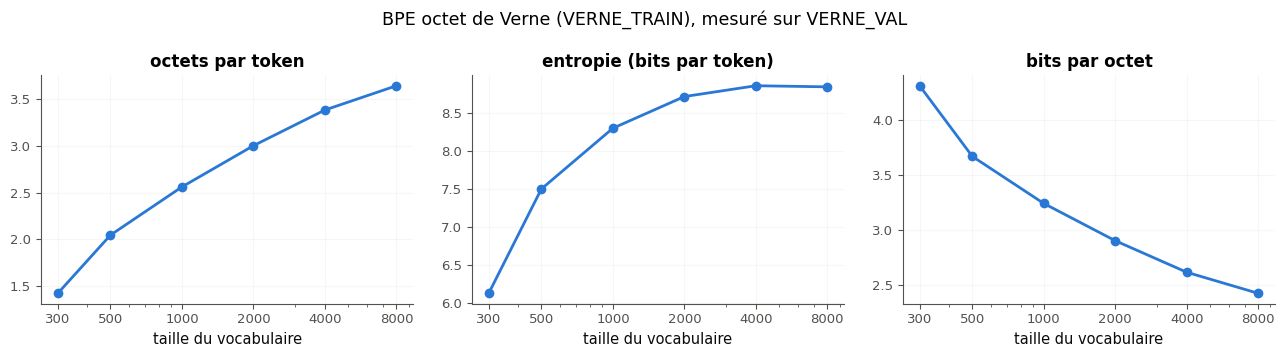

In [44]:
SIZES_20 = (300, 500, 1000, 2000, 4000, 8000)
if not bpe_written():
    print("⏳ Ex B2.20 : l'expérience attend BPETokenizer.fit et encode (B2.16 et B2.17).")
elif not bpe_rebuild_ok("B2.20"):
    pass
elif not globals().get("ok_20"):
    print("⏳ Ex B2.20 : l'expérience attend que compression_20 et token_entropy_20 passent la cellule précédente.")
else:
    with checked("B2.20"):
        start_20 = time.perf_counter()
        BIG_20 = fast_byte_bpe(VERNE_TRAIN, max(SIZES_20))
        print(f"Les {len(BIG_20.merges_)} fusions d'un BPE octet de {max(SIZES_20)} tokens sur VERNE_TRAIN, apprises par "
              f"tokenizers : {fr(time.perf_counter() - start_20, 1)} s.")
        part_20 = VERNE_TRAIN[:100_000]
        start_20 = time.perf_counter()
        mine_20 = mylearn.tokenizer.BPETokenizer(vocab_size=400, pre_tokenizer="gpt2").fit(part_20)
        seconds_20 = time.perf_counter() - start_20
        verdict("B2.20", mine_20.merges_ == fast_byte_bpe(part_20, 400).merges_,
                f"ton fit (400 tokens sur 100 000 caractères de Verne, {fr(seconds_20, 1)} s) apprend les mêmes fusions que "
                "fast_byte_bpe.",
                "ton fit et fast_byte_bpe n'apprennent pas les mêmes fusions sur 100 000 caractères de Verne : relis "
                "B2.16 (départage, min_frequency, niveau octet).")
        verdict("B2.20", truncated_bpe(BIG_20, 400).merges_ == fast_byte_bpe(VERNE_TRAIN, 400).merges_,
                f"les 144 premières fusions de l'entraînement à {max(SIZES_20)} tokens sont celles d'un entraînement à 400 : "
                "truncated_bpe redonne le tokenizer plus petit.",
                "les premières fusions d'un entraînement long devraient être celles d'un entraînement court.")
        rows_20 = sweep_20(BIG_20, VERNE_VAL, SIZES_20)
        if not returned("B2.20", "sweep_20", rows_20):
            raise StopCheck
        table_20 = pd.DataFrame(rows_20)
        need_20 = ["vocab_size", "bytes_per_token", "bits_per_token", "bits_per_byte", "used"]
        if list(table_20.get("vocab_size", [])) != list(SIZES_20) or any(c not in table_20 for c in need_20):
            print(f"❌ Ex B2.20 : sweep_20 doit rendre une ligne par taille de {SIZES_20}, dans cet ordre, avec les clés {need_20}.")
            raise StopCheck
        row_20 = rows_20[SIZES_20.index(1000)]
        tok1000_20 = truncated_bpe(BIG_20, 1000)
        ids1000_20 = tok1000_20.encode(VERNE_VAL)
        verdict("B2.20", math.isclose(row_20["bytes_per_token"], compression_20(tok1000_20, VERNE_VAL))
                and math.isclose(row_20["bits_per_token"], token_entropy_20(tok1000_20, VERNE_VAL))
                and math.isclose(row_20["bits_per_byte"], row_20["bits_per_token"] / row_20["bytes_per_token"])
                and row_20["used"] == len(set(ids1000_20)),
                "à 1 000 tokens, la ligne de sweep_20 reprend tes deux mesures, leur quotient et le nombre d'ids distincts.",
                "à 1 000 tokens, la ligne de sweep_20 doit reprendre compression_20, token_entropy_20 (sur "
                "truncated_bpe(big_tok, 1000)), leur quotient et le nombre d'identifiants distincts du texte encodé.")
        print(table_20[need_20].to_string(index=False, float_format=lambda x: f"{x:.3f}"))
        fig_20, axes_20 = plt.subplots(1, 3, figsize=(13, 3.6))
        for ax, col, label in zip(axes_20, ("bytes_per_token", "bits_per_token", "bits_per_byte"),
                                  ("octets par token", "entropie (bits par token)", "bits par octet")):
            ax.plot(table_20["vocab_size"], table_20[col], "o-")
            ax.set_xscale("log")
            ax.set_xticks(SIZES_20, [str(s) for s in SIZES_20])
            ax.set_xlabel("taille du vocabulaire")
            ax.set_title(label)
            ax.grid(alpha=0.3)
        fig_20.suptitle("BPE octet de Verne (VERNE_TRAIN), mesuré sur VERNE_VAL")
        fig_20.tight_layout()
        plt.show()

### Ex B2.21 — Tokenizer entraîné sur Holmes, appliqué à Verne (et l'inverse) : le coût de la langue 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer ce que coûte un tokenizer appris sur une autre langue, et ce que coûte un tokenizer partagé.  
**Prérequis :** Ex B2.20 · Ex B2.13 · fiche §202.6 (« Le même texte, un autre prix selon la langue ») · **Fil rouge :** Holmes/Verne · **Parcours :** C

En B2.13, GPT-2 compresse moins bien Verne que Holmes. Cela vient-il du français, ou des textes sur lesquels son tokenizer a appris ? Tu entraînes trois BPE octet de 2 000 tokens et tu les mesures sur la validation des deux romans.

**Contrat**
- `train_tokenizers_21(vocab_size=2000)` : trois `BPETokenizer` de ta librairie, au niveau octet, de pré-tokenizer `'gpt2'` et de `vocab_size` tokens, appris par `fast_byte_bpe` (ou par ton `fit`, plus lent, qui donne les mêmes fusions), dans un dictionnaire :
  - `"holmes"`, appris sur `HOLMES_TRAIN` ;
  - `"verne"`, appris sur `VERNE_TRAIN` ;
  - `"mixte"`, appris sur les deux textes ensemble.
- `cross_table_21(tokenizers, texts)` : un `DataFrame` de pandas des octets par token (`compression_20`, B2.20), une ligne par tokenizer et une colonne par texte ; `tokenizers` et `texts` sont des dictionnaires nom → objet.

La cellule de vérification entraîne tes trois tokenizers (quelques secondes avec `fast_byte_bpe`) et contrôle leurs réglages. Elle vérifie aussi que celui de Verne commence par les fusions de B2.20. Elle calcule ensuite ton tableau, y ajoute GPT-2 et le trace.

Dans tes notes :
- de combien la compression baisse-t-elle quand on applique un tokenizer à l'autre roman ?
- le tokenizer mixte : que coûte-t-il à chaque langue, par rapport à son tokenizer « maison » ?
- où se place GPT-2, avec ses 50 257 tokens ?
- qu'en conclus-tu sur la « taxe » de certaines langues (fiche §202.6), et sur le choix des données d'entraînement du tokenizer d'un modèle multilingue ?

Trois tokenizers de 2 000 tokens : 2,0 s.
✅ Ex B2.21 : holmes : BPE octet 'gpt2' de 2 000 tokens.
✅ Ex B2.21 : verne : BPE octet 'gpt2' de 2 000 tokens.
✅ Ex B2.21 : mixte : BPE octet 'gpt2' de 2 000 tokens.
✅ Ex B2.21 : le tokenizer de Verne a les 1 744 premières fusions de celui de B2.20 : il est appris sur VERNE_TRAIN.
✅ Ex B2.21 : les trois tokenizers ont des fusions différentes.


✅ Ex B2.21 : le tableau contient les octets par token de compression_20.
                       Holmes (validation)  Verne (validation)
holmes                                3.15                1.84
verne                                 1.79                3.00
mixte                                 2.97                2.74
GPT-2 (50 257 tokens)                 3.72                2.62


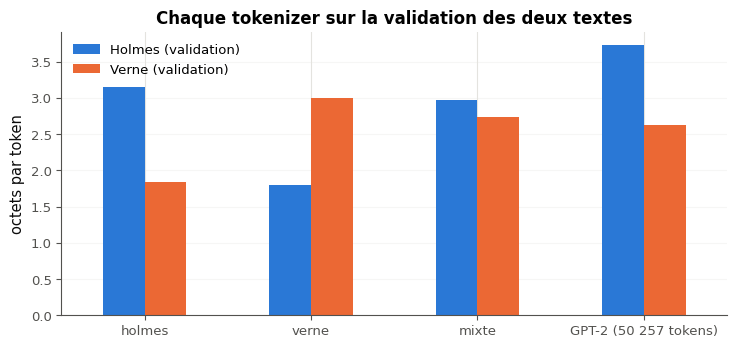

In [45]:
def train_tokenizers_21(vocab_size=2000):
    """Three byte-level BPETokenizer of your library, pre_tokenizer "gpt2", vocab_size tokens:
    {"holmes": learned on HOLMES_TRAIN, "verne": on VERNE_TRAIN, "mixte": on both texts}."""
    return {"holmes": fast_byte_bpe(HOLMES_TRAIN, vocab_size),          # the merges of fit, learned in Rust
            "verne": fast_byte_bpe(VERNE_TRAIN, vocab_size),
            "mixte": fast_byte_bpe([HOLMES_TRAIN, VERNE_TRAIN], vocab_size)}


def cross_table_21(tokenizers, texts):
    """A pandas DataFrame of the bytes per token (compression_20): one row per tokenizer, one column per text
    (tokenizers and texts are dicts name -> object)."""
    return pd.DataFrame({text_name: {tok_name: compression_20(tok, text) for tok_name, tok in tokenizers.items()}
                         for text_name, text in texts.items()})


if not bpe_written():
    print("⏳ Ex B2.21 : l'expérience attend BPETokenizer.fit et encode (B2.16 et B2.17).")
elif bpe_rebuild_ok("B2.21"):
    with checked("B2.21"):
        need("B2.21", "compression_20")
        start_21 = time.perf_counter()
        toks_21 = train_tokenizers_21(2000)
        print(f"Trois tokenizers de 2 000 tokens : {fr(time.perf_counter() - start_21, 1)} s.")
        if not returned("B2.21", "train_tokenizers_21", toks_21):
            raise StopCheck
        if not isinstance(toks_21, dict) or set(toks_21) != {"holmes", "verne", "mixte"}:
            print("❌ Ex B2.21 : train_tokenizers_21 doit rendre un dictionnaire de clés 'holmes', 'verne' et 'mixte'.")
            raise StopCheck
        for name, tok in toks_21.items():
            ok = (getattr(tok, "level", None) == "byte" and getattr(tok, "pre_tokenizer", None) == "gpt2"
                  and len(getattr(tok, "vocab_", {})) == 2000 and not getattr(tok, "special_ids_", {}))
            verdict("B2.21", ok, f"{name} : BPE octet 'gpt2' de 2 000 tokens.",
                    f"{name} : attendu un BPETokenizer de niveau octet, pré-tokenizer 'gpt2', 2 000 tokens sans token spécial.")
        if "BIG_20" in globals():
            verdict("B2.21", toks_21["verne"].merges_ == BIG_20.merges_[:2000 - 256],
                    "le tokenizer de Verne a les 1 744 premières fusions de celui de B2.20 : il est appris sur VERNE_TRAIN.",
                    "le tokenizer de Verne devrait avoir les premières fusions de BIG_20 (B2.20) : sur quel texte est-il appris ?")
        verdict("B2.21", toks_21["holmes"].merges_[:20] != toks_21["verne"].merges_[:20]
                and toks_21["mixte"].merges_ not in (toks_21["holmes"].merges_, toks_21["verne"].merges_),
                "les trois tokenizers ont des fusions différentes.",
                "deux de tes tokenizers ont les mêmes fusions : sont-ils appris sur des textes différents ?")
        texts_21 = {"Holmes (validation)": HOLMES_VAL, "Verne (validation)": VERNE_VAL}
        table_21 = cross_table_21(toks_21, texts_21)
        if not returned("B2.21", "cross_table_21", table_21):
            raise StopCheck
        if not isinstance(table_21, pd.DataFrame) or set(table_21.index) != set(toks_21) or set(table_21.columns) != set(texts_21):
            print("❌ Ex B2.21 : cross_table_21 doit rendre un DataFrame, une ligne par tokenizer, une colonne par texte.")
            raise StopCheck
        verdict("B2.21", math.isclose(float(table_21.loc["verne", "Verne (validation)"]),
                                      compression_20(toks_21["verne"], VERNE_VAL)),
                "le tableau contient les octets par token de compression_20.",
                "le tableau doit contenir compression_20(tokenizer, texte) : relis-le.")
        gpt2_21 = wbtext.try_tokenizer("gpt2", "B2.21")
        if gpt2_21 is not None:
            table_21.loc["GPT-2 (50 257 tokens)"] = pd.Series({name: n_bytes(t) / wbtext.count_tokens(gpt2_21, t)
                                                              for name, t in texts_21.items()})
        print(table_21.to_string(float_format=lambda x: f"{x:.2f}"))
        ax_21 = table_21.plot.bar(figsize=(7.5, 3.6), rot=0)
        ax_21.set_ylabel("octets par token")
        ax_21.set_title("Chaque tokenizer sur la validation des deux textes")
        ax_21.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.show()

## Partie D · Des vecteurs de mots : compter, factoriser, prédire

Deuxième phase : des tokens aux vecteurs. Tu écris dans `mylearn/embeddings.py` la matrice de co-occurrences et la PPMI (B2.22), puis le cosinus et les plus proches voisins (B2.23). Tu construis des vecteurs de mots de Holmes par PPMI + SVD (B2.24), puis tu entraînes un word2vec en PyTorch sur Verne (B2.25), dont tu prédis les voisins de deux personnages (B2.26) avant de lire ses cartes (B2.27). `cosine_similarity_matrix` et `most_similar` resserviront en B4 (recherche dense).

La cellule suivante importe PyTorch et prépare les mots des deux romans, comme la carte de la fiche (§202.9) : `WORDS_H`, en minuscules et en lettres `a` à `z` ; `WORDS_V`, en minuscules, accents gardés (« été », « où »). Elle donne aussi `nearest_words(E, itos, mot, k)`, les $k$ plus proches voisins d'un mot dans une matrice de vecteurs de norme 1, pour les cellules de vérification. Au ch. 22, tu avais déjà découpé ces deux textes en mots pour en faire un vocabulaire ; ici, chaque mot devient un vecteur.

**Contrat commun de `embeddings.py`** (les docstrings, plus ces précisions que vérifient les tests) :
- tes fonctions acceptent des listes et des tableaux d'entiers ou de flottants, et ne modifient jamais leurs entrées ;
- une entrée invalide lève `ValueError`, jamais `IndexError` ni un résultat silencieusement faux ;
- NumPy seulement ; les tests comparent à une double boucle, à la formule en `float64`, à scikit-learn et à PyTorch, à `rtol = 1e-6` et `atol = 1e-6` près (un calcul en `float32` passe ; la tolérance s'affiche dans le message).

In [46]:
# Tools of the phase « embeddings » (parts D and E)
from wb.nbtools import pair

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
except ImportError:                       # a computer without PyTorch (Mac Intel): parts D and E are done on Colab
    torch = None
    print("⏳ PyTorch absent sur cet ordinateur : B2.25 à B2.29 se font sur Colab (00_setup/INSTALL_LOCAL.md) ; les "
          "tests de ta librairie tournent sans lui : python -m pytest tests/test_chb2_embeddings.py -q")

    def _skip_torch_cells(lines):
        """IPython input transformer: without PyTorch, a cell that uses it prints ⏳ instead of stopping "Run all"."""
        if re.search(r"\b(torch|torchvision)\b|(?<![\w.])(nn|F)\.", "".join(lines)):
            return ['print("⏳ PyTorch absent sur cet ordinateur : cette cellule se fait sur Colab.")\n']
        return lines

    try:
        _shell = get_ipython()
    except NameError:                     # not in a notebook
        _shell = None
    if _shell is not None and all(getattr(f, "__name__", "") != "_skip_torch_cells" for f in _shell.input_transformers_cleanup):
        _shell.input_transformers_cleanup.append(_skip_torch_cells)

TEST_EMB = "tests/test_chb2_embeddings.py"     # the tests of your library embeddings.py
WORDS_H = wbtext.words("holmes")               # the 105 863 words of Holmes, [a-z]+ in lower case (the map of the fiche)
WORDS_V = wbtext.words("verne")                # the 72 367 words of Verne, accents kept


def nearest_words(E, itos, word, k=10, stoi=None):
    """The k nearest other words of `word` by cosine (rows of E of norm 1), ties to the smaller id: [(word, cos)]."""
    stoi = stoi or {w: i for i, w in enumerate(itos)}
    sims = E @ E[stoi[word]]
    order = [i for i in np.argsort(-sims, kind="stable") if i != stoi[word]][:k]
    return [(itos[i], float(sims[i])) for i in order]


print(f"Holmes : {len(WORDS_H):_} mots ({len(set(WORDS_H)):_} formes) ; Verne : {len(WORDS_V):_} mots "
      f"({len(set(WORDS_V)):_} formes).".replace("_", " "))

Holmes : 105 863 mots (7 817 formes) ; Verne : 72 367 mots (8 793 formes).


### Ex B2.22 — cooccurrence_matrix et ppmi 🔨 ★★ ⏱️ 30 min
**Objectif :** compter les co-occurrences d'une suite de mots dans une fenêtre, puis les transformer en information mutuelle ponctuelle positive.  
**Prérequis :** ✏️ B2.6 · ch. 6 (information, divergence KL) · fiche §202.8 (« La matrice de co-occurrences », « PMI et PPMI ») · **Fil rouge :** Holmes · **mylearn :** `embeddings.py` · **Parcours :** M, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/embeddings.py` (créé par `python tools/start_chapter.py B2`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb2_embeddings.py -q` les lance tous dans un terminal.

**Contrat**
- `cooccurrence_matrix(ids, vocab_size, window=2, weighting="uniform", symmetric=True)` :
  - rend une matrice **float** `(vocab_size, vocab_size)`, même en `'uniform'` ;
  - pour chaque position `i` et chaque distance `d` de 1 à `window`, ajoute le poids (1, ou `1 / d` en `'harmonic'`) à `C[ids[i], ids[i + d]]` et, si `symmetric`, à `C[ids[i], ids[i - d]]` ; avec `symmetric=False`, seulement le contexte de droite ;
  - les répétitions d'une même paire s'**additionnent** : `[0, 0, 0, 1]` avec une fenêtre de 1 donne `C[0, 0] = 4` ;
  - les ids sont des entiers (une liste, des `int32` ou des `uint8` conviennent) ; une suite plus courte que la fenêtre est permise ;
  - `ValueError` pour des ids qui ne sont pas 1-D, `window < 1`, une pondération inconnue, et un id hors de `[0, vocab_size)`, −1 compris (pas d'`IndexError`, pas d'indice négatif à la Python).
- `ppmi(C, alpha=1.0)` :
  - $\max\big(0, \log \frac{p(w, c)}{p(w)\,p_\alpha(c)}\big)$ avec le **logarithme naturel**, les lignes pour les mots, les colonnes pour les contextes ;
  - le lissage `alpha` ne porte que sur les **colonnes** : $p_\alpha(c) = \#(c)^\alpha / \sum_{c'} \#(c')^\alpha$ (renormalisé) ;
  - 0 là où `C == 0`, donc une ligne ou une colonne nulle donne des 0, **jamais NaN** ;
  - accepte des entiers et des listes ; `ValueError` pour `C` qui n'est pas 2-D, une entrée négative ou une somme nulle.

La première cellule de vérification essaie tes deux fonctions sur des cas visibles (la matrice chien / chat / os de la fiche, un mot jamais vu, une matrice « indépendante »), compare tes comptes sur 30 000 mots de Holmes à ceux de `scipy.sparse`, puis essaie huit refus. La seconde lance les 36 tests de l'exercice (`-k "test_cooccurrence_matrix_ or test_ppmi_"`).

Dans tes notes : pourquoi la ligne d'un mot très fréquent (« the ») domine-t-elle la matrice de comptes, et que fait la PPMI de ses cases ? Que vaut la PPMI de deux mots qui ne se rencontrent jamais, et pourquoi la PMI, elle, ne conviendrait-elle pas à une matrice creuse ?

In [47]:
with checked("B2.22"):
    Em = mylearn.embeddings
    ids_22 = np.array([0, 0, 0, 1], dtype=np.int32)              # int32, as the tests
    arg_22 = ids_22.copy()
    C_22 = Em.cooccurrence_matrix(arg_22, 2, window=1)
    if returned("B2.22", "cooccurrence_matrix", C_22):
        ok_22 = (isinstance(C_22, np.ndarray) and C_22.dtype.kind == "f" and C_22.shape == (2, 2)
                 and np.array_equal(C_22, [[4.0, 1.0], [1.0, 0.0]]))
        verdict("B2.22", ok_22, "[0, 0, 0, 1], fenêtre 1 : C[0, 0] = 4, chaque répétition d'une paire compte ; une matrice "
                "float (2, 2).",
                f"cooccurrence_matrix([0, 0, 0, 1], 2, window=1) doit rendre la matrice float [[4, 1], [1, 0]] (une paire "
                f"répétée s'ajoute à chaque fois) ; reçu {np.asarray(C_22).tolist()} de type {getattr(C_22, 'dtype', type(C_22).__name__)}.")
        verdict("B2.22", np.array_equal(arg_22, ids_22), "les ids reçus n'ont pas changé.", "cooccurrence_matrix a modifié les ids reçus.")
    right_22 = Em.cooccurrence_matrix([2, 0, 1], 3, window=2, weighting="harmonic", symmetric=False)
    same("B2.22", "[2, 0, 1], fenêtre 2, harmonique, contextes de droite seulement", right_22,
         [[0, 1, 0], [0, 0, 0], [1, 0.5, 0]], rtol=1e-6, atol=1e-6)
    # Holmes: the 2 000 most frequent words (the others removed here), against a count by scipy.sparse
    import scipy.sparse as sp
    stoi_22, _ = wbtext.top_vocab(WORDS_H, 2000)
    h_22 = wbtext.word_ids(WORDS_H[:30000], stoi_22)
    h_22 = h_22[h_22 >= 0]
    pairs_22 = [(h_22[:-d], h_22[d:], np.full(len(h_22) - d, 1.0 / d)) for d in (1, 2, 3)]
    rows_22 = np.concatenate([a for a, b, w in pairs_22] + [b for a, b, w in pairs_22])
    cols_22 = np.concatenate([b for a, b, w in pairs_22] + [a for a, b, w in pairs_22])
    want_22 = sp.coo_matrix((np.concatenate([w for *_, w in pairs_22] * 2), (rows_22, cols_22)), shape=(2000, 2000)).toarray()
    same("B2.22", f"Holmes ({len(h_22):_} mots, 2 000 formes), fenêtre 3, harmonique : la matrice d'un comptage "
         "par scipy.sparse".replace("_", " "), Em.cooccurrence_matrix(h_22, 2000, window=3, weighting="harmonic"), want_22,
         rtol=1e-6, atol=1e-6)
    for label_22, call_22 in (("des ids 2-D", lambda: Em.cooccurrence_matrix([[0, 1]], 2)),
                              ("window = 0", lambda: Em.cooccurrence_matrix([0, 1], 2, window=0)),
                              ("weighting = 'gaussian'", lambda: Em.cooccurrence_matrix([0, 1], 2, weighting="gaussian")),
                              ("un id égal à vocab_size", lambda: Em.cooccurrence_matrix([0, 2], 2)),
                              ("un id de -1", lambda: Em.cooccurrence_matrix([0, -1], 2))):
        refuses("B2.22", label_22, call_22)

    # ppmi: the matrix chien / chat / os of the fiche (§202.8), a word never seen, an « independent » matrix
    C3_22 = np.array([[0, 4, 1], [4, 0, 1], [1, 1, 2]])          # integers: ppmi must accept them
    arg3_22 = C3_22.copy()
    P_22 = Em.ppmi(arg3_22)
    if returned("B2.22", "ppmi", P_22):
        verdict("B2.22", isinstance(P_22, np.ndarray) and P_22.shape == (3, 3) and np.isclose(P_22[0, 1], math.log(56 / 25))
                and P_22[0, 2] == 0 and np.isclose(P_22[2, 2], math.log(28 / 16)),
                "PPMI(chien, chat) = log 2,24 ≈ 0,807, PPMI(chien, os) = 0 (PMI négative), PPMI(os, os) ≈ 0,560, comme la fiche.",
                f"sur la matrice chien / chat / os de la fiche, attendu PPMI(chien, chat) ≈ 0,807, PPMI(chien, os) = 0 et "
                f"PPMI(os, os) ≈ 0,560 (logarithme naturel) ; reçu {np.round(np.asarray(P_22, dtype=float), 3).tolist()}.")
        verdict("B2.22", np.array_equal(arg3_22, C3_22), "la matrice reçue n'a pas changé.", "ppmi a modifié la matrice reçue.")
    P75_22 = Em.ppmi(C3_22, alpha=0.75)
    verdict("B2.22", np.isclose(P75_22[0, 1], 0.8230, atol=5e-4), f"alpha = 0,75 : PPMI(chien, chat) = {fr(P75_22[0, 1])}, "
            "comme la fiche.", f"alpha = 0,75 : attendu PPMI(chien, chat) ≈ 0,823 (fiche §202.8) ; reçu {fr(P75_22[0, 1])} : "
            "le lissage ne porte que sur les colonnes, puis se renormalise.")
    with warnings.catch_warnings(record=True) as caught_22, np.errstate(all="warn"):
        warnings.simplefilter("always")
        Z_22 = Em.ppmi(np.array([[0.0, 2, 1, 0], [2, 0, 3, 0], [1, 3, 0, 0], [0, 0, 0, 0]]))
    verdict("B2.22", np.all(np.isfinite(Z_22)) and np.all(Z_22[3] == 0) and np.all(Z_22[:, 3] == 0),
            "un mot jamais vu (ligne et colonne nulles) : des 0, sans NaN.",
            "une ligne et une colonne nulles doivent donner des 0, jamais NaN : mets 0 là où C == 0.")
    if any(issubclass(w.category, RuntimeWarning) for w in caught_22):
        print("💡 Ex B2.22 : ppmi émet un avertissement de NumPy (log(0) ou 0 / 0) : calcule le logarithme sur les seules "
              "cases non nulles, ou dans np.errstate(divide='ignore', invalid='ignore').")
    indep_22 = Em.ppmi(np.outer([1.0, 2, 3], [4.0, 1, 5]))
    verdict("B2.22", np.allclose(indep_22, 0, atol=1e-9), "une matrice « indépendante » np.outer(u, v) : PPMI nulle partout.",
            f"np.outer(u, v) donne p(w, c) = p(w) p(c) : attendu une PPMI nulle ; reçu le maximum {float(np.max(indep_22)):.3g}.")
    for label_22, call_22 in (("une matrice 1-D", lambda: Em.ppmi([1.0, 2.0])),
                              ("une entrée négative", lambda: Em.ppmi([[1.0, -1.0], [0.0, 2.0]])),
                              ("une somme nulle", lambda: Em.ppmi(np.zeros((2, 2))))):
        refuses("B2.22", label_22, call_22)

✅ Ex B2.22 : [0, 0, 0, 1], fenêtre 1 : C[0, 0] = 4, chaque répétition d'une paire compte ; une matrice float (2, 2).
✅ Ex B2.22 : les ids reçus n'ont pas changé.
✅ Ex B2.22 : [2, 0, 1], fenêtre 2, harmonique, contextes de droite seulement : un tableau (3, 3), comme attendu.


✅ Ex B2.22 : Holmes (27 154 mots, 2 000 formes), fenêtre 3, harmonique : la matrice d'un comptage par scipy.sparse : un tableau (2000, 2000), comme attendu.
✅ Ex B2.22 : des ids 2-D : ValueError levée (ids must be 1-D, got 2-D of shape (1, 2)).
✅ Ex B2.22 : window = 0 : ValueError levée (window must be >= 1, got 0).
✅ Ex B2.22 : weighting = 'gaussian' : ValueError levée (weighting must be 'uniform' or 'harmonic', not 'gaussian').
✅ Ex B2.22 : un id égal à vocab_size : ValueError levée (every id must be in [0, 2), got ids from 0 to 2).
✅ Ex B2.22 : un id de -1 : ValueError levée (every id must be in [0, 2), got ids from -1 to 0).
✅ Ex B2.22 : PPMI(chien, chat) = log 2,24 ≈ 0,807, PPMI(chien, os) = 0 (PMI négative), PPMI(os, os) ≈ 0,560, comme la fiche.
✅ Ex B2.22 : la matrice reçue n'a pas changé.
✅ Ex B2.22 : alpha = 0,75 : PPMI(chien, chat) = 0,823, comme la fiche.
✅ Ex B2.22 : un mot jamais vu (ligne et colonne nulles) : des 0, sans NaN.
✅ Ex B2.22 : une matrice « indépendante » np.o

In [48]:
if written(lambda: mylearn.embeddings.cooccurrence_matrix([0, 1], 2, window=1)):
    run_pytest_group(TEST_EMB, impl="ref", keyword="test_cooccurrence_matrix_ or test_ppmi_")   # 36 tests
else:
    print("⏳ Ex B2.22 : les tests attendent tes fonctions.")

pytest: 36 passed, 26 deselected in 2.90s


### Ex B2.23 — cosine_similarity_matrix et most_similar 🔨 ★★ ⏱️ 20 min
**Objectif :** calculer tous les cosinus entre deux ensembles de vecteurs, puis chercher les plus proches voisins d'une requête, égalités et exclusions comprises.  
**Prérequis :** ✏️ B2.2 · 0B (produit scalaire, norme) · fiche §202.9 (« Le cosinus », « Les plus proches voisins », « Les analogies ») · **Fil rouge :** Holmes · **mylearn :** `embeddings.py` · **Parcours :** R, C

> **Mode d'emploi mylearn** : ouvre `mon_travail/mylearn/embeddings.py` (créé par `python tools/start_chapter.py B2`), lis la docstring, remplace chaque `raise NotImplementedError(...)` de l'exercice par ton code et **enregistre**. NumPy seulement. La première cellule de vérification recharge ta librairie et l'essaie sur des cas visibles ; la seconde lance les tests de l'exercice. `python -m pytest tests/test_chb2_embeddings.py -q` les lance tous dans un terminal.

**Contrat**
- `cosine_similarity_matrix(A, B=None, eps=1e-12)` :
  - rend `S` de forme `(n, m)`, `S[i, j] = A[i] · B[j] / ((‖A[i]‖ + eps)(‖B[j]‖ + eps))` : `eps` s'ajoute à **chaque** norme, pas sous la racine ni au produit (testé avec `eps = 0,5` et 2) ; une ligne nulle a un cosinus de 0 avec tout ;
  - `B = None` vaut `B = A` ; accepte des listes et des entiers, sans les modifier ;
  - `ValueError` pour `A` ou `B` qui n'est pas 2-D, et pour des nombres de colonnes différents.
- `most_similar(E, query, k=10, exclude=())` :
  - rend un **tuple de deux tableaux NumPy** 1-D : les indices (entiers) et les cosinus (flottants), par cosinus décroissant ;
  - les égalités vont au **plus petit indice** (testé sur 120 lignes, dont 40 copies de trois lignes : le tri par défaut de `np.argsort` et `np.argpartition` ne le garantissent pas) ;
  - les lignes de `exclude` (des indices valides de `E`) sont retirées **avant** de garder les `k` premières ; s'il en reste moins de `k`, toutes ; si tout est exclu, deux tableaux de forme `(0,)` ;
  - une requête nulle donne des cosinus nuls, donc les `k` premiers indices ;
  - `ValueError` pour `k < 1`, une requête qui n'a pas la longueur `E.shape[1]`, ou de forme `(1, d)`.

La première cellule de vérification compare ta matrice à `sklearn.metrics.pairwise.cosine_similarity`, essaie `eps`, puis `most_similar` sur 120 lignes dont 40 égales à la requête (des égalités), avec des exclusions, trop peu de lignes, une requête nulle et trois refus. La seconde lance les 26 tests de l'exercice (`-k "test_cosine_similarity_matrix_ or test_most_similar_"`).

Dans tes notes : pourquoi normaliser les lignes **une fois**, puis faire un seul produit matriciel, plutôt que de calculer chaque cosinus séparément ? Pour l'analogie du ✏️ B2.2, quels indices passes-tu à `exclude`, et que se passerait-il sans eux ?

In [49]:
with checked("B2.23"):
    Em = mylearn.embeddings
    rng_23 = np.random.default_rng(23)
    A_23, B_23 = rng_23.normal(size=(5, 3)), rng_23.normal(size=(4, 3))
    A_23[2] = 0.0                                                   # a row of zeros
    argA_23, argB_23 = A_23.copy(), B_23.copy()
    S_23 = Em.cosine_similarity_matrix(argA_23, argB_23)
    from sklearn.metrics.pairwise import cosine_similarity
    if returned("B2.23", "cosine_similarity_matrix", S_23):
        same("B2.23", "cosine_similarity_matrix(A, B), A (5, 3) avec une ligne nulle, B (4, 3), contre scikit-learn",
             S_23, cosine_similarity(A_23, B_23), rtol=1e-6, atol=1e-9)
        verdict("B2.23", np.array_equal(argA_23, A_23) and np.array_equal(argB_23, B_23), "A et B n'ont pas changé.",
                "cosine_similarity_matrix a modifié A ou B.")
    same("B2.23", "cosine_similarity_matrix(A) (B = None : B = A)", Em.cosine_similarity_matrix(A_23), cosine_similarity(A_23),
         rtol=1e-6, atol=1e-9)
    same("B2.23", "[[3, 4]] contre [[6, 8]] avec eps = 0,5 (ajouté à chaque norme)",
         Em.cosine_similarity_matrix([[3, 4]], [[6, 8]], eps=0.5), [[50 / (5.5 * 10.5)]])
    refuses("B2.23", "A 1-D", lambda: Em.cosine_similarity_matrix([1.0, 2.0]))
    refuses("B2.23", "A et B de 3 et 2 colonnes", lambda: Em.cosine_similarity_matrix(A_23, B_23[:, :2]))

    E_23 = rng_23.normal(size=(120, 3))                             # 120 rows, 40 of them equal to the query
    copies_23 = np.sort(rng_23.choice(120, 40, replace=False))
    E_23[copies_23] = [1.0, 0.0, 0.0]
    out_23 = Em.most_similar(E_23, [1.0, 0.0, 0.0], k=5)
    if returned("B2.23", "most_similar", out_23):
        idx_23, sims_23 = pair("B2.23", "most_similar", out_23, names=("indices", "similarities"))
        got_23 = np.asarray(idx_23).tolist()
        verdict("B2.23", isinstance(idx_23, np.ndarray) and isinstance(sims_23, np.ndarray)
                and np.issubdtype(idx_23.dtype, np.integer) and got_23 == copies_23[:5].tolist()
                and np.allclose(sims_23, 1),
                f"40 lignes à égalité parmi 120 : les 5 plus petits indices, {copies_23[:5].tolist()} (un tri stable), en "
                "tableaux NumPy.",
                f"40 lignes égales à la requête parmi 120 : attendu les indices {copies_23[:5].tolist()} (égalités : le plus "
                f"petit indice, un tri stable), deux tableaux NumPy ; reçu {got_23}.")
    idx_23, _ = Em.most_similar(E_23, [1.0, 0.0, 0.0], k=3, exclude=tuple(copies_23[:2].tolist()))
    want_23 = copies_23[2:5].tolist()
    verdict("B2.23", np.asarray(idx_23).tolist() == want_23, f"exclude retiré avant le top-k : {want_23}.",
            f"avec exclude={tuple(copies_23[:2].tolist())}, attendu {want_23} (on retire avant de garder les k premiers, "
            f"égalités au plus petit indice) ; reçu {np.asarray(idx_23).tolist()}.")
    few_23 = Em.most_similar(np.eye(3), [1.0, 1.0, 0.0], k=10, exclude=(1,))
    verdict("B2.23", np.asarray(few_23[0]).tolist() == [0, 2], "moins de k lignes restantes : toutes, ici [0, 2].",
            f"3 lignes, une exclue, k = 10 : attendu les deux restantes [0, 2] ; reçu {np.asarray(few_23[0]).tolist()}.")
    none_23 = Em.most_similar(np.eye(2), [1.0, 0.0], k=2, exclude=(0, 1))
    verdict("B2.23", none_23[0].shape == (0,) and none_23[1].shape == (0,), "tout exclu : deux tableaux de forme (0,).",
            f"tout exclu : attendu deux tableaux vides de forme (0,) ; reçu {none_23!r}.")
    zero_23 = Em.most_similar(np.eye(3), [0.0, 0.0, 0.0], k=2)
    verdict("B2.23", np.asarray(zero_23[0]).tolist() == [0, 1] and np.allclose(zero_23[1], 0),
            "une requête nulle : des similarités nulles et les k premiers indices.",
            f"une requête nulle doit donner des similarités nulles et les indices [0, 1] ; reçu {np.asarray(zero_23[0]).tolist()}.")
    refuses("B2.23", "k = 0", lambda: Em.most_similar(np.eye(3), [1.0, 0, 0], k=0))
    refuses("B2.23", "une requête de longueur 2 pour des lignes de 3", lambda: Em.most_similar(np.eye(3), [1.0, 0], k=1))
    refuses("B2.23", "une requête de forme (1, 3)", lambda: Em.most_similar(np.eye(3), [[1.0, 0, 0]], k=1))

✅ Ex B2.23 : cosine_similarity_matrix(A, B), A (5, 3) avec une ligne nulle, B (4, 3), contre scikit-learn : un tableau (5, 4), comme attendu.
✅ Ex B2.23 : A et B n'ont pas changé.
✅ Ex B2.23 : cosine_similarity_matrix(A) (B = None : B = A) : un tableau (5, 5), comme attendu.
✅ Ex B2.23 : [[3, 4]] contre [[6, 8]] avec eps = 0,5 (ajouté à chaque norme) : [[0.86580087]], comme attendu.
✅ Ex B2.23 : A 1-D : ValueError levée (A must be 2-D, got 1-D of shape (2,)).
✅ Ex B2.23 : A et B de 3 et 2 colonnes : ValueError levée (A and B must have the same number of columns, got 3 and 2).
✅ Ex B2.23 : 40 lignes à égalité parmi 120 : les 5 plus petits indices, [2, 3, 4, 6, 7] (un tri stable), en tableaux NumPy.
✅ Ex B2.23 : exclude retiré avant le top-k : [4, 6, 7].
✅ Ex B2.23 : moins de k lignes restantes : toutes, ici [0, 2].
✅ Ex B2.23 : tout exclu : deux tableaux de forme (0,).
✅ Ex B2.23 : une requête nulle : des similarités nulles et les k premiers indices.
✅ Ex B2.23 : k = 0 : ValueError levé

In [50]:
if written(lambda: mylearn.embeddings.cosine_similarity_matrix([[1.0, 0.0]])):
    run_pytest_group(TEST_EMB, impl="ref", keyword="test_cosine_similarity_matrix_ or test_most_similar_")   # 26 tests
else:
    print("⏳ Ex B2.23 : les tests attendent tes fonctions.")

pytest: 26 passed, 36 deselected in 2.95s


### Ex B2.24 — Embeddings PPMI + SVD sur Holmes : les voisins de « Holmes », « Watson » et « letter » 📦 ★★ ⏱️ 30 min
**Objectif :** construire des vecteurs de mots par comptage, PPMI et SVD tronquée, avec ta librairie et scikit-learn, puis les interroger.  
**Prérequis :** Ex B2.22, B2.23 · ch. 12 (PCA) · fiche §202.8 (« Réduire : la SVD tronquée »), §202.9 · **Fil rouge :** Holmes · **Parcours :** C

La carte de la fiche (§202.9) a été faite avec des vecteurs de Holmes construits par comptage. Tu refais le calcul avec **ta** librairie, et tu interroges trois mots dont la fiche ne dit rien.

**Contrat**
- `ppmi_svd_24(words, n_words=4000, window=2, dim=100, alpha=0.75)` rend `(E, stoi, itos)` :
  - le vocabulaire est `wbtext.top_vocab(words, n_words)`, les `n_words` mots les plus fréquents (`itos[0]` est le plus fréquent) ;
  - les co-occurrences viennent de **ton** `cooccurrence_matrix` (fenêtre symétrique, pondération uniforme), la PPMI lissée de **ton** `ppmi(C, alpha)` ;
  - un mot **hors du vocabulaire garde sa place** dans le texte, mais ses paires ne comptent pas : on ne le retire pas, sinon deux mots qui l'entourent deviendraient voisins. `wbtext.word_ids(words, stoi)` lui donne l'id −1, que ton `cooccurrence_matrix` refuse : à toi de trouver comment ;
  - la SVD tronquée est `TruncatedSVD(n_components=dim, algorithm="arpack", random_state=0)` de scikit-learn, sur la matrice PPMI ;
  - `E` est `(n_words, dim)` : les lignes de $\mathbf{U}_d\,\mathbf{S}_d^{1/2}$ (pas de `fit_transform` seul, qui rend $\mathbf{U}_d\,\mathbf{S}_d$), chacune ramenée à la **norme 1**.
- `neighbours_24(E, stoi, itos, word, k=8)` : la liste des `k` couples `(mot, cosinus)` les plus proches de `word`, par cosinus décroissant, sans `word` lui-même, trouvés par **ton** `most_similar`.

La cellule de vérification lance ta fonction sur les 105 863 mots de Holmes (5 à 15 s, la SVD comprise), puis compare les cosinus de « holmes », « watson » et « letter » avec les 4 000 mots à ceux d'une référence (le même calcul, compté par `scipy.sparse`, `wbtext.reference_ppmi_svd`). Elle affiche enfin les 8 voisins des trois mots.

Dans tes notes :
- les voisins de « holmes » : de quelle nature sont-ils (des noms, des mots qui l'accompagnent dans le texte, des verbes) ? Pourquoi « sherlock » est-il si proche ?
- ceux de « watson » et de « letter » : lesquels ont un sens voisin, lesquels partagent seulement des contextes (« a … of », « the … was ») ?
- « watson » n'apparaît que 81 fois, « letter » 30 fois : que dit la qualité de leurs voisins de la quantité de texte qu'il faut ?

In [51]:
from sklearn.decomposition import TruncatedSVD


def ppmi_svd_24(words, n_words=4000, window=2, dim=100, alpha=0.75):
    """(E, stoi, itos): PPMI + SVD word vectors (rows of norm 1) of the n_words most frequent words of `words`, made
    with your cooccurrence_matrix and ppmi; a word outside the vocabulary keeps its place, but its pairs do not count."""
    stoi, itos = wbtext.top_vocab(words, n_words)
    v = len(itos)
    ids = wbtext.word_ids(words, stoi)                        # -1 for a word outside the vocabulary
    ids = np.where(ids < 0, v, ids)                           # one extra id for all of them: they keep their place...
    C = mylearn.embeddings.cooccurrence_matrix(ids, v + 1, window=window)[:v, :v]   # ...and their row and column go
    M = mylearn.embeddings.ppmi(C, alpha=alpha)
    svd = TruncatedSVD(n_components=dim, algorithm="arpack", random_state=0)
    E = svd.fit_transform(M) / np.sqrt(svd.singular_values_)  # U_d S_d / S_d^(1/2) = U_d S_d^(1/2)
    return E / np.linalg.norm(E, axis=1, keepdims=True), stoi, itos


def neighbours_24(E, stoi, itos, word, k=8):
    """The k nearest other words of `word` by cosine, with your most_similar: [(word, cosine), ...]."""
    idx, sims = mylearn.embeddings.most_similar(E, E[stoi[word]], k=k, exclude=(stoi[word],))
    return [(itos[i], float(s)) for i, s in zip(idx, sims)]


WORDS_24 = ("holmes", "watson", "letter")
ok_24 = False
with checked("B2.24"):
    start_24 = time.perf_counter()
    out_24 = ppmi_svd_24(WORDS_H)
    seconds_24 = time.perf_counter() - start_24
    if not returned("B2.24", "ppmi_svd_24", out_24):
        raise StopCheck
    E_24, stoi_24, itos_24 = pair("B2.24", "ppmi_svd_24", out_24, names=("E", "stoi", "itos"))
    E_24 = np.asarray(E_24, dtype=float)
    verdict("B2.24", E_24.shape == (4000, 100) and np.allclose(np.linalg.norm(E_24, axis=1), 1, atol=1e-6)
            and list(itos_24) == wbtext.top_vocab(WORDS_H, 4000)[1],
            f"E : 4 000 mots × 100 dimensions, lignes de norme 1, le vocabulaire de top_vocab ({fr(seconds_24, 1)} s).",
            f"attendu E de forme (4000, 100) aux lignes de norme 1 et itos = top_vocab(words, 4000)[1] ; reçu E {E_24.shape}.")
    R_24, rstoi_24, _ = wbtext.reference_ppmi_svd(WORDS_H)     # the same pipeline, counted by scipy.sparse
    rows_24 = [stoi_24[w] for w in WORDS_24]
    gap_24 = float(np.abs(E_24[rows_24] @ E_24.T - R_24[rows_24] @ R_24.T).max())
    verdict("B2.24", gap_24 < 1e-3, "les cosinus de « holmes », « watson » et « letter » avec les 4 000 mots sont ceux de "
            f"la référence (écart maximal {gap_24:.1e}).",
            f"les cosinus de « holmes », « watson » et « letter » s'écartent de la référence jusqu'à {gap_24:.2f}.")
    if gap_24 >= 1e-3:                                           # which classic variant does your E match?
        known_24 = wbtext.top_vocab(WORDS_H, 4000)[0]
        causes_24 = {
            "les mots hors vocabulaire sont retirés du texte, ce qui rapproche leurs voisins : garde-leur une place":
                dict(tokens=[w for w in WORDS_H if w in known_24]),
            "E vaut U S (la sortie de fit_transform) : la fiche prend U S^(1/2)": dict(power=1.0),
            "la SVD est celle de l'algorithme 'randomized' (par défaut) : prends algorithm='arpack', random_state=0":
                dict(algorithm="randomized"),
            "la PPMI n'est pas lissée : passe alpha à ppmi": dict(alpha=1.0)}
        found_24 = None
        for why_24, kwargs_24 in causes_24.items():
            V_24 = wbtext.reference_ppmi_svd(kwargs_24.pop("tokens", WORDS_H), **kwargs_24)[0]
            if float(np.abs(E_24[rows_24] @ E_24.T - V_24[rows_24] @ V_24.T).max()) < 1e-3:
                found_24 = why_24
                break
        print(f"💡 Ex B2.24 : {found_24}." if found_24 else "💡 Ex B2.24 : ce n'est aucune des erreurs classiques (mots "
              "inconnus retirés, U S, SVD 'randomized', PPMI sans lissage) : compare ta matrice C, puis ta PPMI, à celles "
              "d'un petit texte calculées à la main.")
    nb_24 = {w: neighbours_24(E_24, stoi_24, itos_24, w) for w in WORDS_24}
    if not returned("B2.24", "neighbours_24", nb_24["holmes"]):
        raise StopCheck
    want_24 = {w: nearest_words(E_24, list(itos_24), w, 8, dict(stoi_24)) for w in WORDS_24}
    verdict("B2.24", all(len(nb_24[w]) == 8 and [x for x, _ in nb_24[w]] == [x for x, _ in want_24[w]] for w in WORDS_24),
            "neighbours_24 : les 8 voisins de chaque mot, sans le mot lui-même, par cosinus décroissant.",
            "neighbours_24 doit rendre les 8 plus proches autres mots, (mot, cosinus) par cosinus décroissant, sans le mot.")
    for w in WORDS_24:
        print(f"{w:>7} : " + ", ".join(f"{x} {fr(s, 2)}" for x, s in nb_24[w]))
    ok_24 = True

✅ Ex B2.24 : E : 4 000 mots × 100 dimensions, lignes de norme 1, le vocabulaire de top_vocab (9,2 s).


✅ Ex B2.24 : les cosinus de « holmes », « watson » et « letter » avec les 4 000 mots sont ceux de la référence (écart maximal 8.0e-15).
✅ Ex B2.24 : neighbours_24 : les 8 voisins de chaque mot, sans le mot lui-même, par cosinus décroissant.
 holmes : sherlock 0,80, said 0,73, he 0,61, mr 0,49, sir 0,48, then 0,47, yes 0,46, she 0,44
 watson : doctor 0,50, now 0,45, laughing 0,43, you 0,42, dr 0,41, see 0,41, i 0,40, mister 0,40
 letter : battered 0,46, hat 0,45, ceiling 0,44, bonnet 0,43, waistcoat 0,42, bag 0,41, mask 0,40, cooee 0,38


### Ex B2.25 — word2vec (skip-gram, échantillonnage négatif) en PyTorch sur Verne 📦 ★★★ ⏱️ 60 min
**Objectif :** entraîner des embeddings word2vec en PyTorch, avec les trois réglages de l'article : la loi des négatifs, leur nombre et le sous-échantillonnage.  
**Prérequis :** ∂ B2.7 · Ex B2.24 · ch. 20 (boucle d'entraînement PyTorch) · fiche §202.7, §202.8 (« word2vec : prédire plutôt que compter ») · **Fil rouge :** Verne · **Parcours :** C

Tu entraînes un skip-gram avec échantillonnage négatif (fiche §202.8) sur *Le Tour du monde en quatre-vingts jours*. La cellule suivante prépare les données : les 1 590 mots vus au moins 5 fois (`STOI_25`, `ITOS_25`, ids par fréquence décroissante), le texte `IDS_25` **sans** ses mots rares (word2vec les retire avant l'entraînement : contrairement à B2.24, ses voisins se rapprochent), et leurs comptes `COUNTS_25`.

**Contrat**
- `keep_probability_25(counts, t=1e-3)` : pour chaque mot, la probabilité de **garder** une de ses occurrences, $\min\big(1, \sqrt{t / f(w)}\big)$ avec $f(w) = \#(w) / \sum \#$ (la fiche donne la probabilité de la jeter, $1 - \sqrt{t/f}$, avec $t \approx 10^{-5}$ pour un milliard de mots ; sur un roman de 72 000 mots, $t = 10^{-3}$) ;
- `noise_distribution_25(counts, power=0.75)` : la loi des négatifs, les comptes à la puissance `power`, de somme 1 ;
- `skipgram_pairs_25(ids, window=2)` : `(centers, contexts)`, deux tableaux `int64` de même longueur, une entrée par couple de positions $(i, j)$ avec $1 \le |i - j| \le$ `window` (le mot `ids[i]` et son contexte `ids[j]`), dans l'ordre que tu veux ;
- `SkipGram25(vocab_size, dim)`, un `nn.Module` :
  - deux tables `nn.Embedding(vocab_size, dim)` : `self.center` (les $\mathbf{v}_w$), initialisée uniforme dans $[-0{,}5/d ;\ 0{,}5/d]$, et `self.context` (les $\mathbf{u}_c$), initialisée à **zéro**, comme word2vec ;
  - `forward(centers, contexts, negatives)`, avec des ids `(B,)`, `(B,)` et `(B, K)`, rend la **moyenne sur le batch** de la loss de la fiche, $-\log \sigma(\mathbf{u}_c^\top \mathbf{v}_w) - \sum_k \log \sigma(-\mathbf{u}_{n_k}^\top \mathbf{v}_w)$, un tenseur scalaire, calculée avec `F.logsigmoid` ;
- `train_word2vec_25(ids, counts, dim=100, window=2, negatives=5, t=1e-3, epochs=EPOCHS_25, batch_size=512, lr=0.01, seed=0)` rend `(model, losses)` : un `SkipGram25` entraîné par `torch.optim.Adam(lr)`, et la loss moyenne de chaque epoch (une liste de `float`). À chaque epoch : un **nouveau** sous-échantillonnage (`np.random.default_rng(seed)`, une fois au départ, avec `torch.manual_seed(seed)`), les paires du texte gardé, mélangées, des mini-batches de `batch_size` paires, et pour chaque paire `negatives` négatifs tirés selon `noise_distribution_25` (`torch.multinomial`, avec remise).

La première cellule de vérification essaie tes fonctions sur des cas visibles, compare `forward` à la formule sur des poids fixés, et lance un mini-entraînement sur 3 000 mots, dont elle compte les mots gardés à chaque epoch. La suivante entraîne ton word2vec sur tout le texte (`EPOCHS_25` = 10 epochs en mode rapide, ≈ 10 s sur deux cœurs ; 30 en mode complet), garde les vecteurs `E_25` (les lignes de `center`, de norme 1) et mesure leur qualité : pour douze paires de mots liés (« deux » et « trois », « bombay » et « calcutta »…), le rang du second parmi les voisins du premier.

Dans tes notes : au premier pas, `context` est nul : que valent alors tous les scores, et la loss d'une paire avec 5 négatifs (calcule-la, puis compare à ta loss de la première epoch) ? Que changerait un sous-échantillonnage avec $t = 10^{-5}$ sur ce petit roman (calcule la probabilité de garder « fogg ») ? Pourquoi garde-t-on la table `center`, et pas `context` ?

In [52]:
# The data of word2vec: the words of Verne seen at least 5 times (the rarer ones are removed from the text, as word2vec
# does), their ids by decreasing frequency, and their counts
MIN_COUNT_25 = 5
N_VOCAB_25 = sum(1 for n in Counter(WORDS_V).values() if n >= MIN_COUNT_25)
STOI_25, ITOS_25 = wbtext.top_vocab(WORDS_V, N_VOCAB_25)       # id 0 = « de », the most frequent
IDS_25 = wbtext.word_ids(WORDS_V, STOI_25)
IDS_25 = IDS_25[IDS_25 >= 0]                                   # the text without its rare words (int64)
COUNTS_25 = np.bincount(IDS_25, minlength=N_VOCAB_25).astype(float)
EPOCHS_25 = 10 if FAST_MODE else 30
# pairs of related words, to measure the quality of the vectors: the rank of the second among the neighbours of the first
PAIRS_25 = [("deux", "trois"), ("quatre", "cinq"), ("vingt", "cent"), ("heures", "minutes"), ("jours", "heures"),
            ("bombay", "calcutta"), ("yokohama", "hong"), ("train", "wagon"), ("paquebot", "steamer"), ("main", "mains"),
            ("tête", "yeux"), ("dit", "répondit")]
print(f"{N_VOCAB_25:_} mots de vocabulaire, {len(IDS_25):_} mots dans le texte d'entraînement, {EPOCHS_25} epochs.".replace("_", " "))

1 590 mots de vocabulaire, 60 979 mots dans le texte d'entraînement, 10 epochs.


In [53]:
def keep_probability_25(counts, t=1e-3):
    """For each word of the vocabulary, the probability of KEEPING one occurrence: min(1, sqrt(t / f)), f = count / total
    (a float array of the shape of counts)."""
    counts = np.asarray(counts, dtype=float)
    f = counts / counts.sum()
    with np.errstate(divide="ignore"):                       # a count of 0: f = 0, kept with probability 1
        return np.minimum(1.0, np.sqrt(t / f))


def noise_distribution_25(counts, power=0.75):
    """The law of the negatives: counts ** power, normalised to a sum of 1 (a float array)."""
    p = np.asarray(counts, dtype=float) ** power
    return p / p.sum()


def skipgram_pairs_25(ids, window=2):
    """(centers, contexts): two int64 arrays of the same length, one entry per (position i, position j) of the sequence
    with 1 <= |i - j| <= window (the word ids[i] and its context ids[j])."""
    ids = np.asarray(ids, dtype=np.int64)
    centers, contexts = [], []
    for d in range(1, window + 1):                           # the context d positions to the right, then to the left
        centers += [ids[:-d], ids[d:]]
        contexts += [ids[d:], ids[:-d]]
    return np.concatenate(centers), np.concatenate(contexts)


class SkipGram25(nn.Module):
    """Skip-gram with negative sampling: the table `center` (the vectors v_w) and the table `context` (the u_c)."""

    def __init__(self, vocab_size, dim):
        super().__init__()
        self.center = nn.Embedding(vocab_size, dim)
        self.context = nn.Embedding(vocab_size, dim)
        nn.init.uniform_(self.center.weight, -0.5 / dim, 0.5 / dim)   # as word2vec: small v_w,
        nn.init.zeros_(self.context.weight)                            # u_c = 0 at the start

    def forward(self, centers, contexts, negatives):
        """The mean over the batch of the loss of the fiche: centers and contexts (B,), negatives (B, K) -> a scalar."""
        v = self.center(centers)                                       # (B, d)
        pos = (self.context(contexts) * v).sum(dim=-1)                 # (B,): u_c . v_w
        neg = torch.bmm(self.context(negatives), v.unsqueeze(-1)).squeeze(-1)   # (B, K): u_n . v_w
        return -(F.logsigmoid(pos) + F.logsigmoid(-neg).sum(dim=-1)).mean()


def train_word2vec_25(ids, counts, dim=100, window=2, negatives=5, t=1e-3, epochs=EPOCHS_25, batch_size=512, lr=0.01,
                      seed=0):
    """(model, losses): a SkipGram25 trained by Adam on the text `ids`, and the mean loss of each epoch."""
    ids = np.asarray(ids, dtype=np.int64)
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    model = SkipGram25(len(counts), dim)
    keep = keep_probability_25(counts, t)
    noise = torch.as_tensor(noise_distribution_25(counts), dtype=torch.float)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for _ in range(epochs):
        kept = ids[rng.random(len(ids)) < keep[ids]]                   # a new subsampling at each epoch
        centers, contexts = skipgram_pairs_25(kept, window)
        order = rng.permutation(len(centers))
        centers, contexts = torch.from_numpy(centers[order]), torch.from_numpy(contexts[order])
        total = 0.0
        for start in range(0, len(centers), batch_size):
            c, x = centers[start:start + batch_size], contexts[start:start + batch_size]
            neg = torch.multinomial(noise, len(c) * negatives, replacement=True).view(len(c), negatives)
            loss = model(c, x, neg)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(c)
        losses.append(total / len(centers))
    return model, losses


ok_25 = False
with checked("B2.25"):
    keep_25 = keep_probability_25(np.array([990.0, 10.0]), t=1e-3)
    if returned("B2.25", "keep_probability_25", keep_25):
        same("B2.25", "keep_probability_25([990, 10], t=1e-3) (f = 0,99 et 0,01)", keep_25,
             [math.sqrt(1e-3 / 0.99), math.sqrt(1e-3 / 0.01)], rtol=1e-6)
    verdict("B2.25", np.allclose(keep_probability_25(np.array([1.0, 1e6]), t=1e-3), [1.0, math.sqrt(1e-3 / (1e6 / (1e6 + 1)))]),
            "un mot très rare est toujours gardé (probabilité 1, pas plus).",
            "la probabilité de garder un mot rare doit être bornée à 1 : min(1, sqrt(t / f)).")
    same("B2.25", "noise_distribution_25([100, 1]) (fiche §202.8)", noise_distribution_25(np.array([100.0, 1.0])),
         np.array([100 ** 0.75, 1.0]) / (100 ** 0.75 + 1), rtol=1e-6)
    pairs_25 = skipgram_pairs_25(np.array([5, 6, 7, 8]), window=2)
    centers_25, contexts_25 = pair("B2.25", "skipgram_pairs_25", pairs_25, names=("centers", "contexts"))
    want_pairs_25 = sorted((a, b) for i, a in enumerate([5, 6, 7, 8]) for j, b in enumerate([5, 6, 7, 8]) if 1 <= abs(i - j) <= 2)
    got_pairs_25 = sorted(zip(np.asarray(centers_25).tolist(), np.asarray(contexts_25).tolist()))
    verdict("B2.25", got_pairs_25 == want_pairs_25 and np.asarray(centers_25).dtype == np.int64,
            f"skipgram_pairs_25([5, 6, 7, 8], window=2) : les {len(want_pairs_25)} paires (mot, contexte), en int64.",
            f"skipgram_pairs_25([5, 6, 7, 8], window=2) : attendu les {len(want_pairs_25)} paires {want_pairs_25} (dans "
            f"n'importe quel ordre, en int64) ; reçu {got_pairs_25}.")
    toy_25 = SkipGram25(10, 4)
    verdict("B2.25", isinstance(getattr(toy_25, "center", None), nn.Embedding) and isinstance(getattr(toy_25, "context", None), nn.Embedding)
            and toy_25.center.weight.shape == (10, 4) and toy_25.context.weight.shape == (10, 4)
            and toy_25.context.weight.detach().abs().max().item() == 0 and toy_25.center.weight.detach().abs().max().item() <= 0.5 / 4,
            "SkipGram25(10, 4) : deux nn.Embedding (10, 4), center dans [-0,125 ; 0,125] et context à 0 au départ.",
            "SkipGram25 doit avoir deux nn.Embedding(vocab_size, dim), center (uniforme dans [-0,5/d ; 0,5/d]) et "
            "context (des zéros), comme word2vec.")
    with torch.no_grad():                                        # fixed weights: the loss of the fiche, by hand
        g_25 = torch.Generator().manual_seed(25)
        toy_25.center.weight.copy_(torch.randn(10, 4, generator=g_25))
        toy_25.context.weight.copy_(torch.randn(10, 4, generator=g_25))
    c_25, x_25, n_25 = torch.tensor([1, 4, 4]), torch.tensor([2, 0, 7]), torch.tensor([[3, 5], [9, 9], [1, 2]])
    loss_25 = toy_25(c_25, x_25, n_25)
    V_25, U_25 = toy_25.center.weight.detach(), toy_25.context.weight.detach()
    want_25 = float(np.mean([-F.logsigmoid(U_25[x] @ V_25[c]).item() - sum(F.logsigmoid(-(U_25[n] @ V_25[c])).item() for n in ns)
                             for c, x, ns in zip(c_25.tolist(), x_25.tolist(), n_25.tolist())]))
    verdict("B2.25", isinstance(loss_25, torch.Tensor) and loss_25.ndim == 0 and math.isclose(loss_25.item(), want_25, rel_tol=1e-5),
            f"forward : la moyenne sur le batch de la loss de la fiche ({fr(want_25)} sur trois paires et K = 2 négatifs).",
            f"forward doit rendre un tenseur scalaire, la moyenne sur le batch de -log σ(u_c·v_w) - Σ log σ(-u_n·v_w) : "
            f"attendu {fr(want_25)} ; reçu {loss_25!r}.")
    received_25, real_pairs_25 = [], skipgram_pairs_25          # a spy: the length of the text that gives the pairs

    def spy_pairs_25(ids, window=2):
        received_25.append(len(ids))
        return real_pairs_25(ids, window)

    try:
        globals()["skipgram_pairs_25"] = spy_pairs_25
        small_25 = train_word2vec_25(IDS_25[:3000], COUNTS_25, dim=8, epochs=2, seed=1)
    finally:
        globals()["skipgram_pairs_25"] = real_pairs_25
    model_s25, losses_s25 = pair("B2.25", "train_word2vec_25", small_25, names=("model", "losses"))
    verdict("B2.25", isinstance(model_s25, SkipGram25) and len(losses_s25) == 2 and all(isinstance(v, float) for v in losses_s25),
            "train_word2vec_25 rend (le modèle SkipGram25, la loss moyenne de chaque epoch, des float).",
            "train_word2vec_25 doit rendre le couple (un SkipGram25, une liste d'une loss float par epoch).")
    kept_25 = float(np.minimum(1, np.sqrt(1e-3 / (COUNTS_25 / COUNTS_25.sum())))[IDS_25[:3000]].sum())
    if len(received_25) == 2:
        verdict("B2.25", all(0.8 * kept_25 < n < 1.2 * kept_25 for n in received_25) and received_25[0] != received_25[1],
                f"sous-échantillonnage : sur 3 000 mots, tes paires viennent de {received_25[0]} puis {received_25[1]} mots "
                f"gardés (≈ {kept_25:.0f} attendus), un nouveau tirage à chaque epoch.",
                f"sur 3 000 mots, tes paires viennent de {received_25} mots, alors que le sous-échantillonnage en garde ≈ "
                f"{kept_25:.0f} par epoch, tirés à nouveau à chaque epoch : relis le contrat de train_word2vec_25.")
    else:
        print("💡 Ex B2.25 : train_word2vec_25 n'appelle pas skipgram_pairs_25 une fois par epoch : la cellule ne peut pas "
              "vérifier ton sous-échantillonnage.")
    ok_25 = True

✅ Ex B2.25 : keep_probability_25([990, 10], t=1e-3) (f = 0,99 et 0,01) : [0.03178209, 0.31622777], comme attendu.
✅ Ex B2.25 : un mot très rare est toujours gardé (probabilité 1, pas plus).
✅ Ex B2.25 : noise_distribution_25([100, 1]) (fiche §202.8) : [0.96934657, 0.03065343], comme attendu.
✅ Ex B2.25 : skipgram_pairs_25([5, 6, 7, 8], window=2) : les 10 paires (mot, contexte), en int64.
✅ Ex B2.25 : SkipGram25(10, 4) : deux nn.Embedding (10, 4), center dans [-0,125 ; 0,125] et context à 0 au départ.
✅ Ex B2.25 : forward : la moyenne sur le batch de la loss de la fiche (3,467 sur trois paires et K = 2 négatifs).
✅ Ex B2.25 : train_word2vec_25 rend (le modèle SkipGram25, la loss moyenne de chaque epoch, des float).
✅ Ex B2.25 : sous-échantillonnage : sur 3 000 mots, tes paires viennent de 1729 puis 1713 mots gardés (≈ 1713 attendus), un nouveau tirage à chaque epoch.


In [54]:
if not globals().get("ok_25"):
    print("⏳ Ex B2.25 : l'entraînement attend que tes fonctions passent la cellule précédente.")
else:
    with checked("B2.25"):
        ok_25 = False
        start_25 = time.perf_counter()
        MODEL_25, LOSSES_25 = train_word2vec_25(IDS_25, COUNTS_25, seed=0)
        seconds_25 = time.perf_counter() - start_25
        E_25 = MODEL_25.center.weight.detach().double().numpy()
        E_25 = E_25 / np.linalg.norm(E_25, axis=1, keepdims=True)      # the word vectors: rows of norm 1
        print(f"{EPOCHS_25} epochs en {fr(seconds_25, 1)} s ; loss moyenne par epoch : "
              + ", ".join(fr(v, 3) for v in LOSSES_25))
        if LOSSES_25[-1] < 1.0:                    # 5 random negatives: some always look like true contexts
            print(f"❌ Ex B2.25 : la loss tombe à {fr(LOSSES_25[-1], 3)} : avec 5 négatifs tirés au hasard, dont des mots "
                  "fréquents qui sont aussi de vrais contextes, une loss presque nulle veut dire que forward ne calcule pas "
                  "la loss de la fiche (relis le signe des scores des négatifs).")
        else:
            verdict("B2.25", len(LOSSES_25) == EPOCHS_25 and LOSSES_25[-1] < LOSSES_25[0] - 0.3,
                    f"la loss baisse de {fr(LOSSES_25[0], 2)} à {fr(LOSSES_25[-1], 2)}, sans tomber à 0.",
                    f"la loss devrait baisser nettement d'une epoch à l'autre ({fr(LOSSES_25[0], 2)} → {fr(LOSSES_25[-1], 2)}) : "
                    "relis les signes de forward, l'ordre zero_grad / backward / step, et le learning rate.")
        ranks_25 = []
        for a, b in PAIRS_25:
            order = [w for w, _ in nearest_words(E_25, ITOS_25, a, len(ITOS_25) - 1, STOI_25)]
            ranks_25.append(order.index(b) + 1)
        print("Rang du second mot parmi les voisins du premier : "
              + ", ".join(f"{a} → {b} {r}" for (a, b), r in zip(PAIRS_25, ranks_25)))
        median_25 = float(np.median(ranks_25))
        verdict("B2.25", median_25 <= 100, f"rang médian {median_25:g} sur {len(ITOS_25) - 1} voisins possibles (au hasard : "
                f"≈ {len(ITOS_25) // 2}) : tes vecteurs rapprochent des mots de même sens.",
                f"rang médian {median_25:g} (au hasard : ≈ {len(ITOS_25) // 2}) : tes vecteurs n'ont pas appris grand-chose. "
                "Relis le sous-échantillonnage, la loi des négatifs et forward.")
        ok_25 = median_25 <= 100

10 epochs en 11,4 s ; loss moyenne par epoch : 2,774, 2,479, 2,343, 2,249, 2,192, 2,158, 2,130, 2,107, 2,096, 2,084
✅ Ex B2.25 : la loss baisse de 2,77 à 2,08, sans tomber à 0.
Rang du second mot parmi les voisins du premier : deux → trois 19, quatre → cinq 7, vingt → cent 11, heures → minutes 2, jours → heures 2, bombay → calcutta 1, yokohama → hong 9, train → wagon 71, paquebot → steamer 10, main → mains 59, tête → yeux 1018, dit → répondit 1
✅ Ex B2.25 : rang médian 9.5 sur 1589 voisins possibles (au hasard : ≈ 795) : tes vecteurs rapprochent des mots de même sens.


### Ex B2.26 — Prédire les voisins de « Fogg » et de « Passepartout » avant de les calculer 🔮 ★ ⏱️ 10 min
**Objectif :** prédire ce que capturent les voisins de deux personnages dans des vecteurs word2vec, avant de les calculer.  
**Prérequis :** Ex B2.25 · fiche §202.8 (l'hypothèse distributionnelle), §202.9 (« Les plus proches voisins ») · **Fil rouge :** Verne · **Parcours :** C

Phileas Fogg (« fogg » : 685 occurrences, le 14ᵉ mot du roman) et Passepartout (451) sont les deux héros du roman. Tes vecteurs `E_25` de B2.25 vont donner leurs plus proches voisins par cosinus. **Avant d'exécuter**, écris tes deux prédictions :
- a) `fogg_26` : les **deux** plus proches voisins de « fogg » sont… `"A"` deux autres personnages (passepartout, fix, aouda…) ; `"B"` « phileas » et « mr », dans un ordre ou l'autre ; `"C"` deux verbes de parole (« dit », « répondit »…) ; `"D"` deux autres mots ;
- b) `characters_26` : `True` ou `False` : au moins 5 des 10 plus proches voisins de « passepartout » sont des noms de personnages du roman (la liste `CHARACTERS_26` de la cellule suivante).

L'expérience n'affiche rien tant que tes deux prédictions ne sont pas écrites, et attend ton word2vec de B2.25 ; elle vérifie tes prédictions à la fin.

In [55]:
# The names of the characters of the novel (titles such as « mr » are not names)
CHARACTERS_26 = {"fogg", "phileas", "passepartout", "fix", "aouda", "proctor", "stamp", "cromarty", "francis", "obadiah",
                 "speedy", "batulcar", "stuart", "flanagan", "sullivan", "fallentin", "ralph", "gauthier", "andrew", "john",
                 "mudge", "bunsby"}

In [56]:
fogg_26, characters_26 = "B", False

In [57]:
wb.record("B2.26a", "B", mistakes={"regarde les deux premiers voisins affichés pour « fogg » : sont-ce d'autres personnages ?": "A", "regarde les deux premiers voisins affichés pour « fogg » : sont-ce des verbes ?": "C", "regarde les deux premiers voisins affichés pour « fogg » : relis les trois autres choix": "D"})
wb.record("B2.26b", False, mistakes={"compte les noms de CHARACTERS_26 parmi les 10 voisins de « passepartout » (la ligne affichée sous les voisins)": True})

WB_ANSWER {"hash": "bbbec5bb8e0e2e30a1fbd6b6549a4a60ba4fafc53820ecdb4b966c2539d0955c", "id": "B2.26a", "kind": "str", "mistakes": {"88409739e1142138d79ad9f19e88c279d58654ad69cd178c14a0d68e314dcd6f": "regarde les deux premiers voisins affichés pour « fogg » : sont-ce des verbes ?", "8d019e6214f8fc03731b3a459e73e7691501e8cbfc3a993ebbeea90244a2b9cb": "regarde les deux premiers voisins affichés pour « fogg » : relis les trois autres choix", "af8199376d183f1f1852ef2a47a72b1fa73b284d6f0ba6055d949b2388b4f271": "regarde les deux premiers voisins affichés pour « fogg » : sont-ce d'autres personnages ?"}}
📝 Ex B2.26a : réponse enregistrée (str).
WB_ANSWER {"hash": "fe8d739c6ae61f02911c0abb22dfcd968cb30b3939064f96d78ed06e1919e815", "id": "B2.26b", "kind": "bool", "mistakes": {"06fccd8b2e04c89aeadfc80b3d145e6928ec69f8e014f2ce87e3ec01e0077c3f": "compte les noms de CHARACTERS_26 parmi les 10 voisins de « passepartout » (la ligne affichée sous les voisins)"}}
📝 Ex B2.26b : réponse enregistrée (bool).

In [58]:
if any(answer is ... or answer is None for answer in [fogg_26, characters_26]):
    print("⏳ Ex B2.26 : écris d'abord tes deux prédictions dans la cellule précédente.")
else:
    if not globals().get("ok_25"):
        print("⏳ Ex B2.26 : l'expérience attend ton word2vec entraîné en B2.25 (les vecteurs E_25) ; tes prédictions seront "
              "vérifiées ensuite.")
    else:
        neighbours_26 = {w: nearest_words(E_25, ITOS_25, w, 10, STOI_25) for w in ("fogg", "passepartout")}
        for w, nb in neighbours_26.items():
            print(f"{w} ({int(COUNTS_25[STOI_25[w]])} fois) : " + ", ".join(f"{x} {fr(s, 2)}" for x, s in nb))
        top2_26 = {x for x, _ in neighbours_26["fogg"][:2]}
        names_26 = sum(x in CHARACTERS_26 for x, _ in neighbours_26["passepartout"])
        print(f"Les deux premiers voisins de « fogg » : {sorted(top2_26)} ; noms de personnages parmi les 10 voisins de "
              f"« passepartout » : {names_26}.")
        print("Fréquence (rang) des voisins de « passepartout » : "
              + ", ".join(f"{x} {STOI_25[x]}" for x, _ in neighbours_26["passepartout"]))
        wb.check("B2.26a", fogg_26)
        wb.check("B2.26b", characters_26)

fogg (685 fois) : mr 0,76, phileas 0,67, fix 0,48, froidement 0,46, passepartout 0,46, lui 0,43, francis 0,39, son 0,39, hôtel 0,38, mrs 0,38
passepartout (451 fois) : fix 0,55, lui 0,54, il 0,49, son 0,47, fogg 0,46, phileas 0,44, s 0,42, un 0,38, qui 0,38, gentleman 0,37
Les deux premiers voisins de « fogg » : ['mr', 'phileas'] ; noms de personnages parmi les 10 voisins de « passepartout » : 3.
Fréquence (rang) des voisins de « passepartout » : fix 41, lui 33, il 5, son 23, fogg 13, phileas 36, s 20, un 9, qui 18, gentleman 97
✅ Ex B2.26a : C'est ça !
✅ Ex B2.26b : Parfait !


Dans tes notes : pour chaque prédiction ratée, qu'est-ce qui t'a trompé ? Deux mots sont proches quand ils ont des **contextes** semblables (§202.8) : quels contextes « fogg » partage-t-il avec ses deux premiers voisins ? Regarde la fréquence (le rang) des voisins de « passepartout » : que remarques-tu, et qu'est-ce que cela dit de ce que mesure le cosinus de word2vec sur un petit texte ?

### Ex B2.27 — Lire une carte PCA/UMAP d'embeddings : groupes, axes et effet de la fréquence 📈 ★★ ⏱️ 20 min
**Objectif :** lire trois cartes en deux dimensions de vecteurs word2vec, et distinguer ce qu'elles montrent du sens et de la fréquence des mots.  
**Prérequis :** Ex B2.25 · ch. 12 (PCA, UMAP) · fiche §202.9 (« Visualiser ») · **Fil rouge :** Verne · **Parcours :** C

La cellule suivante dessine trois cartes de tes vecteurs `E_25` de B2.25 (≈ 20 s la première fois, le temps qu'UMAP se compile) :
1. la **PCA** des 1 590 mots, chaque point coloré par le logarithme de sa fréquence (violet : rare, jaune : fréquent) ;
2. l'**UMAP** des mêmes mots (`n_neighbors=15`, distance cosinus, graine fixée), avec les mêmes couleurs ;
3. la **PCA** des seuls mots de cinq groupes (nombres, temps, lieux, transports, parties du corps), chacun avec son nom, comme la carte de la fiche.

Lis les cartes et écris :
- a) `pca_axis_27` : `True` ou `False` : sur la carte (1), la couleur change régulièrement le long de l'axe **horizontal**, les mots fréquents d'un côté et les rares de l'autre ;
- b) `umap_frequent_27` : `True` ou `False` : sur la carte (2), les mots les plus fréquents (en jaune) se rassemblent dans une région (ou quelques-unes), au lieu d'être répartis sur toute la carte.

Une fois tes deux réponses écrites, la cellule de vérification affiche des mesures faites sur les coordonnées : la corrélation de rang entre la fréquence et chaque axe de la carte (1), la part des voisins des mots fréquents qui sont eux aussi fréquents sur la carte (2), et, pour chaque groupe de la carte (3), la part de ses voisins qui sont du même groupe.

Dans tes notes : sur la carte (3), quels groupes se séparent, lesquels se mêlent, et quels mots sont « mal placés » (pense aux contextes qu'ils partagent, comme « minutes » et les nombres dans la fiche) ? Ce que tu as lu de la fréquence sur les cartes (1) et (2) : comment l'expliques-tu par ce que garde chaque méthode, les directions de plus grande variance pour la PCA, les voisinages pour UMAP ? Pourquoi ne faut-il pas lire les **distances entre** les groupes d'un UMAP (ch. 12, B1) ?

Cartes calculées en 26,3 s.


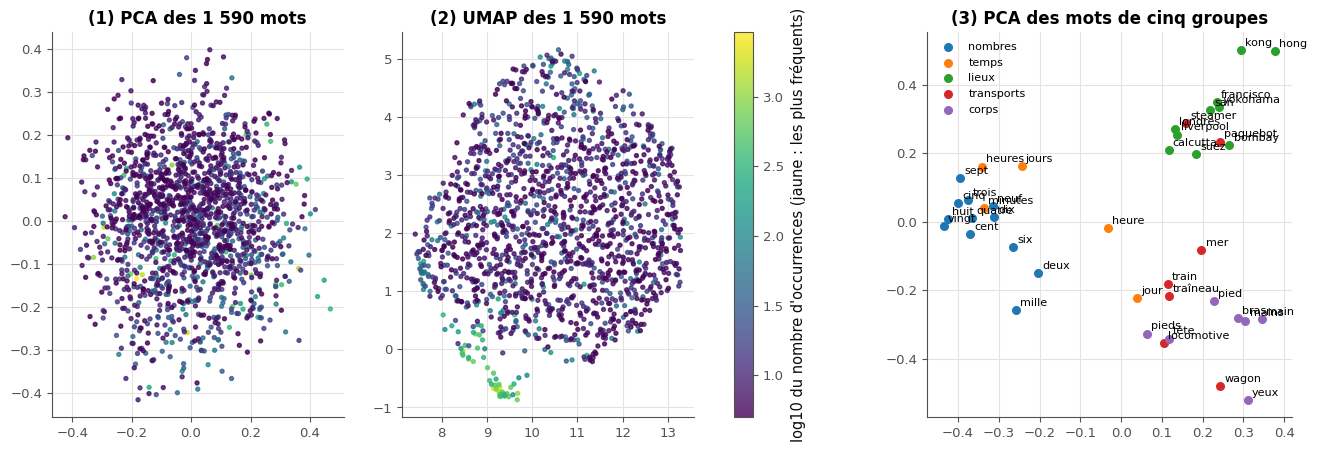

In [59]:
# Five groups of words of Verne, for the third map
GROUPS_27 = {"nombres": "deux trois quatre cinq six sept huit neuf dix vingt cent mille".split(),
             "temps": "heures jours minutes heure jour".split(),
             "lieux": "bombay calcutta londres yokohama hong kong san francisco suez liverpool".split(),
             "transports": "mer paquebot train wagon locomotive traîneau steamer".split(),
             "corps": "mains main tête yeux bras pied pieds".split()}


def maps_27(E, counts, groups, seed=0):
    """The three maps of the figure: PCA of all the words, UMAP of all the words (None without umap-learn), PCA of the
    words of the groups."""
    from sklearn.decomposition import PCA
    pca_all = PCA(2, svd_solver="full").fit_transform(E)
    try:
        import umap
        umap_all = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=seed, n_jobs=1).fit_transform(E)
    except ImportError:
        umap_all = None
        print("⏳ Ex B2.27 : umap-learn n'est pas installé ici : la carte UMAP est « à valider sur Colab ».")
    words = [w for ws in groups.values() for w in ws]
    pca_groups = PCA(2, svd_solver="full").fit_transform(E[[STOI_25[w] for w in words]])
    return pca_all, umap_all, pca_groups, words


if not globals().get("ok_25"):
    print("⏳ Ex B2.27 : les cartes attendent ton word2vec entraîné en B2.25 (les vecteurs E_25).")
else:
    start_27 = time.perf_counter()
    PCA_ALL_27, UMAP_ALL_27, PCA_GROUPS_27, GROUP_WORDS_27 = maps_27(E_25, COUNTS_25, GROUPS_27)
    logf_27 = np.log10(COUNTS_25)
    fig_27, axes_27 = plt.subplots(1, 3, figsize=(16, 5))
    for ax, P, title in ((axes_27[0], PCA_ALL_27, "(1) PCA des 1 590 mots"), (axes_27[1], UMAP_ALL_27, "(2) UMAP des 1 590 mots")):
        if P is None:
            ax.set_axis_off()
            continue
        sc = ax.scatter(P[:, 0], P[:, 1], c=logf_27, cmap="viridis", s=8, alpha=0.8)
        ax.set_title(title)
    fig_27.colorbar(sc, ax=axes_27[:2].tolist(), label="log10 du nombre d'occurrences (jaune : les plus fréquents)")
    colors_27 = plt.get_cmap("tab10")
    k_27 = 0
    for g, (name, ws) in enumerate(GROUPS_27.items()):
        pts = PCA_GROUPS_27[k_27:k_27 + len(ws)]
        axes_27[2].scatter(pts[:, 0], pts[:, 1], color=colors_27(g), label=name, s=30)
        for (x, y), w in zip(pts, ws):
            axes_27[2].annotate(w, (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
        k_27 += len(ws)
    axes_27[2].legend(fontsize=8)
    axes_27[2].set_title("(3) PCA des mots de cinq groupes")
    print(f"Cartes calculées en {fr(time.perf_counter() - start_27, 1)} s.")
    plt.show()

In [60]:
pca_axis_27, umap_frequent_27 = False, True

In [61]:
wb.record("B2.27a", False, mistakes={"suis la couleur de la carte (1) de gauche à droite : passe-t-elle régulièrement du violet au jaune ?": True})
wb.record("B2.27b", True, mistakes={"regarde où sont les points jaunes de la carte (2) : partout, ou surtout à quelques endroits ?": False})

WB_ANSWER {"hash": "4c3afb928b40f6ec32c9d8dfe754f930c1c1c19ea0c6f95e392d99995386561d", "id": "B2.27a", "kind": "bool", "mistakes": {"95f9871f399bcb96c03c777185ca15f3bf5212116ad3c51bb5526a6874e91c47": "suis la couleur de la carte (1) de gauche à droite : passe-t-elle régulièrement du violet au jaune ?"}}
📝 Ex B2.27a : réponse enregistrée (bool).
WB_ANSWER {"hash": "47417484470f08670cbbfce2b74d639be6762462f7e302fd3d2d59ccafc23429", "id": "B2.27b", "kind": "bool", "mistakes": {"037c827a77d0dde7414b87d6a05e03ea7a0caedf78e6699c7a5b73c756ab4dbf": "regarde où sont les points jaunes de la carte (2) : partout, ou surtout à quelques endroits ?"}}
📝 Ex B2.27b : réponse enregistrée (bool).


In [62]:
with wb.attempt("B2.27"):
    wb.check("B2.27a", pca_axis_27)
    wb.check("B2.27b", umap_frequent_27)
if globals().get("ok_25") and filled(pca_axis_27, umap_frequent_27) and "PCA_ALL_27" in globals():
    from scipy.stats import spearmanr
    from sklearn.neighbors import NearestNeighbors
    rho_27 = [spearmanr(PCA_ALL_27[:, j], logf_27)[0] for j in (0, 1)]
    print(f"(1) corrélation de rang entre la fréquence et l'axe horizontal : {fr(rho_27[0], 2)} ; l'axe vertical : {fr(rho_27[1], 2)}.")
    if UMAP_ALL_27 is not None:
        _, near_27 = NearestNeighbors(n_neighbors=11).fit(UMAP_ALL_27).kneighbors(UMAP_ALL_27)
        top_27 = np.arange(len(ITOS_25)) < 100
        share_27 = float(top_27[near_27[top_27, 1:]].mean())
        print(f"(2) les 10 voisins sur la carte des 100 mots les plus fréquents sont aussi parmi les 100 plus fréquents "
              f"{fr(100 * share_27, 0)} fois sur 100 (au hasard : {fr(100 * 100 / len(ITOS_25), 0)}).")
    labels_27 = np.array([g for g, ws in GROUPS_27.items() for _ in ws])
    _, near3_27 = NearestNeighbors(n_neighbors=4).fit(PCA_GROUPS_27).kneighbors(PCA_GROUPS_27)
    print("(3) part des 3 voisins sur la carte qui sont du même groupe : "
          + ", ".join(f"{g} {fr(float((labels_27[near3_27[labels_27 == g, 1:]] == g).mean()), 2)}" for g in GROUPS_27))

✅ Ex B2.27a : Parfait !
✅ Ex B2.27b : Bravo !
(1) corrélation de rang entre la fréquence et l'axe horizontal : 0,14 ; l'axe vertical : -0,23.
(2) les 10 voisins sur la carte des 100 mots les plus fréquents sont aussi parmi les 100 plus fréquents 48 fois sur 100 (au hasard : 6).
(3) part des 3 voisins sur la carte qui sont du même groupe : nombres 0,86, temps 0,27, lieux 0,77, transports 0,29, corps 0,71


## Partie E · Des embeddings de phrases à la livraison, et le défi

Trois exercices sur ce que font les modèles d'aujourd'hui, puis le défi. Tu calcules des embeddings de phrases avec un modèle pré-entraîné pour chercher des passages de Holmes par le sens (B2.28), tu compares un vecteur statique et un vecteur contextuel du même mot (B2.29), tu livres un tokenizer avec son test de non-régression (B2.30), et tu cherches la meilleure compression de Verne avec 2 000 tokens (B2.31).

B2.28 et B2.29 utilisent `all-MiniLM-L6-v2` (`sentence-transformers/all-MiniLM-L6-v2`, ≈ 90 Mo, Apache 2.0, `data/cards/pretrained.md`), chargé une fois à une révision figée, en `eval()` et sans gradient, par `wbtext.try_sentence_model` : `SM_28.tokenizer` et `SM_28.model` sont son tokenizer et son `AutoModel`. Sans connexion au Hub, ces deux exercices affichent ⏳ « à valider sur Colab ».

### Ex B2.28 — Embeddings de phrases (MiniLM, mean pooling) et recherche sémantique dans Holmes 📦 ★★ ⏱️ 30 min
**Objectif :** calculer des embeddings de phrases par mean pooling avec un modèle pré-entraîné, et chercher des passages par le sens.  
**Prérequis :** Ex B2.23 · B1 (embeddings figés, révision fixée) · fiche §202.10 (« D'une suite de vecteurs à un vecteur de phrase », « Une recherche sémantique en vingt lignes ») · **Fil rouge :** Holmes · **Parcours :** R, C

La cellule suivante charge le modèle et découpe Holmes en 1 055 passages d'au plus 120 mots (`PASSAGES_28`, chacun avec l'indice de son conte dans `STORY_28` et `TITLES_28`), tous sous les 256 tokens que lit MiniLM. Elle calcule une fois l'**index** `INDEX_28` : l'embedding de référence de chaque passage, `(1 055, 384)`, rangé dans le cache `data/downloads/embeddings` (≈ 20 s la première fois, une lecture de fichier ensuite).

**Contrat**
- `embed_28(texts, tok, model, batch_size=32, max_length=256)` : un tableau `float32` `(N, 384)`, un embedding par texte, dans l'ordre :
  - les textes passent par mini-batches de `batch_size` dans `tok(..., padding=True, truncation=True, max_length=max_length, return_tensors="pt")`, puis dans `model`, sans gradient ;
  - le **mean pooling avec le masque d'attention** de la fiche, sur `last_hidden_state` : le padding ne compte pas ;
  - chaque embedding ramené à la **norme 1** ;
  - `max_length=256`, la longueur de la fiche modèle (`tok.model_max_length` dit 512 : piège classique de la fiche).
- `search_28(query, index, k=5)` : `(indices, cosinus)` des `k` lignes de `index` les plus proches de la requête (une `str`), que tu embeddes par `embed_28` avec `SM_28.tokenizer` et `SM_28.model`, et que **ton** `most_similar` (B2.23) cherche.

La cellule de vérification compare `embed_28` à la référence sur quatre textes de longueurs différentes (dont un de plus de 256 tokens), vérifie qu'une phrase courte a le même vecteur seule et au milieu de textes longs, puis cherche six requêtes et affiche, pour chacune, les trois passages trouvés, leur cosinus et leur conte.

Dans tes notes : pour chaque requête, le premier passage est-il du bon conte, et contient-il les mots de la requête ? Essaie une requête à toi, puis la même avec d'autres mots : le classement change-t-il ? Les cosinus vont de 0,4 à 0,65 environ : pourquoi un seuil fixe (« pertinent au-dessus de 0,5 ») serait-il fragile, d'une requête à l'autre et d'un modèle à l'autre ? Pour Verne, il faudrait `multilingual-e5-small` et ses préfixes (`wbtext.try_sentence_model("e5")`, `kind="query"` et `"passage"` : ≈ 470 Mo, à essayer sur Colab).

In [63]:
# all-MiniLM-L6-v2 at its frozen revision (eval(), no gradient), the passages of Holmes and their index
SM_28 = wbtext.try_sentence_model("minilm", "B2.28")
PASSAGES_28, STORY_28 = wbtext.holmes_passages()               # 1 055 passages of at most 120 words, and their story
TITLES_28 = [title for title, _ in wbtext.holmes_stories()]
QUERIES_28 = ["a woman whose fiancé vanished on the morning of the wedding",
              "a deadly snake that comes through a ventilator",
              "men with red hair paid to copy out the encyclopaedia",
              "a precious blue stone found in the crop of a Christmas goose",
              "a beggar in the City who is really a respectable gentleman",
              "a governess asked to cut her hair short"]
INDEX_28 = None
if SM_28 is not None:
    start_28 = time.perf_counter()
    INDEX_28 = wbtext.passage_embeddings(SM_28, PASSAGES_28, "holmes-120")   # (1 055, 384), the reference index
    print(f"{SM_28} ; index de {INDEX_28.shape[0]} passages en {fr(time.perf_counter() - start_28, 1)} s.")

ℹ️ embeddings relus dans le cache (sentence-transformers_all-MiniLM-L6-v2-holmes-120-5582e24b55765ff3.npz)
SentenceModel('minilm': sentence-transformers/all-MiniLM-L6-v2 @ 1110a24, d = 384, max_length = 256) ; index de 1055 passages en 0,0 s.


In [64]:
def embed_28(texts, tok, model, batch_size=32, max_length=256):
    """float32 array (N, 384): the sentence embeddings of the texts, mean pooling with the attention mask, norm 1."""
    out = []
    for start in range(0, len(texts), batch_size):
        batch = tok(list(texts[start:start + batch_size]), padding=True, truncation=True, max_length=max_length,
                    return_tensors="pt")
        with torch.inference_mode():
            h = model(**batch).last_hidden_state                    # (B, T, 384)
        m = batch["attention_mask"].unsqueeze(-1).float()           # (B, T, 1)
        out.append(F.normalize((h * m).sum(dim=1) / m.sum(dim=1), dim=1))
    return torch.cat(out).numpy()


def search_28(query, index, k=5):
    """(indices, cosines): the k rows of `index` (passages embedded, norm 1) closest to the query (a str), embedded by
    embed_28 with SM_28, found by your most_similar (B2.23)."""
    q = embed_28([query], SM_28.tokenizer, SM_28.model)[0]
    return mylearn.embeddings.most_similar(index, q, k=k)


if SM_28 is None:
    print("⏳ Ex B2.28 : la vérification attend all-MiniLM-L6-v2 (connexion au Hub, ou Colab).")
else:
    with checked("B2.28"):
        tok_28, model_28 = SM_28.tokenizer, SM_28.model
        texts_28 = [PASSAGES_28[3], "Holmes smiled.", PASSAGES_28[400], " ".join(PASSAGES_28[10:15])]   # the last: > 256 tokens
        got_28 = embed_28(texts_28, tok_28, model_28)
        if not returned("B2.28", "embed_28", got_28):
            raise StopCheck
        want_28 = SM_28.embed(texts_28)
        same("B2.28", "embed_28 de quatre textes de longueurs différentes, dont un de plus de 256 tokens", got_28, want_28,
             rtol=1e-4, atol=1e-5)
        alone_28 = embed_28(["Holmes smiled."], tok_28, model_28)
        verdict("B2.28", np.allclose(np.asarray(alone_28)[0], np.asarray(got_28)[1], atol=1e-5),
                "une phrase courte a le même vecteur seule ou dans un batch avec des textes longs : le masque retire le padding.",
                "« Holmes smiled. » n'a pas le même vecteur seule et dans un batch : le padding entre-t-il dans ta moyenne ?")
        if not np.allclose(got_28, want_28, rtol=1e-4, atol=1e-5) and np.allclose(np.asarray(got_28)[:3], want_28[:3], atol=1e-5):
            print("💡 seul le texte long diffère : max_length = 256, comme la fiche modèle (pas 512).")
        found_28 = search_28(QUERIES_28[0], INDEX_28, k=5)
        if not returned("B2.28", "search_28", found_28):
            raise StopCheck
        idx_28, sims_28 = pair("B2.28", "search_28", found_28, names=("indices", "cosines"))
        ref_28 = np.argsort(-(INDEX_28 @ SM_28.embed(QUERIES_28[0])[0]), kind="stable")[:5]
        verdict("B2.28", np.asarray(idx_28).tolist() == ref_28.tolist(), "search_28 : les 5 passages de la référence, dans l'ordre.",
                f"search_28 : attendu les passages {ref_28.tolist()}, reçu {np.asarray(idx_28).tolist()}.")
        for q in QUERIES_28:
            idx, sims = search_28(q, INDEX_28, k=3)
            print(f"\n« {q} »")
            for i, s in zip(idx, sims):
                print(f"   {fr(float(s), 3)}  {TITLES_28[STORY_28[i]]:<28} {PASSAGES_28[i][:90]}…")

✅ Ex B2.28 : embed_28 de quatre textes de longueurs différentes, dont un de plus de 256 tokens : un tableau (4, 384), comme attendu.
✅ Ex B2.28 : une phrase courte a le même vecteur seule ou dans un batch avec des textes longs : le masque retire le padding.
✅ Ex B2.28 : search_28 : les 5 passages de la référence, dans l'ordre.

« a woman whose fiancé vanished on the morning of the wedding »
   0,646  The Noble Bachelor           “When did she vanish, then?” “At the wedding breakfast.” “Indeed. This is more interesting…
   0,560  The Noble Bachelor           There are rumours of foul play in the matter, and it is said that the police have caused t…
   0,534  The Noble Bachelor           One of the footmen declared that he had seen a lady leave the house thus apparelled, but h…

« a deadly snake that comes through a ventilator »
   0,649  The Speckled Band            My attention was speedily drawn, as I have already remarked to you, to this ventilator, an…
   0,570  The Speckled Band   

### Ex B2.29 — Statique contre contextuel : le même mot dans deux phrases 🔬 ★★ ⏱️ 25 min
**Objectif :** mesurer qu'un embedding statique ignore la phrase, alors qu'un embedding contextuel dépend du sens du mot dans sa phrase.  
**Prérequis :** Ex B2.28 · 🧠 Q11 · fiche §202.10 (« Un mot, plusieurs sens ») · **Fil rouge :** Holmes/Verne · **Parcours :** C

Trois mots anglais à deux sens, chacun dans six phrases (`SENTENCES_29`, prises dans Holmes ou écrites dans son style) : « bank » (la banque, la rive), « match » (l'allumette, le mariage), « ring » (la bague, la sonnerie). Pour chaque emploi, tu prends deux vecteurs de MiniLM : la ligne de sa **table d'entrée** (statique, la même dans toutes les phrases) et la sortie de son **dernier bloc** (contextuelle).

**Contrat**
- `contextual_vector_29(sentence, word, tok, model)` : un tableau NumPy `(384,)`, la moyenne des vecteurs de `last_hidden_state` sur les tokens de la **première occurrence** du mot entier `word` dans `sentence` (un mot entier n'est ni précédé ni suivi d'une lettre, d'un chiffre ou de « _ » : un trait d'union sépare, et « bank » de « bank-note » compte) (un mot de plusieurs tokens, comme « Merryweather », en a plusieurs) ; trouve-les avec les positions que rend `tok(sentence, return_offsets_mapping=True)`, sans les tokens spéciaux ; sans gradient.
- `static_vector_29(word, tok, model)` : `(384,)`, la moyenne des lignes de `model.get_input_embeddings().weight` pour les tokens de `word` (sans tokens spéciaux).
- `sense_means_29(vectors, senses)` : le couple `(moyenne des cosinus des paires d'emplois de même sens, moyenne des cosinus des paires de sens différents)`, deux `float` ; chaque paire d'emplois compte une fois.

La première cellule de vérification compare tes vecteurs à ceux de référence (`SM_29.word_vector`, `SM_29.static_vector`) et `sense_means_29` à un petit calcul visible. La suivante calcule, pour chaque mot, les cosinus des six emplois (une carte de chaleur par mot) et le tableau des moyennes, statiques et contextuelles.

Dans tes notes : que valent les cosinus statiques, et pourquoi n'est-ce pas une mesure ? Pour chaque mot, l'écart entre « même sens » et « sens différents » : lequel des trois sépare le mieux ses deux sens, lequel le moins ? Pourquoi tous les cosinus contextuels sont-ils élevés (au-dessus de 0,6), même entre deux sens ? Que te dit ce chapitre de l'entraînement de MiniLM (pour des phrases entières, §202.10) ?

In [65]:
# Three words with two senses each, six sentences each (taken from Holmes or written in its style)
SENTENCES_29 = {
    "bank": [("argent", "This fellow Merryweather is a bank director, and personally interested in the matter."),
             ("argent", "I was seated in my office at the bank when a card was brought in to me."),
             ("argent", "He had some fourteen thousand pounds, which lay to his credit at the bank."),
             ("rive", "As of the swimmer who leaves the bank, she hurried across the road."),
             ("rive", "He was lying on the grassy bank of the pool, close to the water."),
             ("rive", "The boat was tied to a tree on the bank of the river.")],
    "match": [("allumette", "Holmes sprang from the bed, struck a match, and lashed at the bell-pull."),
              ("allumette", "In her right hand was found the charred stump of a match."),
              ("allumette", "By the light of her match she caught a hurried glimpse of him."),
              ("mariage", "My stepfather has offered no opposition to the match, and we are to be married."),
              ("mariage", "Her father thought it a very good match for her, and gave his consent."),
              ("mariage", "It was a love match, and the wedding was fixed for the spring.")],
    "ring": [("bijou", "He slipped an emerald snake ring from his finger and held it out."),
             ("bijou", "She put a new wedding ring upon the top of the pile."),
             ("bijou", "He wore a heavy gold ring with a large stone on his little finger."),
             ("sonnerie", "There came a ring to my bell, about the hour when a man gives his first yawn."),
             ("sonnerie", "I think that I heard a ring at the door, said Holmes."),
             ("sonnerie", "There was a sharp ring at the bell, and the maid went to open.")]}
SM_29 = SM_28 if "SM_28" in globals() else wbtext.try_sentence_model("minilm", "B2.29")

✅ Ex B2.29 : contextual_vector_29 de « bank » (la première occurrence) : un tableau (384,), comme attendu.
✅ Ex B2.29 : contextual_vector_29 d'un mot de plusieurs tokens (« Merryweather ») : un tableau (384,), comme attendu.
✅ Ex B2.29 : static_vector_29 de « bank » et de « Merryweather » : un tableau (2, 384), comme attendu.
✅ Ex B2.29 : sense_means_29 sur quatre vecteurs du plan (sens a, a, b, b) : [0.35355339, -0.25], comme attendu.


       contextuel, même sens  contextuel, sens différents  statique, même sens  statique, sens différents
mot                                                                                                      
bank                   0.847                        0.749                1.000                      1.000
match                  0.824                        0.803                1.000                      1.000
ring                   0.885                        0.838                1.000                      1.000
✅ Ex B2.29 : le vecteur statique d'un mot est le même dans toutes les phrases : cosinus 1, quel que soit le sens.


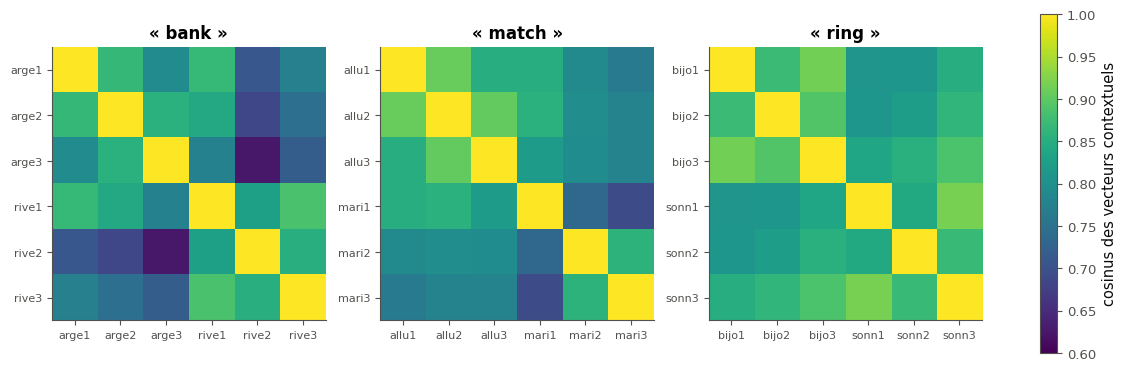

In [66]:
def contextual_vector_29(sentence, word, tok, model):
    """The output of the last block (last_hidden_state) for `word` in `sentence`: the mean of the vectors of the tokens
    of its first occurrence (found with the offsets of the tokenizer), a NumPy array (384,)."""
    start = re.search(rf"\b{re.escape(word)}\b", sentence).start()
    end = start + len(word)
    batch = tok(sentence, return_tensors="pt", return_offsets_mapping=True)
    offsets = batch.pop("offset_mapping")[0].tolist()                 # (start, end) of each token in the sentence
    keep = [k for k, (a, b) in enumerate(offsets) if b > a and a < end and b > start]   # special tokens: (0, 0)
    with torch.inference_mode():
        h = model(**batch).last_hidden_state[0]                       # (T, 384)
    return h[keep].mean(dim=0).numpy()


def static_vector_29(word, tok, model):
    """The row of the input table (model.get_input_embeddings()) of `word`, averaged over its tokens: (384,)."""
    ids = tok(word, add_special_tokens=False)["input_ids"]
    return model.get_input_embeddings().weight[ids].mean(dim=0).detach().numpy()


def sense_means_29(vectors, senses):
    """(mean cosine of the pairs of uses of the SAME sense, mean cosine of the pairs of DIFFERENT senses), two floats."""
    V = np.asarray(vectors, dtype=float)
    V = V / np.linalg.norm(V, axis=1, keepdims=True)
    S = V @ V.T
    i, j = np.triu_indices(len(senses), k=1)                          # each pair of uses once
    same_sense = np.array(senses)[i] == np.array(senses)[j]
    return float(S[i, j][same_sense].mean()), float(S[i, j][~same_sense].mean())


if SM_29 is None:
    print("⏳ Ex B2.29 : l'expérience attend all-MiniLM-L6-v2 (connexion au Hub, ou Colab).")
else:
    with checked("B2.29"):
        tok_29, model_29 = SM_29.tokenizer, SM_29.model
        probe_29 = "The bank-note was found on the bank, near the river."      # two « bank »: the first one counts
        v_29 = contextual_vector_29(probe_29, "bank", tok_29, model_29)
        if not returned("B2.29", "contextual_vector_29", v_29):
            raise StopCheck
        same("B2.29", "contextual_vector_29 de « bank » (la première occurrence)", v_29, SM_29.word_vector(probe_29, "bank"),
             rtol=1e-4, atol=1e-5)
        same("B2.29", "contextual_vector_29 d'un mot de plusieurs tokens (« Merryweather »)",
             contextual_vector_29(SENTENCES_29["bank"][0][1], "Merryweather", tok_29, model_29),
             SM_29.word_vector(SENTENCES_29["bank"][0][1], "Merryweather"), rtol=1e-4, atol=1e-5)
        got_st_29 = np.stack([np.asarray(static_vector_29(w, tok_29, model_29), dtype=float) for w in ("bank", "Merryweather")])
        if not same("B2.29", "static_vector_29 de « bank » et de « Merryweather »", got_st_29,
                    np.stack([SM_29.static_vector(w) for w in ("bank", "Merryweather")]), rtol=1e-5, atol=1e-6):
            table_29 = model_29.get_input_embeddings().weight.detach().numpy()
            with_specials_29 = np.stack([table_29[tok_29(w)["input_ids"]].mean(axis=0) for w in ("bank", "Merryweather")])
            print("💡 Ex B2.29 : " + ("ton vecteur moyenne aussi les lignes de [CLS] et [SEP] : prends les ids du mot sans "
                                     "tokens spéciaux." if np.allclose(got_st_29, with_specials_29, atol=1e-5) else
                                     "le vecteur statique est la moyenne des lignes de la table d'entrée "
                                     "(get_input_embeddings) pour les seuls tokens du mot, pas une sortie du modèle."))
        means_29 = sense_means_29(np.array([[1.0, 0.0], [1.0, 1.0], [0.0, 1.0], [-1.0, 0.0]]), ["a", "a", "b", "b"])
        if returned("B2.29", "sense_means_29", means_29):
            want_29 = (np.mean([math.sqrt(0.5), 0.0]), np.mean([math.sqrt(0.5), -math.sqrt(0.5), 0.0, -1.0]))
            same("B2.29", "sense_means_29 sur quatre vecteurs du plan (sens a, a, b, b)", means_29, want_29)

if SM_29 is not None and written(lambda: contextual_vector_29("a bank", "bank", SM_29.tokenizer, SM_29.model)) \
        and written(lambda: sense_means_29(np.eye(3), ["a", "a", "b"])):
    with checked("B2.29"):
        rows_29 = []
        fig_29, axes_29 = plt.subplots(1, 3, figsize=(15, 4.4))
        for ax, (word, uses) in zip(axes_29, SENTENCES_29.items()):
            senses = [s for s, _ in uses]
            ctx = np.stack([contextual_vector_29(s, word, SM_29.tokenizer, SM_29.model) for _, s in uses])
            stat = np.stack([static_vector_29(word, SM_29.tokenizer, SM_29.model) for _ in uses])
            same_ctx, cross_ctx = sense_means_29(ctx, senses)
            same_st, cross_st = sense_means_29(stat, senses)
            rows_29.append({"mot": word, "contextuel, même sens": same_ctx, "contextuel, sens différents": cross_ctx,
                            "statique, même sens": same_st, "statique, sens différents": cross_st})
            U = ctx / np.linalg.norm(ctx, axis=1, keepdims=True)
            im = ax.imshow(U @ U.T, vmin=0.6, vmax=1.0, cmap="viridis")
            ax.set_xticks(range(6), [f"{s[:4]}{k % 3 + 1}" for k, s in enumerate(senses)], fontsize=8)
            ax.set_yticks(range(6), [f"{s[:4]}{k % 3 + 1}" for k, s in enumerate(senses)], fontsize=8)
            ax.set_title(f"« {word} »")
            ax.grid(False)
        fig_29.colorbar(im, ax=axes_29.tolist(), label="cosinus des vecteurs contextuels")
        table_29 = pd.DataFrame(rows_29).set_index("mot")
        print(table_29.to_string(float_format=lambda x: f"{x:.3f}"))
        verdict("B2.29", np.allclose(table_29[["statique, même sens", "statique, sens différents"]], 1.0),
                "le vecteur statique d'un mot est le même dans toutes les phrases : cosinus 1, quel que soit le sens.",
                "le vecteur statique doit être la même ligne de la table dans toutes les phrases (cosinus 1).")
        plt.show()

### Ex B2.30 — Sauvegarder un tokenizer en JSON et écrire son test de non-régression 🛠️ ★★ ⏱️ 20 min
**Objectif :** livrer un tokenizer comme un artefact versionné, et le protéger par un test de non-régression qui échoue dès qu'il change.  
**Prérequis :** Ex B2.17 · fiche §202.4, §202.5 (« Les tokenizers des modèles, lus dans leur `tokenizer.json` ») · ch. 0A (tests pytest) · **Fil rouge :** Holmes/Verne · **Parcours :** R, C

Un modèle est entraîné avec **un** tokenizer : si ses fusions changent, ses identifiants changent, et le modèle lit n'importe quoi sans le moindre message. En entreprise, le tokenizer est donc livré comme un fichier, à côté des poids, et un **test de non-régression** vérifie qu'il redonne toujours les mêmes identifiants sur un texte de référence figé.

La cellule suivante prépare `TOK_30`, un `BPETokenizer` octet de **ta** librairie, 1 000 tokens appris sur `VERNE_TRAIN` (par `fast_byte_bpe`), le texte de référence `REFERENCE_TEXT_30` (un passage de la validation de Verne, puis « € », un emoji et des idéogrammes), et le dossier de livraison `DELIVERY_30` (à côté de ton notebook dans `mon_travail`, sinon un dossier temporaire).

**Contrat**
- `deliver_30(tok, folder, reference_text)` : écrit `folder/tokenizer.json` (par `tok.save`, fourni) et `folder/golden.json`, un dictionnaire JSON qui contient au moins `"text"` (le texte de référence) et `"ids"` (ses identifiants figés), et ce que ton test veut vérifier d'autre ; rend le couple de leurs chemins `(tokenizer.json, golden.json)`.
- `test_tokenizer_regression_30()` : un test pytest qui recharge le tokenizer par `BPETokenizer.load(TOKENIZER_PATH)`, puis vérifie avec des `assert` que l'encodage du texte de `GOLDEN_PATH` redonne les ids figés, que leur décodage redonne le texte, et que la taille du vocabulaire (`len(tok.vocab_)`, le nombre de tokens du tokenizer) n'a pas changé. `BPETokenizer`, `TOKENIZER_PATH`, `GOLDEN_PATH`, `json` et `Path` sont fournis au test, qui tourne dans un fichier à part (`wb.run_pytest`) : il ne doit pas lire d'autre variable du notebook.

La cellule de vérification livre `TOK_30`, relit les deux fichiers, puis lance ton test sur le tokenizer livré (il doit passer) et sur trois copies abîmées de `tokenizer.json` (il doit échouer sur chacune).

Dans tes notes : quels fichiers committerais-tu à côté des poids d'un modèle, et pourquoi le texte de référence contient-il des accents, un emoji et des idéogrammes ? Une des trois copies abîmées donne les mêmes ids pour presque tous les textes : laquelle, et qu'est-ce qui, dans ton test, la trahit ? Quand faut-il **régénérer** `golden.json`, et qui doit le décider ?

In [67]:
# The tokenizer to deliver: a byte-level BPE of 1 000 tokens of your library, learned on VERNE_TRAIN, and the frozen
# reference text of its non-regression test (French, emoji, ideographs, a « € »)
import tempfile
from pathlib import Path

REFERENCE_TEXT_30 = VERNE_VAL[:1500] + "\n« Ça coûte 15 € », dit-il 🙂 漢字.\n"
_here_30 = Path.cwd().resolve()
DELIVERY_30 = (_here_30 / "livraison_b2_30") if "mon_travail" in _here_30.parts else Path(tempfile.mkdtemp(prefix="wb_b2_30_"))
TOK_30 = fast_byte_bpe(VERNE_TRAIN, 1000) if bpe_written() and bpe_rebuild_ok("B2.30") else None
LIBRARY_30 = None
if TOK_30 is not None:                       # where the test file imports BPETokenizer from: your library
    _package_30 = Path(mylearn.tokenizer.__file__).resolve().parent    # mon_travail/mylearn (or the reference)
    LIBRARY_30 = (str(_package_30.parent), f"{_package_30.name}.tokenizer")
print(f"Dossier de livraison : {DELIVERY_30}")


def broken_copies_30(folder):
    """Three broken copies of the delivered tokenizer.json (for the check): two merges swapped, the last merge removed,
    the pre-tokenizer changed. Returns {description: path}."""
    state = json.loads((Path(folder) / "tokenizer.json").read_text(encoding="utf-8"))
    out = {}
    for name, change in (("deux fusions échangées", lambda s: s["merges"].__setitem__(slice(10, 12), s["merges"][10:12][::-1])),
                         ("la dernière fusion retirée", lambda s: s["merges"].pop()),
                         ("le pré-tokenizer 'whitespace' au lieu de 'gpt2'", lambda s: s["params"].__setitem__("pre_tokenizer", "whitespace"))):
        broken = json.loads(json.dumps(state))
        change(broken)
        target = Path(tempfile.mkdtemp(prefix="wb_b2_30_broken_")) / "tokenizer.json"
        target.write_text(json.dumps(broken), encoding="utf-8")
        out[name] = target
    return out

Dossier de livraison : /tmp/wb_b2_30_u2oaa_t7


In [68]:
def deliver_30(tok, folder, reference_text):
    """Write folder/tokenizer.json (tok.save) and folder/golden.json ({"text": reference_text, "ids": its ids}); return
    (path of tokenizer.json, path of golden.json)."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    tok_path, golden_path = folder / "tokenizer.json", folder / "golden.json"
    tok.save(tok_path)
    golden = {"text": reference_text, "ids": tok.encode(reference_text), "vocab_size": len(tok.vocab_)}
    golden_path.write_text(json.dumps(golden, ensure_ascii=False), encoding="utf-8")
    return tok_path, golden_path


def test_tokenizer_regression_30():
    """The non-regression test: BPETokenizer.load(TOKENIZER_PATH) must give the frozen ids of GOLDEN_PATH, decode them back
    to the text, and keep its vocabulary size (len(vocab_))."""
    tok = BPETokenizer.load(TOKENIZER_PATH)
    golden = json.loads(Path(GOLDEN_PATH).read_text(encoding="utf-8"))
    ids = tok.encode(golden["text"])
    assert len(tok.vocab_) == golden["vocab_size"], f"expected {golden['vocab_size']} tokens, got {len(tok.vocab_)}"
    first = next((k for k, (a, b) in enumerate(zip(ids, golden["ids"])) if a != b), None)
    assert ids == golden["ids"], f"expected the frozen ids; first difference at position {first}"
    assert tok.decode(ids) == golden["text"], "expected decode(encode(text)) == text"


import inspect

if TOK_30 is None:
    print("⏳ Ex B2.30 : la livraison attend ton BPETokenizer (B2.16 et B2.17), sans état privé posé par fit "
          "(la ligne ❌ de la cellule précédente, s'il y en a une).")
else:
    with checked("B2.30"):
        paths_30 = deliver_30(TOK_30, DELIVERY_30, REFERENCE_TEXT_30)
        if not returned("B2.30", "deliver_30", paths_30):
            raise StopCheck
        tok_path_30, golden_path_30 = (Path(p) for p in pair("B2.30", "deliver_30", paths_30, names=("tokenizer.json", "golden.json")))
        reloaded_30 = type(TOK_30).load(tok_path_30)
        golden_30 = json.loads(golden_path_30.read_text(encoding="utf-8"))
        verdict("B2.30", reloaded_30.merges_ == TOK_30.merges_ and golden_30.get("text") == REFERENCE_TEXT_30
                and golden_30.get("ids") == TOK_30.encode(REFERENCE_TEXT_30),
                f"livraison : {tok_path_30.name} se recharge à l'identique, {golden_path_30.name} contient le texte et ses "
                f"{len(golden_30.get('ids', []))} ids figés.",
                "tokenizer.json doit se recharger avec BPETokenizer.load, et golden.json contenir le texte de référence "
                "(clé 'text') et ses ids (clé 'ids').")
    if "NotImplementedError" in inspect.getsource(test_tokenizer_regression_30):
        print("⏳ Ex B2.30 : écris ton test de non-régression.")
    elif "tok_path_30" in globals():
        def preamble_30(tok_path):
            return (f"import json\nimport sys\nfrom pathlib import Path\nsys.path.insert(0, {LIBRARY_30[0]!r})\n"
                    f"from {LIBRARY_30[1]} import BPETokenizer\nTOKENIZER_PATH = {str(tok_path)!r}\n"
                    f"GOLDEN_PATH = {str(golden_path_30)!r}")
        print("Ton test, sur le tokenizer livré (il doit passer) :")
        good_30 = wb.run_pytest([test_tokenizer_regression_30], preamble=preamble_30(tok_path_30))
        verdict("B2.30", good_30.ok, "ton test passe sur le tokenizer livré.", "ton test doit passer sur le tokenizer livré "
                "(la sortie de pytest est au-dessus).")
        for why_30, path_30 in (broken_copies_30(DELIVERY_30).items() if good_30.ok else ()):
            caught_30 = not wb.run_pytest([test_tokenizer_regression_30], preamble=preamble_30(path_30), quiet=True).ok
            verdict("B2.30", caught_30, f"ton test attrape un tokenizer.json abîmé : {why_30}.",
                    f"ton test laisse passer un tokenizer.json abîmé : {why_30}.")

✅ Ex B2.30 : livraison : tokenizer.json se recharge à l'identique, golden.json contient le texte et ses 640 ids figés.
Ton test, sur le tokenizer livré (il doit passer) :


pytest : 1 passed in 0.10s
✅ Ex B2.30 : ton test passe sur le tokenizer livré.


✅ Ex B2.30 : ton test attrape un tokenizer.json abîmé : deux fusions échangées.


✅ Ex B2.30 : ton test attrape un tokenizer.json abîmé : la dernière fusion retirée.


✅ Ex B2.30 : ton test attrape un tokenizer.json abîmé : le pré-tokenizer 'whitespace' au lieu de 'gpt2'.


### Ex B2.31 — Défi : la meilleure compression sans perte de Verne avec 2 000 tokens, en moins de 2 min de CPU 🏆 ★★★★ ⏱️ 90 min
**Objectif :** trouver, avec ce que le chapitre a montré, un tokenizer de 2 000 tokens qui compresse Verne nettement mieux que le BPE de B2.20.  
**Prérequis :** Ex B2.20, B2.21 · fiche §202.3 à §202.6 · tout le chapitre · **Fil rouge :** Verne · **Parcours :** C

En B2.20, un BPE octet de 2 000 tokens avec le pré-tokenizer `'gpt2'`, appliqué par rang, a fait **3,001 octets par token** sur `VERNE_VAL`. Le défi : **au moins 3,20**, toujours **sans perte**, avec **2 000 tokens au plus** et en **moins de 2 minutes** de CPU.

Écris `method_31(text)` : elle reçoit `VERNE_TRAIN` et rend un tokenizer, un objet qui a :
- `vocab_` : un dictionnaire `{id: bytes}` d'au plus 2 000 entrées, tokens spéciaux compris (celui de ton `BPETokenizer` convient) ;
- `encode(text)` : la liste des ids du texte, tous des clés de `vocab_` ;
- `decode(ids)` : le texte.

Tout est permis : ton `BPETokenizer`, la bibliothèque `tokenizers`, d'autres pré-tokenizers, une autre façon d'appliquer un vocabulaire, une idée à toi. `evaluate_31(method_31)` (cellule suivante) vérifie quatre règles :
1. **2 000 tokens au plus** dans `vocab_` ;
2. **sans perte** : les octets des tokens, mis bout à bout, redonnent exactement la validation, et `decode` aussi : un id vaut toujours les mêmes octets, quel que soit son voisinage ;
3. **rien de la validation** : ta méthode n'apprend que sur le texte qu'elle reçoit. Pendant la course, toutes les variables globales qui contiennent la validation (`VERNE_VAL` et celles des exercices précédents) valent un leurre, `wbtext` ne rend que le texte d'entraînement de Verne, et un token de 4 octets ou plus qui serait dans la validation mais nulle part dans `VERNE_TRAIN` est signalé. Puis un **contrôle** : la même méthode, apprise sur les 8/9 de `VERNE_TRAIN`, est mesurée sur le dernier neuvième ; elle doit y gagner autant sur le BPE de B2.20 que sur la validation (2 points d'écart au plus), et aucun de ses tokens de 4 octets ou plus ne doit venir du neuvième tenu à l'écart ;
4. **moins de 2 minutes** pour l'entraînement et l'encodage, mesurés ensemble et **à froid** : sur la validation, et aussi sur le contrôle, un texte que ta méthode n'a jamais vu (un entraînement fait d'avance, dans une autre cellule, ne compte pas).

Puis elle affiche ton score : les octets UTF-8 de la validation divisés par son nombre de tokens. Règle d'honneur : la validation sert à mesurer, jamais à apprendre.

Dans tes notes : tes idées, leur gain sur la validation et leur temps ; ce que coûterait ta méthode à un modèle de langue (la longueur des séquences, la table d'embedding, les tokens rares, B2.20) ; et pourquoi un tokenizer qui compresse mieux n'est pas toujours un meilleur tokenizer.

In [69]:
# The challenge: the best lossless compression of VERNE_VAL with at most 2 000 tokens, in less than 2 minutes of CPU
GOAL_31, LIMIT_31, MAX_TOKENS_31 = 3.20, 120.0, 2000     # bytes per token to reach; seconds; tokens (special included)
BASELINE_31 = 3.001        # B2.20: byte-level BPE 'gpt2' of 2 000 tokens, by rank, learned on VERNE_TRAIN, on VERNE_VAL
BASELINE_CONTROL_31 = 2.955   # the same BPE learned on the first 8/9 of VERNE_TRAIN, on its last ninth (the control)


def _make_evaluate_31(validation, train):
    """evaluate_31, with the validation text and the control text kept here only (the global variables that hold them
    are replaced by a decoy while your method runs)."""
    cut = wbtext.split_point(train, 8 / 9)
    texts = {"validation": (validation, train), "contrôle": (train[cut:], train[:cut])}   # name: (measured, learned on)
    decoy = " ".join(sorted(set(train.split()))[:6000])       # words of the training text, in alphabetical order

    def marker(text):
        at = next(i for i in range(1000, len(text)) if not set(text[i:i + 60]) & set("\n'\"\\"))
        return text[at:at + 60]                                 # a piece of the text, the same in a repr

    def holds(value, markers):
        try:
            if isinstance(value, (bytes, bytearray)):
                return any(m.encode("utf-8") in value for m in markers)
            shown = value if isinstance(value, str) else str(value)[:5_000_000]
        except Exception:  # noqa: BLE001 - an object without a readable str
            return False
        return any(m in shown for m in markers)

    def foreign(vocab, measured, learned):
        """The tokens of 4 bytes or more found in the measured text but nowhere in the text the method received."""
        measured, learned = measured.encode("utf-8"), learned.encode("utf-8")
        return sorted({b for b in vocab.values() if isinstance(b, bytes) and len(b) >= 4 and b in measured
                       and b not in learned}, key=lambda b: (-len(b), b))

    def run(method, name):
        """Train the method on the text that goes with `name` and encode the text measured, the global variables that
        hold a measured text being replaced by the decoy, and wbtext giving only the text learned on. Returns
        (tokenizer, ids, seconds), or None."""
        g = globals()
        measured, learned = texts[name]
        markers = [marker(validation)] + ([marker(measured)] if name == "contrôle" else [])
        hidden = {n: v for n, v in list(g.items()) if not n.startswith("_")
                  and isinstance(v, (str, bytes, bytearray, dict, list, tuple)) and holds(v, markers)}
        load_text, load_verne, cached = wbtext.load_text, wbtext.datasets.load_verne, wbtext._TEXTS.get("verne")
        try:
            for n, v in hidden.items():
                g[n] = decoy.encode("utf-8") if isinstance(v, (bytes, bytearray)) else decoy
            # the other paths to Verne (wbtext, wb.datasets) give only the text learned on during the run
            wbtext.load_text = lambda text_name, _load=load_text: learned if text_name == "verne" else _load(text_name)
            wbtext.datasets.load_verne = lambda *args, **kwargs: learned
            wbtext._TEXTS["verne"] = learned
            start = time.perf_counter()
            tok = method(learned)
            fit_seconds = time.perf_counter() - start
            vocab = getattr(tok, "vocab_", None)
            if not isinstance(vocab, dict) or not vocab or not all(isinstance(b, bytes) for b in vocab.values()):
                print("❌ Ex B2.31 : le tokenizer rendu doit avoir un vocab_, un dict {id: bytes} (comme ton BPETokenizer).")
                return None
            start = time.perf_counter()
            ids = tok.encode(measured)
            return tok, ids, fit_seconds + time.perf_counter() - start
        finally:
            for n, v in hidden.items():
                g[n] = v
            wbtext.load_text, wbtext.datasets.load_verne = load_text, load_verne
            if cached is None:
                wbtext._TEXTS.pop("verne", None)
            else:
                wbtext._TEXTS["verne"] = cached

    def evaluate_31(method):
        """method(text) -> tokenizer: the four rules of the statement, then the bytes per token on the validation."""
        out = run(method, "validation")
        if out is None:
            return None
        tok, ids, seconds = out
        vocab, val_bytes = tok.vocab_, validation.encode("utf-8")
        if not isinstance(ids, list) or not ids or not all(isinstance(i, (int, np.integer)) and i in vocab for i in ids):
            print("❌ Ex B2.31 : encode doit rendre une liste d'ids entiers, tous des clés de vocab_.")
            return None
        lossless = b"".join(vocab[i] for i in ids) == val_bytes
        decoded = tok.decode(ids) == validation if hasattr(tok, "decode") else False
        score = len(val_bytes) / len(ids)
        print(f"{len(vocab)} tokens ; validation : {len(ids):_} tokens pour {len(val_bytes):_} octets, soit {fr(score, 3)} "
              f"octets par token ; entraînement + encodage : {fr(seconds, 1)} s.".replace("_", " "))
        verdict("B2.31", len(vocab) <= MAX_TOKENS_31, f"{len(vocab)} tokens, au plus {MAX_TOKENS_31}.",
                f"{len(vocab)} tokens dans vocab_ : le défi en permet {MAX_TOKENS_31}, tokens spéciaux compris.")
        verdict("B2.31", lossless and decoded, "sans perte : les octets des tokens redonnent la validation, et decode aussi.",
                "pas sans perte : " + ("les octets des tokens, mis bout à bout, ne redonnent pas la validation" if not lossless
                                       else "decode(ids) ne redonne pas la validation") + ".")
        # rule 3: tokens seen only in the validation, then the control (the same method, learned without the last
        # ninth of VERNE_TRAIN, measured on it)
        unseen = foreign(vocab, validation, train)
        verdict("B2.31", not unseen, "aucun token de 4 octets ou plus n'est dans la validation sans être dans VERNE_TRAIN.",
                f"{len(unseen)} token(s) de 4 octets ou plus sont dans la validation mais nulle part dans VERNE_TRAIN, le "
                f"texte que reçoit ta méthode (le plus long : {unseen[0].decode('utf-8', errors='replace')!r}) : d'où "
                "viennent-ils ?" if unseen else "")
        honest, c_seconds, control = False, None, run(method, "contrôle")
        if control is not None:
            (measured, learned), (c_tok, c_ids, c_seconds) = texts["contrôle"], control
            if isinstance(c_ids, list) and c_ids and b"".join(c_tok.vocab_.get(i, b"?") for i in c_ids) == measured.encode("utf-8"):
                gain, c_gain = score / BASELINE_31, len(measured.encode("utf-8")) / len(c_ids) / BASELINE_CONTROL_31
                c_unseen = foreign(c_tok.vocab_, measured, learned)
                honest = gain - c_gain <= 0.02 and not c_unseen
                if c_unseen:
                    print(f"❌ Ex B2.31 : contrôle : {len(c_unseen)} token(s) de 4 octets ou plus sont dans le texte tenu à "
                          "l'écart mais nulle part dans le texte que ta méthode a reçu : apprend-elle sur autre chose que "
                          "son argument (VERNE_TRAIN lu par une variable globale, un fichier) ?")
                else:
                    verdict("B2.31", honest, f"contrôle : sur un texte tenu à l'écart, ta méthode gagne autant sur la "
                            f"référence de B2.20 ({fr(100 * (c_gain - 1), 1)} %) que sur la validation "
                            f"({fr(100 * (gain - 1), 1)} %).",
                            f"contrôle : ta méthode gagne {fr(100 * (gain - 1), 1)} % sur la validation, mais seulement "
                            f"{fr(100 * (c_gain - 1), 1)} % sur un texte tenu à l'écart : apprend-elle autre chose que le "
                            "texte qu'elle reçoit (la validation, une variable globale) ?")
            else:
                print("❌ Ex B2.31 : contrôle : sur le texte tenu à l'écart, ta méthode n'est pas sans perte.")
        # rule 4, measured cold: the control is a text the method has never seen, so it trains there for real
        slowest = max(seconds, c_seconds if c_seconds is not None else 0.0)
        verdict("B2.31", slowest <= LIMIT_31,
                f"en {fr(seconds, 1)} s sur la validation et {fr(c_seconds or 0.0, 1)} s sur le contrôle, chacun sous les "
                f"{LIMIT_31:.0f} s.",
                f"{fr(seconds, 1)} s sur la validation, {fr(c_seconds or 0.0, 1)} s sur le contrôle : le défi en permet "
                f"{LIMIT_31:.0f} à chacun (entraînement + encodage).")
        ok = len(vocab) <= MAX_TOKENS_31 and lossless and decoded and not unseen and slowest <= LIMIT_31 and honest
        verdict("B2.31", ok and score >= GOAL_31, f"défi réussi : {fr(score, 3)} octets par token (objectif {fr(GOAL_31, 2)}, "
                f"référence de B2.20 {fr(BASELINE_31, 3)}).",
                f"pas encore : {fr(score, 3)} octets par token, il en faut {fr(GOAL_31, 2)} en respectant les quatre règles.")
        return {"bytes_per_token": score, "seconds": seconds, "control_seconds": c_seconds, "tokens": len(vocab),
                "honest": honest and not unseen, "ok": ok and score >= GOAL_31}

    return evaluate_31


evaluate_31 = _make_evaluate_31(VERNE_VAL, VERNE_TRAIN)

In [70]:
from tokenizers import Tokenizer, models, pre_tokenizers, trainers


def gpt2_byte_table():
    """GPT-2's table byte -> printable character (fiche §202.4), used by the ByteLevel pre-tokenizer of tokenizers."""
    keep = list(range(ord("!"), ord("~") + 1)) + list(range(ord("¡"), ord("¬") + 1)) + list(range(ord("®"), ord("ÿ") + 1))
    chars, extra = {}, 0
    for b in range(256):
        if b in keep:
            chars[b] = chr(b)
        else:
            chars[b] = chr(256 + extra)
            extra += 1
    return chars


class LinesTokenizer31:
    """A byte-level vocabulary, applied by the shortest segmentation (dynamic programming)."""

    def __init__(self, vocab):
        self.vocab_ = dict(vocab)
        self._index = {b: i for i, b in sorted(self.vocab_.items(), reverse=True)}   # the smallest id for a duplicate
        self._longest = max(len(b) for b in self.vocab_.values())

    def encode(self, text):
        data = text.encode("utf-8")
        n, best, back = len(data), [0] + [math.inf] * len(data), [None] * (len(data) + 1)
        for i in range(n):                                    # best[j]: fewest tokens for the first j bytes
            step = best[i] + 1
            for j in range(i + 1, min(n, i + self._longest) + 1):
                token = self._index.get(data[i:j])
                if token is not None and step < best[j]:
                    best[j], back[j] = step, (i, token)
        ids, j = [], n
        while j:
            i, token = back[j]
            ids.append(token)
            j = i
        return ids[::-1]

    def decode(self, ids):
        return b"".join(self.vocab_[i] for i in ids).decode("utf-8", errors="replace")


def method_31(text):
    """Your method: learn on `text` (VERNE_TRAIN) ONLY a tokenizer with vocab_ ({id: bytes}, at most 2 000 entries),
    encode(text) -> list of ids and decode(ids) -> str, lossless."""
    # 1. no pre-tokenization inside a line: merges may cross the spaces (« de la », « Phileas Fogg »)
    hf = Tokenizer(models.BPE())
    hf.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False, use_regex=False)
    trainer = trainers.BpeTrainer(vocab_size=MAX_TOKENS_31, min_frequency=2, show_progress=False,
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    hf.train_from_iterator(text.splitlines(keepends=True), trainer)
    to_byte = {c: b for b, c in gpt2_byte_table().items()}
    vocab = {i: bytes(to_byte[c] for c in s) for s, i in hf.get_vocab().items()}
    # 2. the shortest segmentation with this vocabulary, instead of the merges applied by rank
    return LinesTokenizer31(vocab)


with checked("B2.31"):
    need("B2.31", "method_31")
    result_31 = evaluate_31(method_31)

2000 tokens ; validation : 12 602 tokens pour 43 315 octets, soit 3,437 octets par token ; entraînement + encodage : 1,0 s.
✅ Ex B2.31 : 2000 tokens, au plus 2000.
✅ Ex B2.31 : sans perte : les octets des tokens redonnent la validation, et decode aussi.
✅ Ex B2.31 : aucun token de 4 octets ou plus n'est dans la validation sans être dans VERNE_TRAIN.


✅ Ex B2.31 : contrôle : sur un texte tenu à l'écart, ta méthode gagne autant sur la référence de B2.20 (14,4 %) que sur la validation (14,5 %).
✅ Ex B2.31 : en 1,0 s sur la validation et 0,9 s sur le contrôle, chacun sous les 120 s.
✅ Ex B2.31 : défi réussi : 3,437 octets par token (objectif 3,20, référence de B2.20 3,001).


## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu compter les octets et les points de code d'un texte, et écrire un caractère en UTF-8 ?
2. Sais-tu dérouler un entraînement BPE à la main, départage compris, puis encoder un mot nouveau par rang ?
3. Sais-tu dire quelles lignes d'une table d'embedding reçoivent un gradient, et calculer une PPMI ?
4. Sais-tu chiffrer ce que coûtent une table d'embedding et un texte selon sa langue ?

**Pour aller plus loin** : le chapitre 6 du cours LLM de Hugging Face et `minbpe` d'A. Karpathy, cités dans la fiche. La suite : le bonus B3, attention et Transformers.